In [1]:
# https://colab.research.google.com/drive/1O4G_gaJRtchEjzEy4HiCviRLZqusgahr

# Імпорт необхідних бібліотек

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max.rows',130)
pd.set_option('display.max.columns',130)
pd.set_option('float_format', '{:.2f}'.format)

# Імпорт даних

Вмонтуємо наш диск, якщо Ви працюєте в Google Colab. Якщо працюєте локально, пропустіть наступну клітинку.

In [3]:
# from google.colab import drive
# drive.mount('/content/drive')

Знайдемо, де лежать наші файли з даними. В мене вони знаходяться тут:

In [4]:
# !ls drive/MyDrive/Machine\ Learning\ для\ людей/data/credit

Зчитуємо дані.

In [5]:
# df = pd.read_csv("drive/MyDrive/Machine Learning для людей/data/credit/application_data.csv.zip")
df = pd.read_csv(".eda/application_data.csv.zip")
# індекси заявників з XNA у CODE_GENDER - фіксуємо одразу після завантаження, до обробки даних,
# щоб у ДЗ 8 виключити їх з порівняння F і M (повторний запуск обробки df їх не змінить)
gender_xna_idx = df.index[df['CODE_GENDER'] == 'XNA']

In [6]:
# Огляд декількох записів з датафрейму
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.00,406597.50,24700.50,351000.00,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.02,-9461,-637,-3648.00,-2120,NaN,1,1,0,1,1,0,Laborers,1.00,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.08,0.26,0.14,0.02,0.04,0.97,0.62,0.01,0.00,0.07,0.08,0.12,0.04,0.02,0.02,0.00,0.00,0.03,0.04,0.97,0.63,0.01,0.00,0.07,0.08,0.12,0.04,0.02,0.02,0.00,0.00,0.03,0.04,0.97,0.62,0.01,0.00,0.07,0.08,0.12,0.04,0.02,0.02,0.00,0.00,reg oper account,block of flats,0.01,"Stone, brick",No,2.00,2.00,2.00,2.00,-1134.00,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,1.00
1,100003,0,Cash loans,F,N,N,0,270000.00,1293502.50,35698.50,1129500.00,Family,State servant,Higher education,Married,House / apartment,0.00,-16765,-1188,-1186.00,-291,NaN,1,1,0,1,1,0,Core staff,2.00,1,1,MONDAY,11,0,0,0,0,0,0,School,0.31,0.62,NaN,0.10,0.05,0.99,0.80,0.06,0.08,0.03,0.29,0.33,0.01,0.08,0.05,0.00,0.01,0.09,0.05,0.99,0.80,0.05,0.08,0.03,0.29,0.33,0.01,0.08,0.06,0.00,0.00,0.10,0.05,0.99,0.80,0.06,0.08,0.03,0.29,0.33,0.01,0.08,0.06,0.00,0.01,reg oper account,block of flats,0.07,Block,No,1.00,0.00,1.00,0.00,-828.00,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00
2,100004,0,Revolving loans,M,Y,Y,0,67500.00,135000.00,6750.00,135000.00,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.01,-19046,-225,-4260.00,-2531,26.00,1,1,1,1,1,0,Laborers,1.00,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.56,0.73,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,0.00,0.00,0.00,-815.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.0

# Перевірка структури даних

In [7]:
# df.info(verbose = True, null_counts = True)
df.info(verbose = True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Data columns (total 122 columns):
 #    Column                        Non-Null Count   Dtype  
---   ------                        --------------   -----  
 0    SK_ID_CURR                    307511 non-null  int64  
 1    TARGET                        307511 non-null  int64  
 2    NAME_CONTRACT_TYPE            307511 non-null  object 
 3    CODE_GENDER                   307511 non-null  object 
 4    FLAG_OWN_CAR                  307511 non-null  object 
 5    FLAG_OWN_REALTY               307511 non-null  object 
 6    CNT_CHILDREN                  307511 non-null  int64  
 7    AMT_INCOME_TOTAL              307511 non-null  float64
 8    AMT_CREDIT                    307511 non-null  float64
 9    AMT_ANNUITY                   307499 non-null  float64
 10   AMT_GOODS_PRICE               307233 non-null  float64
 11   NAME_TYPE_SUITE               306219 non-null  object 
 12   NAME_INCOME_TYPE            

In [8]:
df.shape

(307511, 122)

Маємо ~307k рядків та 122 колонки.

## Статистичний звіт для числових змінних

In [9]:
df.describe()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,TOTALAREA_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.00,307511.00,307511.00,307511.00,307511.00,307499.00,307233.00,307511.00,307511.00,307511.00,307511.00,307511.00,104582.00,307511.00,307511.00,307511.00,307511.00,307511.00,307511.00,307509.00,307511.00,307511.00,307511.00,307511.00,307511.00,307511.00,307511.00,307511.00,307511.00,134133.00,306851.00,246546.00,151450.00,127568.00,157504.00,103023.00,92646.00,143620.00,152683.00,154491.00,98869.00,124921.00,97312.00,153161.00,93997.00,137829.00,151450.00,127568.00,157504.00,103023.00,92646.00,143620.00,152683.00,154491.00,98869.00,124921.00,97312.00,153161.00,93997.00,137829.00,151450.00,127568.00,157504.00,103023.00,92646.00,143620.00,152683.00,154491.00,98869.00,124921.00,97312.00,153161.00,93997.00,137829.00,159080.00,306490.00,306490.00,306490.00,306490.00,307510.00,307511.00,307511.00,307511.00,307511.00,307511.00,307511.00,307511.00,307511.00,307511.00,307511.00,307511.00,307511.00,307511.00,307511.00,307511.00,307511.00,307511.00,307511.00,307511.00,307511.00,265992.00,265992.00,265992.00,265992.00,265992.00,265992.00
mean,278180.52,0.08,0.42,168797.92,599026.00,27108.57,538396.21,0.02,-16037.00,63815.05,-4986.12,-2994.20,12.06,1.00,0.82,0.20,1.00,0.28,0.06,2.15,2.05,2.03,12.06,0.02,0.05,0.04,0.08,0.23,0.18,0.50,0.51,0.51,0.12,0.09,0.98,0.75,0.04,0.08,0.15,0.23,0.23,0.07,0.10,0.11,0.01,0.03,0.11,0.09,0.98,0.76,0.04,0.07,0.15,0.22,0.23,0.06,0.11,0.11,0.01,0.03,0.12,0.09,0.98,0.76,0.04,0.08,0.15,0.23,0.23,0.07,0.10,0.11,0.01,0.03,0.10,1.42,0.14,1.41,0.10,-962.86,0.00,0.71,0.00,0.02,0.09,0.00,0.08,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.01,0.00,0.01,0.00,0.00,0.00,0.01,0.01,0.03,0.27,0.27,1.90
std,102790.18,0.27,0.72,237123.15,402490.78,14493.74,369446.46,0.01,4363.99,141275.77,3522.89,1509.45,11.94,0.00,0.38,0.40,0.04,0.45,0.23,0.91,0.51,0.50,3.27,0.12,0.22,0.20,0.27,0.42,0.38,0.21,0.19,0.19,0.11,0.08,0.06,0.11,0.08,0.13,0.10,0.14,0.16,0.08,0.09,0.11,0.05,0.07,0.11,0.08,0.06,0.11,0.07,0.13,0.10,0.14,0.16,0.08,0.10,0.11,0.05,0.07,0.11,0.08,0.06,0.11,0.08,0.13,0.10,0.15,0.16,0.08,0.09,0.11,0.05,0.07,0.11,2.40,0.45,2.38,0.36,826.81,0.

# Аналіз категоріальних змінних

In [10]:
df.select_dtypes(include = "object").columns

Index(['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
       'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE',
       'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE',
       'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE',
       'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE'],
      dtype='object')

In [11]:
# Перевірка кількості категоріальних змінних
len(df.select_dtypes(include = "object").columns)

16

Дані містять 16 `categorical` змінних

# Аналіз числових змінних

In [12]:
number_df = df.select_dtypes(include="number")

In [13]:
number_df.columns

Index(['SK_ID_CURR', 'TARGET', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL',
       'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE',
       'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED',
       ...
       'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20',
       'FLAG_DOCUMENT_21', 'AMT_REQ_CREDIT_BUREAU_HOUR',
       'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK',
       'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT',
       'AMT_REQ_CREDIT_BUREAU_YEAR'],
      dtype='object', length=106)

In [14]:
# Перевірка кількості числових змінних
len(number_df.columns)

106

Дані міcтять 106 `numerical` змінних

In [15]:
number_df.head()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,TOTALAREA_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,0,202500.00,406597.50,24700.50,351000.00,0.02,-9461,-637,-3648.00,-2120,NaN,1,1,0,1,1,0,1.00,2,2,10,0,0,0,0,0,0,0.08,0.26,0.14,0.02,0.04,0.97,0.62,0.01,0.00,0.07,0.08,0.12,0.04,0.02,0.02,0.00,0.00,0.03,0.04,0.97,0.63,0.01,0.00,0.07,0.08,0.12,0.04,0.02,0.02,0.00,0.00,0.03,0.04,0.97,0.62,0.01,0.00,0.07,0.08,0.12,0.04,0.02,0.02,0.00,0.00,0.01,2.00,2.00,2.00,2.00,-1134.00,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,1.00
1,100003,0,0,270000.00,1293502.50,35698.50,1129500.00,0.00,-16765,-1188,-1186.00,-291,NaN,1,1,0,1,1,0,2.00,1,1,11,0,0,0,0,0,0,0.31,0.62,NaN,0.10,0.05,0.99,0.80,0.06,0.08,0.03,0.29,0.33,0.01,0.08,0.05,0.00,0.01,0.09,0.05,0.99,0.80,0.05,0.08,0.03,0.29,0.33,0.01,0.08,0.06,0.00,0.00,0.10,0.05,0.99,0.80,0.06,0.08,0.03,0.29,0.33,0.01,0.08,0.06,0.00,0.01,0.07,1.00,0.00,1.00,0.00,-828.00,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00
2,100004,0,0,67500.00,135000.00,6750.00,135000.00,0.01,-19046,-225,-4260.00,-2531,26.00,1,1,1,1,1,0,1.00,2,2,9,0,0,0,0,0,0,NaN,0.56,0.73,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,0.00,0.00,0.00,-815.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00
3,100006,0,0,135000.00,312682.50,29686.50,297000.00,0.01,-19005,-3039,-9833.00,-2437,NaN,1,1,0,1,0,0,2.00,2,2,17,0,0,0,0,0,0,NaN,0.65,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.00,0.00,2.00,0.00,-617.00,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,0,121500.00,513000.00,21865.50,513000.00,0.03,-19932,-3038,-4311.00,-3458,NaN,1,1,0,1,0,0,1.00,2,2,11,0,0,0,0,1,1,NaN,0.32,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,0.00,0.00,0.00,-1106.00,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0

# Робота з некоректними типами даних

Перевірка, чи немає у нас стовпця з неправильним типом даних

In [16]:
df.dtypes

SK_ID_CURR                        int64
TARGET                            int64
NAME_CONTRACT_TYPE               object
CODE_GENDER                      object
FLAG_OWN_CAR                     object
FLAG_OWN_REALTY                  object
CNT_CHILDREN                      int64
AMT_INCOME_TOTAL                float64
AMT_CREDIT                      float64
AMT_ANNUITY                     float64
AMT_GOODS_PRICE                 float64
NAME_TYPE_SUITE                  object
NAME_INCOME_TYPE                 object
NAME_EDUCATION_TYPE              object
NAME_FAMILY_STATUS               object
NAME_HOUSING_TYPE                object
REGION_POPULATION_RELATIVE      float64
DAYS_BIRTH                        int64
DAYS_EMPLOYED                     int64
DAYS_REGISTRATION               float64
DAYS_ID_PUBLISH                   int64
OWN_CAR_AGE                     float64
FLAG_MOBIL                        int64
FLAG_EMP_PHONE                    int64
FLAG_WORK_PHONE                   int64


Дивлячись на дані та відповідні їм типи даних, можна змінити

1.   Елемент списку
2.   Елемент списку

тип стовпчика SKU.

In [17]:
df['SK_ID_CURR'] = df['SK_ID_CURR'].astype("str")

Також ми можемо змінити всі стовпці `flag` на тип даних, який є більш економний для зберігання.

Ось скільки пам'яті в Мб займають наші дані зараз.

In [18]:
df.memory_usage().sum()/1024/1024

np.float64(286.22710037231445)

Отже, ми можемо потенційно заощадити 57 Мб пам'яті! І трансформувати наш фрейм даних буде простіше. Давайте змінимо тип.


In [19]:
flag_cols = ['flag' in col.lower() for col in df.columns]

In [20]:
df[df.columns[flag_cols]].head()

,FLAG_OWN_CAR,FLAG_OWN_REALTY,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21
0,N,Y,1,1,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,N,N,1,1,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,Y,Y,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,N,Y,1,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,N,Y,1,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0


In [21]:
df[df.columns[flag_cols]].nunique()

FLAG_OWN_CAR        2
FLAG_OWN_REALTY     2
FLAG_MOBIL          2
FLAG_EMP_PHONE      2
FLAG_WORK_PHONE     2
FLAG_CONT_MOBILE    2
FLAG_PHONE          2
FLAG_EMAIL          2
FLAG_DOCUMENT_2     2
FLAG_DOCUMENT_3     2
FLAG_DOCUMENT_4     2
FLAG_DOCUMENT_5     2
FLAG_DOCUMENT_6     2
FLAG_DOCUMENT_7     2
FLAG_DOCUMENT_8     2
FLAG_DOCUMENT_9     2
FLAG_DOCUMENT_10    2
FLAG_DOCUMENT_11    2
FLAG_DOCUMENT_12    2
FLAG_DOCUMENT_13    2
FLAG_DOCUMENT_14    2
FLAG_DOCUMENT_15    2
FLAG_DOCUMENT_16    2
FLAG_DOCUMENT_17    2
FLAG_DOCUMENT_18    2
FLAG_DOCUMENT_19    2
FLAG_DOCUMENT_20    2
FLAG_DOCUMENT_21    2
dtype: int64

Типи даних в pandas взяті з numpy, і ось тут список всіх типів даних в numpy:

https://numpy.org/doc/stable/user/basics.types.html

Кожен тип даних займає певну кількість байт у пам'яті. Давайте з'ясуємо, скільки займає 1 тип int8 та 1 тип int64 і скільки пам'яті ми заощадимо, якщо змінимо тип.

In [22]:
import numpy as np
from sys import getsizeof

In [23]:
getsizeof(np.int64(1))

32

In [24]:
getsizeof(np.int8(1))

25

In [25]:
7 * df.shape[0] * sum(flag_cols) / 1024 / 1024

57.48000717163086

In [26]:
str_flag_cols = ['FLAG_OWN_CAR', 'FLAG_OWN_REALTY']

In [27]:
for col in str_flag_cols:
  df[col] = np.where(df[col]=='Y', 1, 0)

In [28]:
df[str_flag_cols].nunique()

FLAG_OWN_CAR       2
FLAG_OWN_REALTY    2
dtype: int64

In [29]:
df[df.columns[flag_cols]] = df[df.columns[flag_cols]].astype('int8')

In [30]:
df.memory_usage().sum()/1024/1024

np.float64(228.7470932006836)

# Робота з пропущеними значеннями

Найпростіше емпіричне правило для опрацювання пропущених значень: якщо пропущених значень більше за 40% - видаляємо колонку, якщо менше за 40% - аналізуємо, як можна заповнити і чи треба.

Зазвичай, якщо відсоток пропущених даних більший за 10 і немає чіткої (яка значно виділяється) моди (найчастішого) значення в даних, то лишаємо дані як є до використання методів машинного навчання. Далі якщо метод вимагає заповення пропущених значень, можемо експериментувати із заповеннями. Також хорошою практикою є створити окрему колонку-флаг (0/1), яка вказує, де були пропущені значення - це буде додаткова ознака для моделі.


Перевіримо, чи немає нульових значень в нашому наборі даних

In [31]:
df.isnull().values.any()

np.True_

Порахуємо загальну кількість нульових значень в наборі даних

In [32]:
df.isnull().values.sum()

np.int64(9152465)

Сформуємо список із стовпців з нульовими значеннями

In [33]:
df.columns[df.isnull().any()]

Index(['AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE', 'OWN_CAR_AGE',
       'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'EXT_SOURCE_1', 'EXT_SOURCE_2',
       'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG',
       'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG',
       'ELEVATORS_AVG', 'ENTRANCES_AVG', 'FLOORSMAX_AVG', 'FLOORSMIN_AVG',
       'LANDAREA_AVG', 'LIVINGAPARTMENTS_AVG', 'LIVINGAREA_AVG',
       'NONLIVINGAPARTMENTS_AVG', 'NONLIVINGAREA_AVG', 'APARTMENTS_MODE',
       'BASEMENTAREA_MODE', 'YEARS_BEGINEXPLUATATION_MODE', 'YEARS_BUILD_MODE',
       'COMMONAREA_MODE', 'ELEVATORS_MODE', 'ENTRANCES_MODE', 'FLOORSMAX_MODE',
       'FLOORSMIN_MODE', 'LANDAREA_MODE', 'LIVINGAPARTMENTS_MODE',
       'LIVINGAREA_MODE', 'NONLIVINGAPARTMENTS_MODE', 'NONLIVINGAREA_MODE',
       'APARTMENTS_MEDI', 'BASEMENTAREA_MEDI', 'YEARS_BEGINEXPLUATATION_MEDI',
       'YEARS_BUILD_MEDI', 'COMMONAREA_MEDI', 'ELEVATORS_MEDI',
       'ENTRANCES_MEDI', 'FLOORSMAX_MEDI', 'FLOORSMI

In [34]:
len(df.columns[df.isnull().any()])

67

Усього `67` стовпців мають одне або більше NULL-значень в даних

## Кількість та відсоток пропущених значень у стовпцях

In [35]:
null_count = df.isnull().sum()
null_percentage = round((df.isnull().sum()/df.shape[0])*100, 2)

In [36]:
null_df = pd.DataFrame({'column_name' : df.columns,'null_count' : null_count,'null_percentage': null_percentage})
null_df.reset_index(drop = True, inplace = True)

In [37]:
null_df.sort_values(by = 'null_percentage', ascending = False)

,column_name,null_count,null_percentage
48,COMMONAREA_AVG,214865,69.87
62,COMMONAREA_MODE,214865,69.87
76,COMMONAREA_MEDI,214865,69.87
84,NONLIVINGAPARTMENTS_MEDI,213514,69.43
70,NONLIVINGAPARTMENTS_MODE,213514,69.43
56,NONLIVINGAPARTMENTS_AVG,213514,69.43
86,FONDKAPREMONT_MODE,210295,68.39
54,LIVINGAPARTMENTS_AVG,210199,68.35
82,LIVINGAPARTMENTS_MEDI,210199,68.35
68,LIVINGAPARTMENTS_MODE,210199,68.35


## Видалення стовпців з NULL значеннями > 40%

Сформуємо список стовпців з NULL значеннями > 40% у список. Ми видалимо ці стовпці з датафрейму, оскільки в них занадто багато пропущених значень.

In [38]:
columns_to_be_deleted = null_df[null_df['null_percentage'] > 40].column_name.to_list()

In [39]:
len(columns_to_be_deleted)

49

Всього потрібно видалити `49` стовпців. Видалення їх з основного датафрейму **`df`**

In [40]:
df.drop(columns = columns_to_be_deleted, inplace = True)

Перевірка підрахунку стовпців після видалення. Мало б залишитись лише `73` стовпці

In [41]:
df.shape

(307511, 73)

## Перевірка стовпців з NULL значеннями < 40%

Створення датафрейму `null_df_under40` зі стовпцями, де відсоток пропущених значеннь менше 40%

In [42]:
null_df_under40 = null_df[null_df['null_percentage'] < 40]

In [43]:
null_df_under40.sort_values(by = 'null_percentage', ascending = False)

,column_name,null_count,null_percentage
28,OCCUPATION_TYPE,96391,31.35
43,EXT_SOURCE_3,60965,19.83
121,AMT_REQ_CREDIT_BUREAU_YEAR,41519,13.50
120,AMT_REQ_CREDIT_BUREAU_QRT,41519,13.50
116,AMT_REQ_CREDIT_BUREAU_HOUR,41519,13.50
119,AMT_REQ_CREDIT_BUREAU_MON,41519,13.50
118,AMT_REQ_CREDIT_BUREAU_WEEK,41519,13.50
117,AMT_REQ_CREDIT_BUREAU_DAY,41519,13.50
11,NAME_TYPE_SUITE,1292,0.42
92,DEF_30_CNT_SOCIAL_CIRCLE,1021,0.33


Опрацюємо кожну з колонок.

### Аналіз стовпця `OCCUPATION_TYPE`

- нульові значення = 31.35%

In [44]:
df['OCCUPATION_TYPE'].value_counts()

OCCUPATION_TYPE
Laborers                 55186
Sales staff              32102
Core staff               27570
Managers                 21371
Drivers                  18603
High skill tech staff    11380
Accountants               9813
Medicine staff            8537
Security staff            6721
Cooking staff             5946
Cleaning staff            4653
Private service staff     2652
Low-skill Laborers        2093
Waiters/barmen staff      1348
Secretaries               1305
Realty agents              751
HR staff                   563
IT staff                   526
Name: count, dtype: int64

Заміна NULL-значень на категорією `Unknown`

In [45]:
df['OCCUPATION_TYPE'].fillna(value = 'Unknown', inplace = True)

C:\Users\USR\AppData\Local\Temp\ipykernel_17900\2107983880.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['OCCUPATION_TYPE'].fillna(value = 'Unknown', inplace = True)


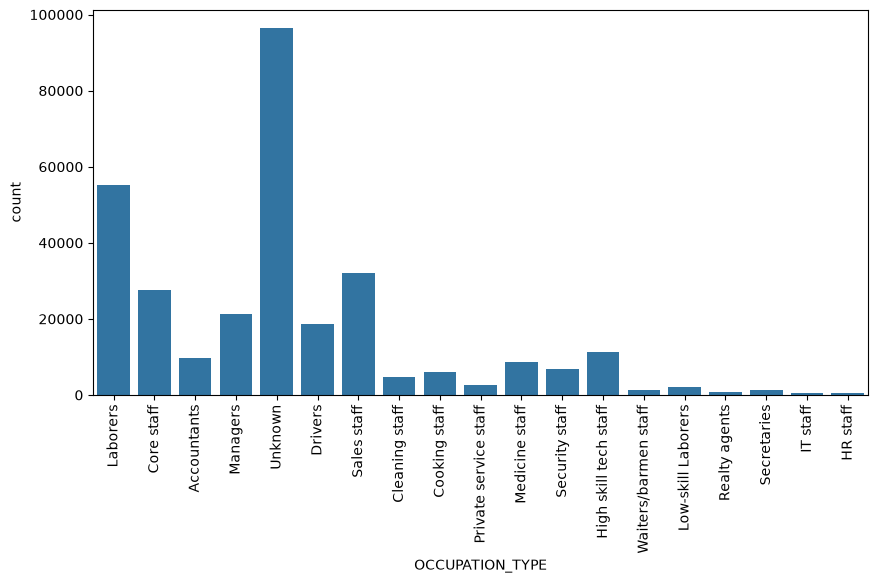

In [46]:
plt.figure(figsize = (10,5))
sns.countplot(data = df, x = "OCCUPATION_TYPE")
plt.xticks(rotation = 90)
plt.show()

**Спостереження**
- Якщо поглянути на графік, то найбільшу кількість заявників на кредит мають `Laborers`
- Для імпутації краще залишити дані як є (пропущені значення становлять 31,35%) і не проводити імпутацію за якоюсь константою, як-от мода або мін/макс медіана, якщо це числовий стовпчик, оскільки це може викривити дані в подальших розрахунках.

Існує також можливість імпутації за допомогою більш "розумних" методів, але ми вивчимо їх пізніше, а зараз ми робимо те, що можемо, за допомогою деяких найпростіших перетворень.

### Аналіз стовпця `EXT_SOURCE_3`

- пропущені значення = 19.83%

In [47]:
df.EXT_SOURCE_3.value_counts().head()

EXT_SOURCE_3
0.75    1460
0.71    1315
0.69    1276
0.67    1191
0.65    1154
Name: count, dtype: int64

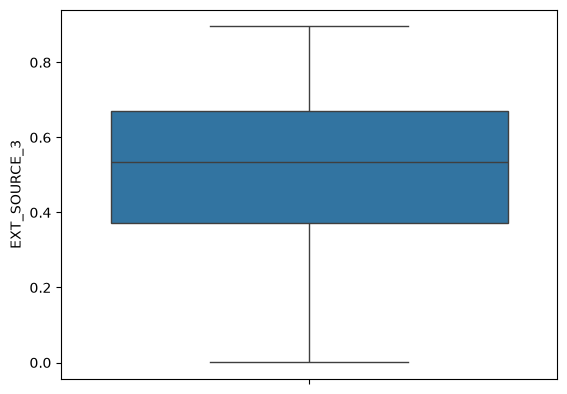

In [48]:
sns.boxplot(df.EXT_SOURCE_3)
plt.show()

Отримання процентильних значень для `EXT_SOURCE_3`

In [49]:
df.EXT_SOURCE_3.quantile(q = [0.25,0.5,0.75,1])

0.25   0.37
0.50   0.54
0.75   0.67
1.00   0.90
Name: EXT_SOURCE_3, dtype: float64

Найбільш повторюване значення в `EXT_SOURCE_3

In [50]:
df.EXT_SOURCE_3.mode()[0]

np.float64(0.746300213050371)

Перевірка середнього значення `EXT_SOURCE_3`

In [51]:
df.EXT_SOURCE_3.mean()

np.float64(0.5108529061799657)

**Спостереження**
-  Дивлячись на діагараму розмаху, медіана становить 0,535276
-  Найчастіше повторюване значення - 0,74630
-  Середнє значення - 0,51085
-  Хоча середнє та медіана є ближчими і можуть бути використані для імпутації, оскільки відсутнє відсоткове значення є більшим (19,83%), краще залишити дані як є і не проводити імпутації. Якщо метод вимагає імпутації, ми можемо імпутувати дані за допомогою медіани і створити ще один стовпчик, в якому буде позначено, які значення були імпутовані.

# ДЗ 1. Аналіз стовпців `AMT_REQ_CREDIT_BUREAU` з пропущеними значеннями

Виведіть середнє, моду, медіану та відсоток відсутніх даних для настуних колонок:

- `AMT_REQ_CREDIT_BUREAU_YEAR`
-	`AMT_REQ_CREDIT_BUREAU_MON`
-	`AMT_REQ_CREDIT_BUREAU_WEEK`

На основі виведених даних напишіть висновок про те, чи варто заповнювати пусті значення і якщо так, то яким чином?

In [52]:
cols = ['AMT_REQ_CREDIT_BUREAU_YEAR',
        'AMT_REQ_CREDIT_BUREAU_MON',
        'AMT_REQ_CREDIT_BUREAU_WEEK']

Середнє, мода, медіана та відсоток пропущених значень для кожної з колонок

In [53]:
stats = pd.DataFrame({
    'mean': df[cols].mean(),
    'mode': df[cols].mode().iloc[0],
    'median': df[cols].median(),
    'null_percentage': df[cols].isnull().mean() * 100
}).round(4)

display(stats)

,mean,mode,median,null_percentage
AMT_REQ_CREDIT_BUREAU_YEAR,1.90,0.00,1.00,13.50
AMT_REQ_CREDIT_BUREAU_MON,0.27,0.00,0.00,13.50
AMT_REQ_CREDIT_BUREAU_WEEK,0.03,0.00,0.00,13.50


Розподіл значень (разом з NaN) - наскільки чітко виділяється мода

In [54]:
for col in cols:
    print(df[col].value_counts(dropna=False).head(10))

AMT_REQ_CREDIT_BUREAU_YEAR
0.00    71801
1.00    63405
2.00    50192
NaN     41519
3.00    33628
4.00    20714
5.00    12052
6.00     6967
7.00     3869
8.00     2127
Name: count, dtype: int64
AMT_REQ_CREDIT_BUREAU_MON
0.00    222233
NaN      41519
1.00     33147
2.00      5386
3.00      1991
4.00      1076
5.00       602
6.00       343
7.00       298
9.00       206
Name: count, dtype: int64
AMT_REQ_CREDIT_BUREAU_WEEK
0.00    257456
NaN      41519
1.00      8208
2.00       199
3.00        58
4.00        34
6.00        20
5.00        10
8.00         5
7.00         2
Name: count, dtype: int64


Перевірка, чи пропуски знаходяться в одних і тих самих рядках

In [55]:
df[cols].isnull().all(axis=1).sum(), df[cols].isnull().any(axis=1).sum()

(np.int64(41519), np.int64(41519))

**Спостереження**
- В усіх трьох колонках однаковий відсоток пропущених значень - **13.5%** (41 519 рядків), і це **ті самі рядки**: пропуски в трьох досліджуваних колонках зустрічаються спільно. Можливо, це пов'язано зі спільним джерелом даних; причина пропусків потребує додаткової перевірки.
- `AMT_REQ_CREDIT_BUREAU_WEEK`: середнє 0.03, мода 0, медіана 0. Значення 0 мають ~96.8% клієнтів (серед заповнених значень) - мода виділяється дуже чітко.
- `AMT_REQ_CREDIT_BUREAU_MON`: середнє 0.27, мода 0, медіана 0. Значення 0 мають ~83.55% клієнтів (серед заповнених значень) - мода теж чітко виділяється.
- `AMT_REQ_CREDIT_BUREAU_YEAR`: середнє 1.90, мода 0, медіана 1. Розподіл розмазаний (серед заповнених значень: 0 - 27%, 1 - 24%, 2 - 19%, 3 - 13% ...), мода (0) виражена слабко на фоні 1 та 2, а середнє зміщене вправо через викиди.

**Висновок**
- Відсоток пропусків (13.5%) менший за 40%, тому колонки не видаляємо.
- За емпіричним правилом з лекції дані краще **залишити як є** до етапу моделювання, коли одночасно виконуються дві умови: пропусків більше 10% **і** немає чітко вираженої моди.
  - Для `AMT_REQ_CREDIT_BUREAU_YEAR` обидві умови виконуються (13.5% пропусків, мода виражена слабко), тому пропуски залишаємо.
  - Для `AMT_REQ_CREDIT_BUREAU_WEEK` та `AMT_REQ_CREDIT_BUREAU_MON` пропусків теж більше 10%, але мода (0) виражена чітко, тому друга умова не виконується. Залишити NaN до моделювання допустимо, а заповнення нулем - один з варіантів, який варто перевірити на етапі моделювання.
- Якщо метод машинного навчання вимагатиме заповнення:
  - `AMT_REQ_CREDIT_BUREAU_WEEK` та `AMT_REQ_CREDIT_BUREAU_MON` - можна розглянути заповнення **модою = медіаною = 0** зі збереженням флагу пропуску. Велика кількість нулів ще не гарантує, що заповнення мало вплине на дані: наприклад, для `AMT_REQ_CREDIT_BUREAU_MON` частка нулів зросте з 83.55% серед заповнених значень до 85.77% по всій колонці, а середнє знизиться з 0.2674 до 0.2313 (на 13.5% відносно середнього відомих значень). Тому вплив такого заповнення на розподіл і якість моделі потрібно перевірити;
  - `AMT_REQ_CREDIT_BUREAU_YEAR` - заповнювати **медіаною (1)**, а не середнім (1.90 - дробове значення для кількості запитів і чутливе до викидів) і не модою (0 - не виділяється чітко);
  - оскільки пропуски знаходяться в одних і тих самих рядках, варто створити **одну колонку-флаг** (0/1), яка позначає, що значення були пропущені - це буде додаткова ознака для моделі. Без такого флагу після заповнення пропусків нулем модель не зможе відрізнити "запитів не було" (справжній 0) від "даних немає" (був NaN), а флаг якраз зберігає цю різницю.

## Перевірка стовпців зі значеннями NULL > 0% та < 1%

Створення датафрейму `null_df_under1` з відсотком пропущених значень > 0% та < 1% у кожному стовпці

In [56]:
null_df_under1 = null_df[(null_df['null_percentage'] > 0) & (null_df['null_percentage'] < 1)]

In [57]:
null_df_under1.sort_values(by = 'null_percentage', ascending = False)

,column_name,null_count,null_percentage
11,NAME_TYPE_SUITE,1292,0.42
92,DEF_30_CNT_SOCIAL_CIRCLE,1021,0.33
91,OBS_30_CNT_SOCIAL_CIRCLE,1021,0.33
93,OBS_60_CNT_SOCIAL_CIRCLE,1021,0.33
94,DEF_60_CNT_SOCIAL_CIRCLE,1021,0.33
42,EXT_SOURCE_2,660,0.21
10,AMT_GOODS_PRICE,278,0.09


### Аналіз стовпця `NAME_TYPE_SUITE`

In [58]:
null_df_under1[null_df_under1.column_name == 'NAME_TYPE_SUITE']

,column_name,null_count,null_percentage
11,NAME_TYPE_SUITE,1292,0.42


In [59]:
df['NAME_TYPE_SUITE'].value_counts()

NAME_TYPE_SUITE
Unaccompanied      248526
Family              40149
Spouse, partner     11370
Children             3267
Other_B              1770
Other_A               866
Group of people       271
Name: count, dtype: int64

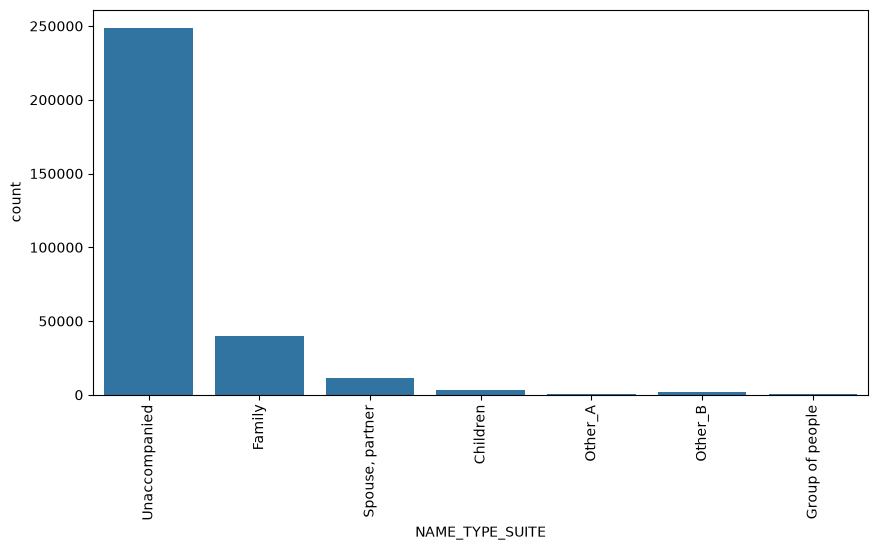

In [60]:
plt.figure(figsize = (10,5))
sns.countplot(data = df, x = "NAME_TYPE_SUITE")
plt.xticks(rotation = 90)
plt.show()

**Спостереження**
-   Дивлячись на графік, категорія `Unaccompanied` має найбільшу кількість заявників на отримання кредиту. Отже, більшість позичальників наважуються звертатися за кредитом без супроводу.
- Ми можемо продовжити імпутацію `Unaccompanied` в датафреймі, але краше надати перевагу другому варіанту.
- Ми також могли б імпутувати дані зі значенням `NA`, оскільки ця колонка є категоричною.
- Аналогічно, якщо в колонці не вистачає менше 1% даних, ми можемо її опустити. Але якщо ми вилучимо всі дані в усіх стовпчиках, де пропущено <=1% даних, ми можемо вилучити занадто багато даних. Тому я здебільшого зберігаю дані настільки, наскільки це можливо.

In [61]:
df['NAME_TYPE_SUITE'].fillna('NA', inplace=True)

C:\Users\USR\AppData\Local\Temp\ipykernel_17900\1528124425.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['NAME_TYPE_SUITE'].fillna('NA', inplace=True)


### Аналіз стовпця `OBS_30_CNT_SOCIAL_CIRCLE`

In [62]:
null_df_under1[null_df_under1.column_name == 'OBS_30_CNT_SOCIAL_CIRCLE']

,column_name,null_count,null_percentage
91,OBS_30_CNT_SOCIAL_CIRCLE,1021,0.33


In [63]:
df.OBS_30_CNT_SOCIAL_CIRCLE.value_counts().head(10)

OBS_30_CNT_SOCIAL_CIRCLE
0.00    163910
1.00     48783
2.00     29808
3.00     20322
4.00     14143
5.00      9553
6.00      6453
7.00      4390
8.00      2967
9.00      2003
Name: count, dtype: int64

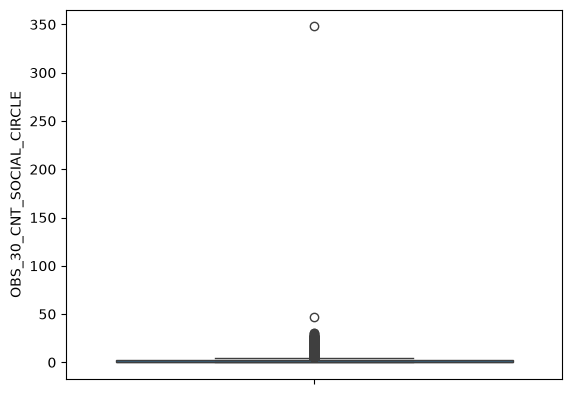

In [64]:
sns.boxplot(df.OBS_30_CNT_SOCIAL_CIRCLE)
plt.show()

Розрахунок перцентилів `OBS_30_CNT_SOCIAL_CIRCLE`

In [65]:
df.OBS_30_CNT_SOCIAL_CIRCLE.quantile(q = [0.25,0.5,0.75,1])

0.25     0.00
0.50     0.00
0.75     2.00
1.00   348.00
Name: OBS_30_CNT_SOCIAL_CIRCLE, dtype: float64

Найбільш повторюване значення в `OBS_30_CNT_SOCIAL_CIRCLE`

In [66]:
df.OBS_30_CNT_SOCIAL_CIRCLE.mode()[0]

np.float64(0.0)

Середнє значення `OBS_30_CNT_SOCIAL_CIRCLE`

In [67]:
df.OBS_30_CNT_SOCIAL_CIRCLE.mean()

np.float64(1.4222454239942575)

**Спостереження**
- Дивлячись на діаграму розмаху, медіана дорівнює 0.0
- Найчастіше повторюване значення - 0.0
- Середнє значення - 1,4222
- Є два викидні значення на рівні 50 та 350.
- Медіана і мода близькі (з огляду на діапазон даних у цьому стовпчику) і можуть бути використані для імпутації. Це не призведе до зміщення, оскільки відсоток пропущених значень невеликий (0,33%)

In [68]:
df['OBS_30_CNT_SOCIAL_CIRCLE'].fillna(df['OBS_30_CNT_SOCIAL_CIRCLE'].median(), inplace=True)

C:\Users\USR\AppData\Local\Temp\ipykernel_17900\1727889282.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['OBS_30_CNT_SOCIAL_CIRCLE'].fillna(df['OBS_30_CNT_SOCIAL_CIRCLE'].median(), inplace=True)


# ДЗ 2. Аналіз і заповнення пустих значень у колонках з малим відсотком пропущених

За прикладом вище проведіть аналіз пропущених значень в колонках
- EXT_SOURCE_2
- AMT_GOODS_PRICE

Для швидшого аналізу рекомендую написати фукнцію, яку Ви зможете викликати для кожної з колонок.

Зробіть висновок, що робити з пропущеними значеннями в кожному випадку і виконанайте ту дію, яку зазначили.

Функція для аналізу пропущених значень у числовій колонці (за прикладом аналізу `OBS_30_CNT_SOCIAL_CIRCLE` вище): кількість та відсоток пропусків, найчастіші значення, діаграма розмаху, перцентилі, мода, середнє та медіана.

In [69]:
def analyze_missing(col):
    # Кількість та відсоток пропущених значень (рахуємо по поточному df,
    # щоб при повторному виклику після заповнення бачити актуальні дані)
    missing_count = df[col].isna().sum()
    missing_percentage = (df[col].isna().mean() * 100).round(2)
    print('Пропущено:', missing_count, f'({missing_percentage}%)')

    # Найчастіші значення (з більшою кількістю знаків, ніж у глобальному float_format,
    # щоб близькі, але різні значення не виглядали однаковими)
    with pd.option_context('display.float_format', '{:.8g}'.format):
        display(df[col].value_counts().head(10))

    # Діаграма розмаху
    sns.boxplot(df[col])
    plt.show()

    # Перцентилі
    display(df[col].quantile(q = [0, 0.25, 0.5, 0.75, 1]))

    # Мода, середнє та медіана
    print('Мода:    ', df[col].mode()[0])
    print('Середнє: ', df[col].mean())
    print('Медіана: ', df[col].median())

### Аналіз стовпця `EXT_SOURCE_2`

Пропущено: 660 (0.21%)


EXT_SOURCE_2
0.28589787    721
0.26225837    417
0.26525634    343
0.15967923    322
0.26531175    306
0.26651978    244
0.26314359    243
0.16214457    238
0.16219211    234
0.16318704    184
Name: count, dtype: int64

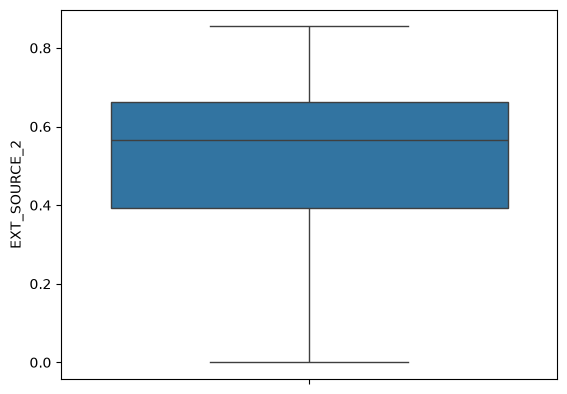

0.00   0.00
0.25   0.39
0.50   0.57
0.75   0.66
1.00   0.85
Name: EXT_SOURCE_2, dtype: float64

Мода:     0.2858978721410488
Середнє:  0.5143926741308464
Медіана:  0.5659614260608526


In [70]:
analyze_missing('EXT_SOURCE_2')

Перевірка, чи пов'язані пропуски з цільовою змінною: частка дефолтів у відсотках (`TARGET` = 1) та кількість рядків серед рядків з пропуском (`True`) і з заповненим значенням (`False`)

In [71]:
df.groupby(df['EXT_SOURCE_2'].isnull())['TARGET'].agg(
    default_rate_pct=lambda s: s.mean() * 100,
    count='count'
)

,default_rate_pct,count
EXT_SOURCE_2,,
False,8.07,306851
True,7.88,660


**Спостереження**
- Пропущені значення = **0.21%** (660 рядків) - це дуже мало.
- Найчастіше повторюване значення (мода) - 0.2859, але воно зустрічається лише в ~0.23% заповнених рядків, тобто чіткої моди немає: це неперервна змінна (оцінка із зовнішнього джерела в діапазоні 0 - 0.85).
- Середнє значення - 0.5144, медіана - 0.5660. Розподіл трохи скошений вліво (довгий хвіст малих значень), тому середнє менше за медіану. Викидів на діаграмі розмаху немає.
- Частка дефолтів серед рядків з пропуском - 7.88% (660 рядків), серед рядків із заповненим значенням - 8.07%. Явної різниці не видно, але для такої малої групи це не доводить, що сам факт пропуску не несе інформації про `TARGET`.

**Висновок**
- Оскільки пропусків дуже мало (0.21%), заповнення не призведе до помітного зміщення розподілу.
- Мода для імпутації не підходить (не виділяється і знаходиться далеко від центру розподілу). Заповнюємо **медіаною (0.5660)** - вона краще за середнє описує центр скошеного розподілу.
- Колонку-флаг у межах цього EDA не створюємо, бо пропусків дуже мало (0.21%). Відсутність зв'язку пропусків з `TARGET` не доведена, тому на етапі моделювання флаг можна перевірити як додаткову ознаку.

In [72]:
df['EXT_SOURCE_2'] = df['EXT_SOURCE_2'].fillna(df['EXT_SOURCE_2'].median())

In [73]:
df['EXT_SOURCE_2'].isnull().sum()

np.int64(0)

### Аналіз стовпця `AMT_GOODS_PRICE`

Пропущено: 278 (0.09%)


AMT_GOODS_PRICE
450000     26022
225000     25282
675000     24962
900000     15416
270000     11428
180000     10123
454500      9157
1125000     9050
135000      8206
315000      5225
Name: count, dtype: int64

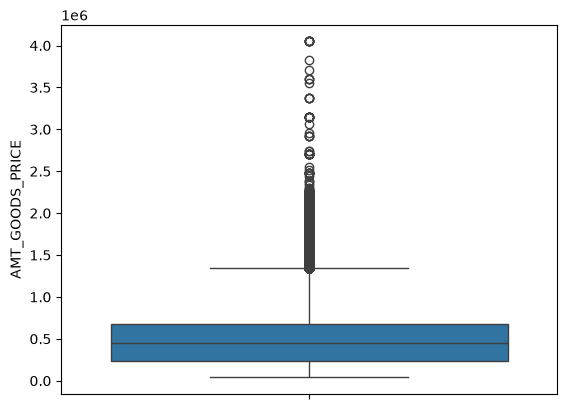

0.00     40500.00
0.25    238500.00
0.50    450000.00
0.75    679500.00
1.00   4050000.00
Name: AMT_GOODS_PRICE, dtype: float64

Мода:     450000.0
Середнє:  538396.2074288895
Медіана:  450000.0


In [74]:
analyze_missing('AMT_GOODS_PRICE')

Перевірка, до яких типів кредитів належать рядки з пропущеною ціною товару

In [75]:
df.loc[df['AMT_GOODS_PRICE'].isnull(), 'NAME_CONTRACT_TYPE'].value_counts()

NAME_CONTRACT_TYPE
Revolving loans    278
Name: count, dtype: int64

Всі пропуски належать до `Revolving loans` (відновлювальних кредитів, кредитних ліній). Перевіримо, як часто для таких кредитів ціна товару дорівнює сумі кредиту `AMT_CREDIT` (серед заповнених значень)

In [76]:
revolving = df[(df['NAME_CONTRACT_TYPE'] == 'Revolving loans') & df['AMT_GOODS_PRICE'].notnull()]
(revolving['AMT_GOODS_PRICE'] == revolving['AMT_CREDIT']).mean()

np.float64(0.9886900451708561)

In [77]:
df.loc[df['AMT_GOODS_PRICE'].isnull(), 'AMT_CREDIT'].describe()

count       278.00
mean     279631.29
std      189892.08
min      135000.00
25%      180000.00
50%      225000.00
75%      270000.00
max     1350000.00
Name: AMT_CREDIT, dtype: float64

Перевірка, чи пов'язані пропуски з цільовою змінною. Оскільки всі пропуски належать до `Revolving loans`, порівнюємо частку дефолтів у відсотках (`TARGET` = 1) всередині цього типу кредиту: серед рядків з пропуском (`True`) і з заповненим значенням (`False`)

In [78]:
revolving_all = df[df['NAME_CONTRACT_TYPE'] == 'Revolving loans']
revolving_all.groupby(revolving_all['AMT_GOODS_PRICE'].isnull())['TARGET'].agg(
    default_rate_pct=lambda s: s.mean() * 100,
    count='count'
)

,default_rate_pct,count
AMT_GOODS_PRICE,,
False,5.46,29001
True,7.55,278


**Спостереження**
- Пропущені значення = **0.09%** (278 рядків) - це дуже мало.
- Мода - 450 000, медіана - 450 000, середнє - 538 396. Розподіл скошений вправо: на діаграмі розмаху багато викидів (до 4 050 000), тому середнє більше за медіану.
- Значення "круглі" (450 000, 225 000, 675 000 ...), і мода чітко не виділяється: три найчастіші значення мають приблизно однакову частку (~8%).
- **Всі 278 пропусків належать до `Revolving loans`**. Для таких кредитів ціна товару дорівнює сумі кредиту `AMT_CREDIT` у **98.87%** випадків.
- Сума кредиту в рядках з пропуском значно менша за загальну медіану ціни товару (медіана `AMT_CREDIT` у цих рядках - 225 000), тож заповнення загальною медіаною (450 000) для них завищило б ціну товару приблизно вдвічі.
- Всередині `Revolving loans` частка дефолтів серед рядків з пропуском - 7.55% (278 рядків), серед рядків із заповненим значенням - 5.46%. Група з пропусками мала, тому ця різниця ще не доводить зв'язку пропусків з `TARGET`, але й не дозволяє стверджувати, що зв'язку немає.

**Висновок**
- Оскільки пропусків дуже мало (0.09%), заповнюємо їх, а не видаляємо рядки чи колонку.
- Середнє не підходить через викиди. Медіана (= мода = 450 000) - стандартний варіант з лекції, але для цих рядків він не відповідає реальним даним.
- Тому заповнюємо пропуски **значенням `AMT_CREDIT` з того самого рядка**: для `Revolving loans` це майже завжди (98.87%) і є ціною товару.
- У всіх 278 рядках з пропуском `AMT_CREDIT` заповнений (`count` = 278 у `describe` вище), тож таке заповнення закриє всі пропуски.
- Колонку-флаг у межах цього EDA не створюємо, бо пропусків дуже мало (0.09%). Зв'язок пропусків з `TARGET` не доведений, але й не виключений, тому на етапі моделювання флаг можна перевірити як додаткову ознаку.

In [79]:
df['AMT_GOODS_PRICE'] = df['AMT_GOODS_PRICE'].fillna(df['AMT_CREDIT'])

Перевірка, чи заповнені всі пропуски в обох колонках

In [80]:
df[['EXT_SOURCE_2', 'AMT_GOODS_PRICE']].isnull().sum()

EXT_SOURCE_2       0
AMT_GOODS_PRICE    0
dtype: int64

# Робота з неправильними/невідомими значеннями даних

### Аналіз стовпця `CODE_GENDER`

Перевірка діапазону значень

In [81]:
df['CODE_GENDER'].value_counts()

CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64

Стать має бути тільки чоловіча або жіноча. Значення `XNA` може вказувати на те, що значення не було надано заявником або пропущено кредитним спеціалістом, який перевіряє заявку

In [82]:
df[df['CODE_GENDER'] == 'XNA']

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_2,EXT_SOURCE_3,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
35657,141289,0,Revolving loans,XNA,1,1,0,207000.00,382500.00,19125.00,337500.00,Unaccompanied,Working,Secondary / secondary special,Married,Municipal apartment,0.02,-20232,-10044,-10024.00,-3537,1,1,1,1,1,0,Unknown,2.00,3,3,TUESDAY,10,0,0,0,0,0,0,Business Entity Type 1,0.30,0.46,0.00,0.00,0.00,0.00,-286.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,1.00
38566,144669,0,Revolving loans,XNA,0,1,2,157500.00,270000.00,13500.00,225000.00,Family,Working,Secondary / secondary special,Married,House / apartment,0.03,-13717,-2797,-2241.00,-4659,1,1,1,1,1,0,Low-skill Laborers,4.00,2,2,FRIDAY,16,0,0,0,0,0,0,Industry: type 3,0.71,0.31,0.00,0.00,0.00,0.00,-493.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,3.00,0.00,4.00
83382,196708,0,Revolving loans,XNA,0,1,1,135000.00,405000.00,20250.00,225000.00,Unaccompanied,Working,Higher education,Married,House / apartment,0.04,-10647,-1228,-183.00,-1671,1,1,1,1,1,0,Core staff,3.00,2,2,THURSDAY,15,0,0,0,0,0,0,Kindergarten,0.66,0.08,7.00,1.00,7.00,1.00,-851.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,3.00
189640,319880,0,Revolving loans,XNA,1,1,0,247500.00,540000.00,27000.00,900000.00,Unaccompanied,Commercial associate,Incomplete higher,Civil marriage,House / apartment,0.04,-9649,-2293,-4099.00,-2326,1,1,1,1,1,0,Unknown,2.00,2,2,FRIDAY,15,0,0,0,0,0,0,Medicine,0.66,0.36,10.00,4.00,10.00,4.00,-1681.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,1.00,6.00


Оскільки дані виглядають достовірними, ми перевіримо можливість застосування методу імпутації.
- Заявників-жінок удвічі більше, ніж заявників-чоловіків
- Отже, ми прирівняємо `CODE_GENDER` до 'F'

In [83]:
df['CODE_GENDER'] = df['CODE_GENDER'].apply(lambda x: 'F' if x == 'XNA' else x)

Перевірка, чи вилучено `XNA`

In [84]:
df['CODE_GENDER'].value_counts()

CODE_GENDER
F    202452
M    105059
Name: count, dtype: int64

### Аналіз стовпця `DAYS_BIRTH`

In [85]:
df['DAYS_BIRTH'].value_counts().head()

DAYS_BIRTH
-13749    43
-13481    42
-10020    41
-18248    41
-15771    40
Name: count, dtype: int64

Існує ~17K+ унікальних записів, всі з яких, схоже, мають від'ємні значення

In [86]:
df['DAYS_BIRTH'].unique()

array([ -9461, -16765, -19046, ...,  -7951,  -7857, -25061],
      shape=(17460,))

In [87]:
df['DAYS_BIRTH'].nunique()

17460

In [88]:
df['DAYS_BIRTH'].describe()

count   307511.00
mean    -16037.00
std       4363.99
min     -25229.00
25%     -19682.00
50%     -15750.00
75%     -12413.00
max      -7489.00
Name: DAYS_BIRTH, dtype: float64

Перетворення `Days Birth` на додатні дні

In [89]:
df['DAYS_BIRTH'] = df['DAYS_BIRTH'].apply(lambda x: -x if x < 0 else x)

In [90]:
df['DAYS_BIRTH'].value_counts()

DAYS_BIRTH
13749    43
13481    42
10020    41
18248    41
15771    40
         ..
24958     1
25048     1
24980     1
25061     1
25045     1
Name: count, Length: 17460, dtype: int64

Всі дні в `DAYS_BIRTH` мають додатні значення - це може бути зручніше для аналізу.

#### Створимо нову колонку `YEARS_BIRTH` для зручності аналізу

In [91]:
df['YEARS_BIRTH'] = df['DAYS_BIRTH'].apply(lambda x: round(x/365))

### Аналіз стовпця `NAME_FAMILY_STATUS`

Перевірка діапазону значень

In [92]:
df['NAME_FAMILY_STATUS'].value_counts()

NAME_FAMILY_STATUS
Married                 196432
Single / not married     45444
Civil marriage           29775
Separated                19770
Widow                    16088
Unknown                      2
Name: count, dtype: int64

Стать має бути тільки чоловіча або жіноча. Значення `Unknown` може означати, що значення не було вказане заявником або пропущене кредитним спеціалістом, який перевіряє заявку

In [93]:
df[df['NAME_FAMILY_STATUS'] == 'Unknown']

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_2,EXT_SOURCE_3,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,YEARS_BIRTH
41982,148605,0,Revolving loans,M,0,1,0,450000.00,675000.00,33750.00,675000.00,NA,Commercial associate,Lower secondary,Unknown,Municipal apartment,0.02,12396,-1161,-3265.00,-4489,1,1,1,1,1,0,Managers,NaN,2,2,THURSDAY,15,0,1,1,0,1,1,Insurance,0.70,NaN,3.00,0.00,3.00,0.00,-876.00,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,34
187348,317181,0,Revolving loans,F,0,1,0,202500.00,585000.00,29250.00,585000.00,NA,Commercial associate,Higher education,Unknown,House / apartment,0.03,12844,-232,-1597.00,-1571,1,1,0,1,0,0,Accountants,NaN,2,2,FRIDAY,14,0,0,0,0,0,0,Business Entity Type 2,0.65,0.67,1.00,0.00,1.00,0.00,-654.00,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,1.00,35


In [94]:
df['NAME_FAMILY_STATUS'].value_counts(normalize = True) * 100

NAME_FAMILY_STATUS
Married                63.88
Single / not married   14.78
Civil marriage          9.68
Separated               6.43
Widow                   5.23
Unknown                 0.00
Name: proportion, dtype: float64

Оскільки дані виглядають достовірними, ми продовжимо перевірку методу імпутації.
- Одружені заявники складають понад 63% заявників.
- Отже, ми прирівняємо `NAME_FAMILY_STATUS` до `Married`.

In [95]:
df['NAME_FAMILY_STATUS'] = df['NAME_FAMILY_STATUS'].apply(lambda x: 'Married' if x == 'Unknown' else x)

Перевірка чи вилучено `Unknown`

In [96]:
df['NAME_FAMILY_STATUS'].value_counts()

NAME_FAMILY_STATUS
Married                 196434
Single / not married     45444
Civil marriage           29775
Separated                19770
Widow                    16088
Name: count, dtype: int64

### Аналіз стовпця`DAYS_EMPLOYED`

In [97]:
df['DAYS_EMPLOYED'].value_counts().head()

DAYS_EMPLOYED
 365243    55374
-200         156
-224         152
-230         151
-199         151
Name: count, dtype: int64

In [98]:
df['DAYS_EMPLOYED'].value_counts(normalize = True) * 100

DAYS_EMPLOYED
 365243   18.01
-200       0.05
-224       0.05
-230       0.05
-199       0.05
           ... 
-11471     0.00
-12878     0.00
-10573     0.00
-12990     0.00
-14184     0.00
Name: proportion, Length: 12574, dtype: float64

In [99]:
len(df[df['DAYS_EMPLOYED'] < 365243])

252137

In [100]:
df[df['DAYS_EMPLOYED'] < 365243].DAYS_EMPLOYED.value_counts()

DAYS_EMPLOYED
-200      156
-224      152
-230      151
-199      151
-212      150
         ... 
-12037      1
-16554      1
-11276      1
-8348       1
-9129       1
Name: count, Length: 12573, dtype: int64

In [101]:
df['DAYS_EMPLOYED'].unique()

array([  -637,  -1188,   -225, ..., -12971, -11084,  -8694],
      shape=(12574,))

In [102]:
df['DAYS_EMPLOYED'].nunique()

12574

**Спостереження**
- Існує ~55K+ записів, для яких `DAYS_EMPLOYED` дорівнює 365243 дням
- Решта 252K+ записів мають від'ємне значення днів
- Існує 12 574 унікальних значень для `DAYS_EMPLOYED`

 - Колонка `DAYS_EMPLOYED` вказує на те, за скільки днів до подачі заявки особа почала поточну роботу, заявник/кредитний спеціаліст повинен ввести від'ємні значення, щоб вказати дні, що передують даті подачі заявки.<br>
 - Ми конвертуємо від'ємні значення в `DAYS_EMPLOYED` в додатні дні, щоб стандартизувати дні під час використання в розрахунках

In [103]:
df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].apply(lambda x: -x if x < 0 else x)

In [104]:
df['DAYS_EMPLOYED'].value_counts().head()

DAYS_EMPLOYED
365243    55374
200         156
224         152
230         151
199         151
Name: count, dtype: int64

Ми бачимо, що всі дні в `DAYS_EMPLOYED` мають додатні значення

**Для ~55K+ записів, для яких `DAYS_EMPLOYED` становить 365243 дні**
- Конвертуючи це в роки, ми отримуємо 1000 років, які фізично неможливо використати для працевлаштування заявника
- Це відповідає 18% даних і не може бути аномалією
- Вони можуть бути або пенсіонерами, або безробітними, і, дивлячись на дані, наш висновок є правильним

> Є два способи впоратися з цим
>> 1) Ми залишаємо дані такими, якими вони є, і враховуємо це під час аналізу АБО  <br>
>> 2) Ми розраховуємо середню кількість днів зайнятості без урахування цієї категорії та вписуємо її замість 365243 днів для пенсіонерів. <br>
>> Для безробітних кількість днів зайнятості може дорівнювати 0

*Примітка*
 - Під час розрахунків у цьому стовпчику ми повинні враховувати цей сценарій, оскільки інакше він спотворює наші результати

In [105]:
df[df['DAYS_EMPLOYED'] == 365243].NAME_INCOME_TYPE.value_counts()

NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64

#### Створимо нову колонку `YEARS_EMPLOYED` для зручності аналізу

In [106]:
df['YEARS_EMPLOYED'] = df['DAYS_EMPLOYED'].apply(lambda x: round(x/365))

### Аналіз стовпця `DAYS_REGISTRATION`

In [107]:
df['DAYS_REGISTRATION'].value_counts().head()

DAYS_REGISTRATION
-1.00    113
-7.00     98
-6.00     96
-4.00     92
-2.00     92
Name: count, dtype: int64

In [108]:
df['DAYS_REGISTRATION'].value_counts(normalize = True).head()

DAYS_REGISTRATION
-1.00   0.00
-7.00   0.00
-6.00   0.00
-4.00   0.00
-2.00   0.00
Name: proportion, dtype: float64

In [109]:
df['DAYS_REGISTRATION'].unique()

array([ -3648.,  -1186.,  -4260., ..., -16396., -14558., -14798.],
      shape=(15688,))

In [110]:
df['DAYS_REGISTRATION'].nunique()

15688

Перетворення `DAYS_REGISTRATION` в додатні дні

In [111]:
df['DAYS_REGISTRATION'] = df['DAYS_REGISTRATION'].apply(lambda x: -x if x < 0 else x)

In [112]:
df['DAYS_REGISTRATION'].value_counts().head()

DAYS_REGISTRATION
1.00    113
7.00     98
6.00     96
4.00     92
2.00     92
Name: count, dtype: int64

Всі дні в `DAYS_REGISTRATION` мають додатні значення

#### Створимо нову колонку `YEARS_REGISTRATION` для зручності аналізу

In [113]:
df['YEARS_REGISTRATION'] = df['DAYS_REGISTRATION'].apply(lambda x: round(x/365))

### Аналіз стовпця `DAYS_ID_PUBLISH`

In [114]:
df['DAYS_ID_PUBLISH'].value_counts().head()

DAYS_ID_PUBLISH
-4053    169
-4095    162
-4046    161
-4417    159
-4256    158
Name: count, dtype: int64

In [115]:
df['DAYS_ID_PUBLISH'].value_counts(normalize = True).head()

DAYS_ID_PUBLISH
-4053   0.00
-4095   0.00
-4046   0.00
-4417   0.00
-4256   0.00
Name: proportion, dtype: float64

In [116]:
df['DAYS_ID_PUBLISH'].unique()

array([-2120,  -291, -2531, ..., -6194, -5854, -6211], shape=(6168,))

In [117]:
df['DAYS_ID_PUBLISH'].nunique()

6168

Перетворення `DAYS_ID_PUBLISH` в додатні дні

In [118]:
df['DAYS_ID_PUBLISH'] = df['DAYS_ID_PUBLISH'].apply(lambda x: -x if x < 0 else x)

In [119]:
df['DAYS_ID_PUBLISH'].value_counts().head()

DAYS_ID_PUBLISH
4053    169
4095    162
4046    161
4417    159
4256    158
Name: count, dtype: int64

Всі дні в `DAYS_ID_PUBLISH` мають додатні значення

#### Створимо нову колонку `YEARS_ID_PUBLISH` для зручності аналізу

In [120]:
df['YEARS_ID_PUBLISH'] = df['DAYS_ID_PUBLISH'].apply(lambda x: round(x/365))

### Аналіз стовпця `DAYS_LAST_PHONE_CHANGE`

In [121]:
df['DAYS_LAST_PHONE_CHANGE'].value_counts().head()

DAYS_LAST_PHONE_CHANGE
0.00     37672
-1.00     2812
-2.00     2318
-3.00     1763
-4.00     1285
Name: count, dtype: int64

In [122]:
df['DAYS_LAST_PHONE_CHANGE'].value_counts(normalize = True).head()

DAYS_LAST_PHONE_CHANGE
0.00    0.12
-1.00   0.01
-2.00   0.01
-3.00   0.01
-4.00   0.00
Name: proportion, dtype: float64

In [123]:
df['DAYS_LAST_PHONE_CHANGE'].unique()

array([-1134.,  -828.,  -815., ..., -3988., -3899., -3538.], shape=(3774,))

In [124]:
df['DAYS_LAST_PHONE_CHANGE'].nunique()

3773

Перетворення `DAYS_LAST_PHONE_CHANGE` в додатні дні

In [125]:
df['DAYS_LAST_PHONE_CHANGE'] = df['DAYS_LAST_PHONE_CHANGE'].apply(lambda x: -x if x < 0 else x)

In [126]:
df['DAYS_LAST_PHONE_CHANGE'].value_counts().head()

DAYS_LAST_PHONE_CHANGE
0.00    37672
1.00     2812
2.00     2318
3.00     1763
4.00     1285
Name: count, dtype: int64

Всі дні в `DAYS_LAST_PHONE_CHANGE` мають додатні значення

#### Створення нової колонки `YEARS_LAST_PHONE_CHANGE` для зручності аналізу

In [127]:
df['YEARS_LAST_PHONE_CHANGE'] = df['DAYS_LAST_PHONE_CHANGE'].apply(lambda x: round(x/365,0))

# Автоматичні функції

### Створення функції `age_cat` для категоризації `YEARS_BORNING`

In [128]:
def age_cat(years):
    if years <= 20:
        return '0-20'
    elif years > 20 and years <= 30:
        return '20-30'
    elif years > 30 and years <= 40:
        return '30-40'
    elif years > 40 and years <= 50:
        return '40-50'
    elif years > 50 and years <= 60:
        return '50-60'
    elif years > 60 and years <= 70:
        return '60-70'
    elif years > 70:
        return '70+'

### Одномірний (категоріальний vs цільовий) та двомірний (категоріальний vs категоріальний) аналіз (гістограма) - категоріальні стовпчики

In [129]:
import matplotlib.pyplot as plt


def bi_cat_countplot(df, column, hue_column):
    unique_hue_values = df[hue_column].unique()
    fig, axes = plt.subplots(nrows=1, ncols=2)
    fig.set_size_inches(14,6)

    pltname = f'Нормалізований розподіл значень за категорією: {column}'
    proportions = df.groupby(hue_column)[column].value_counts(normalize=True)
    proportions = (proportions*100).round(2)
    ax = proportions.unstack(hue_column).sort_values(
        by=unique_hue_values[0], ascending=False
        ).plot.bar(ax=axes[0], title=pltname)

    # анотація значень в барплоті
    for container in ax.containers:
        ax.bar_label(container, fmt='{:,.1f}%')

    pltname = f'Кількість даних за категорією: {column}'
    counts = df.groupby(hue_column)[column].value_counts()
    ax = counts.unstack(hue_column).sort_values(
        by=unique_hue_values[0], ascending=False
        ).plot.bar(ax=axes[1], title=pltname)

    for container in ax.containers:
      ax.bar_label(container)


def uni_cat_target_compare(df, column):
    bi_cat_countplot(df, column, hue_column='TARGET' )


def bi_countplot_target(df0, df1, column, hue_column):
  pltname = 'Клієнт зі складнощами щодо платності'
  print(pltname.upper())
  bi_cat_countplot(df1, column, hue_column)
  plt.show()

  pltname = 'Клієнти зі своєчасними платежами'
  print(pltname.upper())
  bi_cat_countplot(df0, column, hue_column)
  plt.show()


### Обчислення мінімального та максимального діапазону відхилень для числових стовпців

In [130]:
def outlier_range(dataset,column):
    Q1 = dataset[column].quantile(0.25)
    Q3 = dataset[column].quantile(0.75)
    IQR = Q3 - Q1
    Min_value = (Q1 - 1.5 * IQR)
    Max_value = (Q3 + 1.5 * IQR)
    return Max_value

# Робота з викидами для числових стовпців

In [131]:
import warnings

def dist_box(dataset, column):
    with warnings.catch_warnings():
      warnings.simplefilter("ignore")

      plt.figure(figsize=(16,6))

      plt.subplot(1,2,1)
      sns.distplot(dataset[column], color = 'purple')
      pltname = 'Графік розподілу для ' + column
      plt.ticklabel_format(style='plain', axis='x')
      plt.title(pltname)

      plt.subplot(1,2,2)
      red_diamond = dict(markerfacecolor='r', marker='D')
      sns.boxplot(y = column, data = dataset, flierprops = red_diamond)
      pltname = 'Боксплот для ' + column
      plt.title(pltname)

      plt.show()

### Аналіз стовпця`CNT_CHILDREN`

In [132]:
df['CNT_CHILDREN'].value_counts().sort_values(ascending = False).head()

CNT_CHILDREN
0    215371
1     61119
2     26749
3      3717
4       429
Name: count, dtype: int64

In [133]:
(df['CNT_CHILDREN'].value_counts(normalize = True).sort_values(ascending = False) * 100).head()

CNT_CHILDREN
0   70.04
1   19.88
2    8.70
3    1.21
4    0.14
Name: proportion, dtype: float64

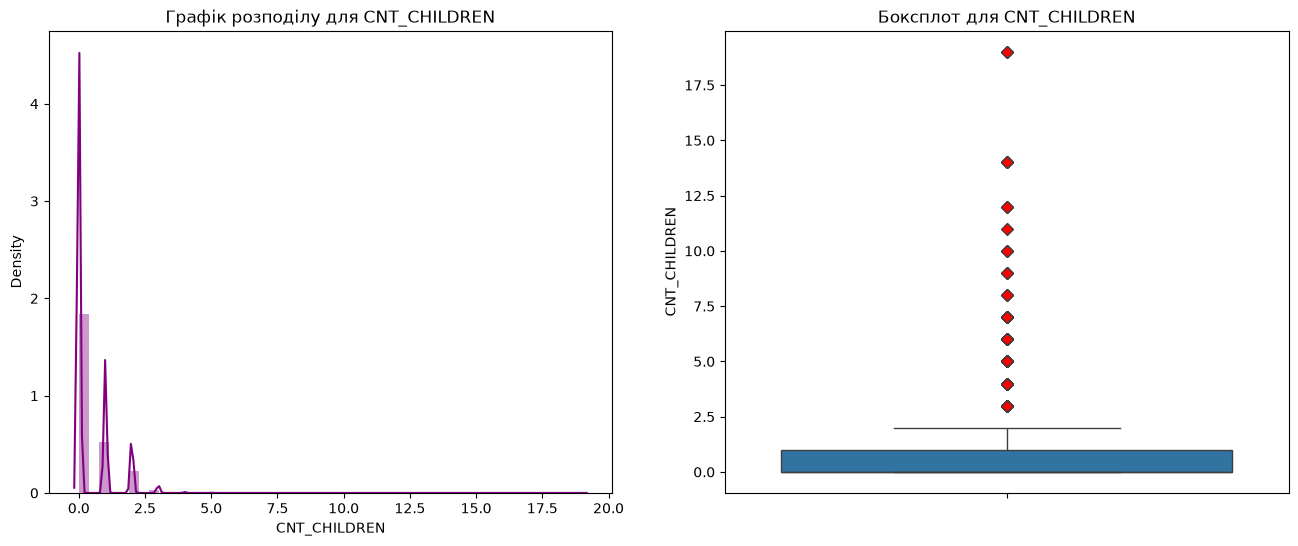

In [134]:
dist_box(df,'CNT_CHILDREN')

Розрахуємо IQR (Inter Quartile range)

In [135]:
Q1 = df['CNT_CHILDREN'].quantile(0.25)
Q3 = df['CNT_CHILDREN'].quantile(0.75)
IQR = Q3 - Q1
print(IQR)

1.0


Значення *до* (Q1 - 1,5 * IQR) та *після* (Q3 + 1,5 * IQR) є викидами

In [136]:
Min_value = (Q1 - 1.5 * IQR)
Max_value = (Q3 + 1.5 * IQR)
print("Мінімальне значення, до якого існують викиди: {}".format(Min_value))
print("Максимальне значення, після якого існують викиди: {}".format(Max_value))

Мінімальне значення, до якого існують викиди: -1.5
Максимальне значення, після якого існують викиди: 2.5


**Спостереження**
- Дивлячись на дані, ми бачимо, що кількість заявників, які мають більше 7 дітей, є дуже мінімальною (2 або 3 в кожній категорії)
- Крім того, дивлячись на дані для заявників з 10 дітьми, заявники мають лише 31 й 41 рік відповідно. Це виглядає як одиничний випадок й може розглядатися як відхилення від норми
- Як дистрибутивні, так і діаграми розмаху чітко показують, що значення, які перевищують значення 2.5, є відхиленнями від норми.

**Висновок**
- Заявники, які мають 3 або більше дітей, є випадками, що відхиляються від норми. Ми можемо надати спеціальний аналіз для цих випадків.

### Аналіз стовпця `AMT_INCOME_TOTAL`

In [137]:
df['AMT_INCOME_TOTAL'].value_counts().sort_values(ascending = False).head()

AMT_INCOME_TOTAL
135000.00    35750
112500.00    31019
157500.00    26556
180000.00    24719
90000.00     22483
Name: count, dtype: int64

In [138]:
(df['AMT_INCOME_TOTAL'].value_counts(normalize = True).sort_values(ascending = False) * 100).head()

AMT_INCOME_TOTAL
135000.00   11.63
112500.00   10.09
157500.00    8.64
180000.00    8.04
90000.00     7.31
Name: proportion, dtype: float64

In [139]:
df['AMT_INCOME_TOTAL'].describe(percentiles = [0.75,0.99,0.999])

count      307511.00
mean       168797.92
std        237123.15
min         25650.00
50%        147150.00
75%        202500.00
99%        472500.00
99.9%      900000.00
max     117000000.00
Name: AMT_INCOME_TOTAL, dtype: float64

Побудуємо графік для `AMT_INCOME_TOTAL`

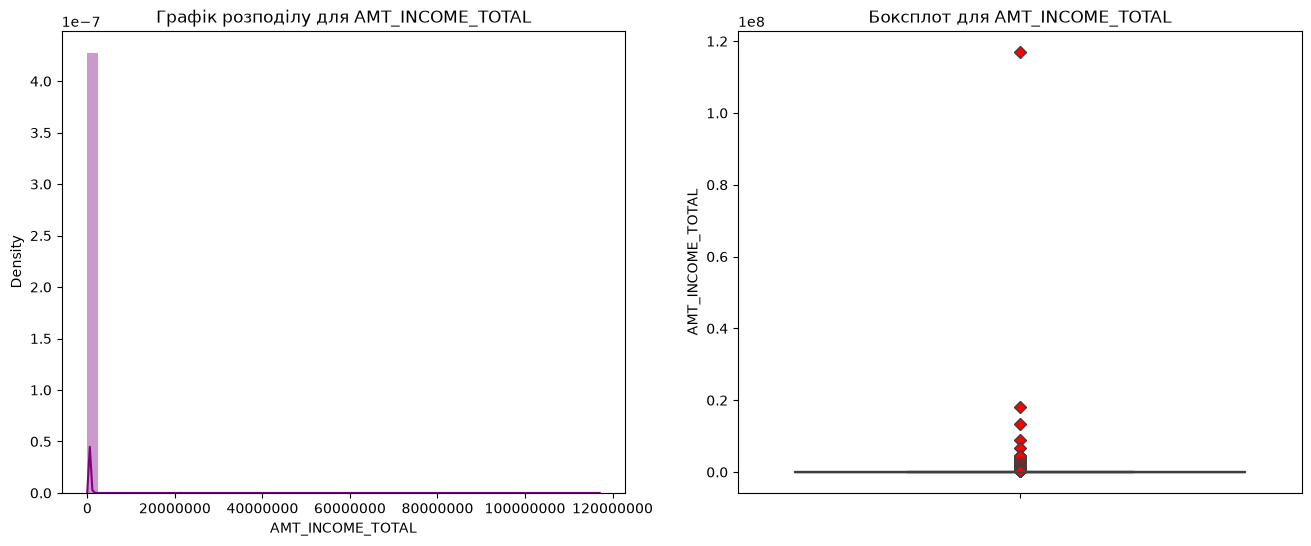

In [140]:
dist_box(df,'AMT_INCOME_TOTAL')

- Графіки кінцевого результату дуже тонкі, й ми можемо спостерігати викид близько ~120 мільйонів.
- Давайте побудуємо графік, розглядаючи лише дохід нижче 99,9% значення, тобто 900 тисяч.

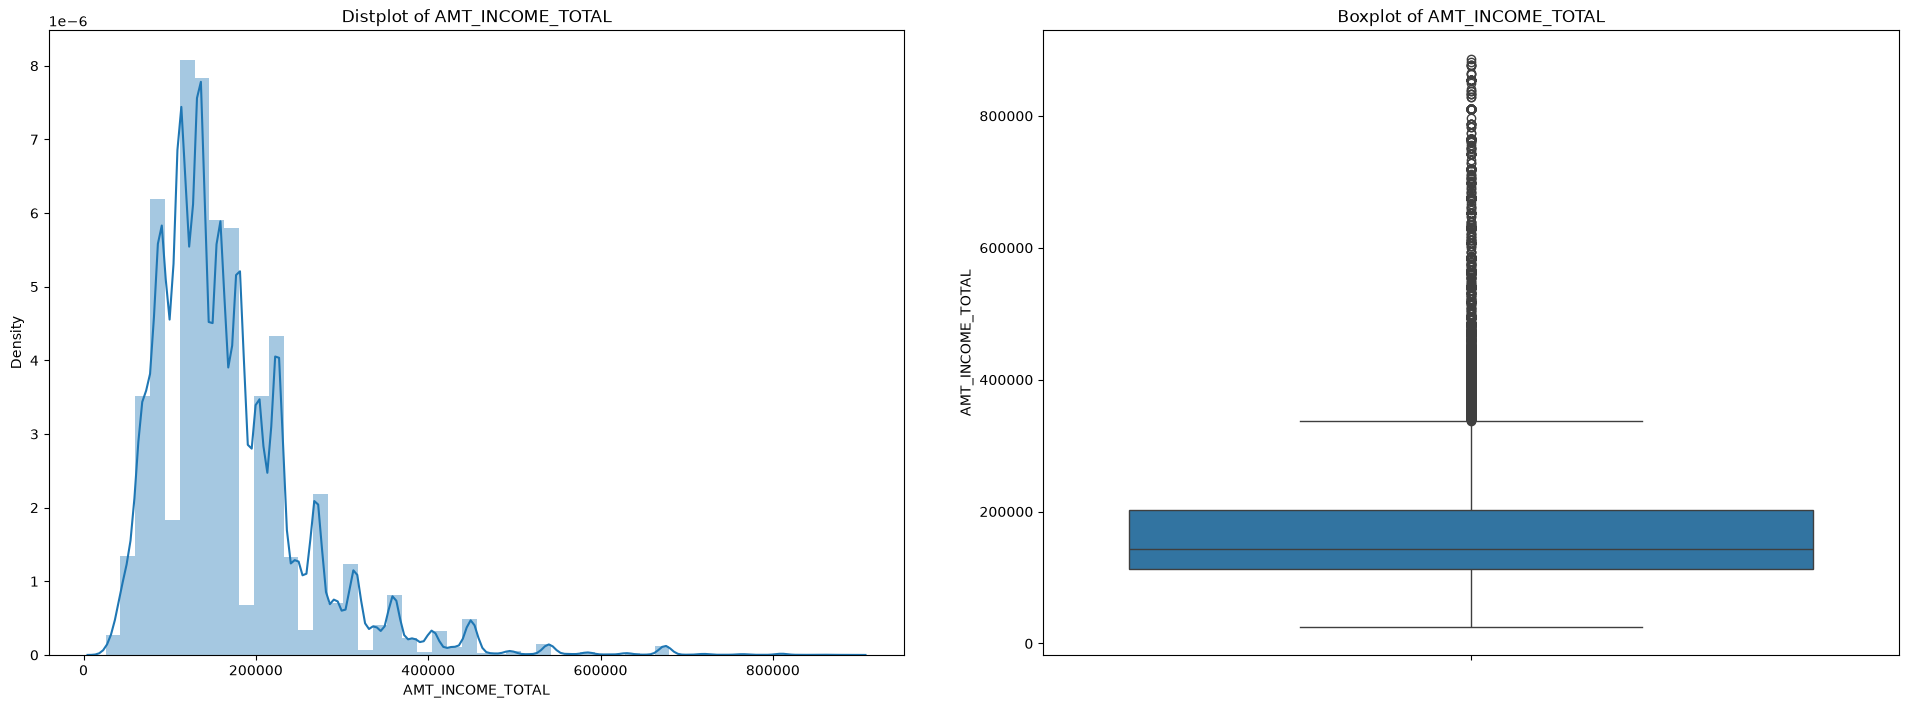

In [141]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    plt.subplots(1,2 ,figsize = (20,8))

    plt.subplot(121)
    sns.distplot(df[df['AMT_INCOME_TOTAL'] < 900000].AMT_INCOME_TOTAL)
    pltname = 'Distplot of ' + 'AMT_INCOME_TOTAL'
    plt.title(pltname)

    plt.subplot(122)
    sns.boxplot(df[df['AMT_INCOME_TOTAL'] < 900000].AMT_INCOME_TOTAL)
    pltname = 'Boxplot of ' + 'AMT_INCOME_TOTAL'
    plt.title(pltname)

    plt.tight_layout(pad = 4)
    plt.show()

Тепер ми можемо чітко побачити розподіл і діапазон даних на обох графіках.
 - Це означає, що значення понад 900 тис. грн доходу явно є викидами

In [142]:
df[df['AMT_INCOME_TOTAL'] > 900000].head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_2,EXT_SOURCE_3,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,YEARS_BIRTH,YEARS_EMPLOYED,YEARS_REGISTRATION,YEARS_ID_PUBLISH,YEARS_LAST_PHONE_CHANGE
1504,101769,0,Revolving loans,M,1,1,0,1080000.00,180000.00,9000.00,180000.00,Unaccompanied,Commercial associate,Higher education,Married,House / apartment,0.07,13633,5536,3.00,4971,1,1,0,1,0,0,Unknown,2.00,1,1,FRIDAY,13,0,1,1,0,0,0,Business Entity Type 3,0.65,0.46,0.00,0.00,0.00,0.00,491.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00,37,15,0,14,1.00
1723,102015,0,Cash loans,F,0,1,0,1935000.00,269550.00,10534.50,225000.00,Unaccompanied,Pensioner,Secondary / secondary special,Married,House / apartment,0.01,18636,365243,3401.00,2168,1,0,0,1,1,0,Unknown,2.00,2,2,MONDAY,11,0,0,0,0,0,0,XNA,0.27,0.33,1.00,0.00,1.00,0.00,381.00,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00,51,1001,9,6,1.00
3371,103938,0,Cash loans,F,0,0,1,1350000.00,2410380.00,109053.00,2250000.00,NA,Commercial associate,Higher education,Married,House / apartment,0.07,12213,843,757.00,4132,1,1,0,1,1,0,Managers,3.00,1,1,SUNDAY,13,0,1,1,0,0,0,Housing,0.72,0.57,0.00,0.00,0.00,0.00,2.00,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0.00,0.00,0.00,3.00,0.00,0.00,33,2,2,11,0.00
4603,105384,0,Revolving loans,F,1,1,0,1350000.00,405000.00,20250.00,405000.00,Unaccompanied,Commercial associate,Higher education,Married,House / apartment,0.02,14781,4768,3469.00,4045,1,1,0,1,0,0,Managers,2.00,2,2,TUESDAY,12,0,0,0,0,0,0,Business Entity Type 3,0.66,0.73,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00,40,13,10,11,0.00
5673,106637,0,Cash loans,M,1,1,3,967500.00,450000.00,30073.50,450000.00,Unaccompanied,Commercial associate,Higher education,Married,House / apartment,0.05,11901,546,2932.00,215,1,1,0,1,0,0,Managers,5.00,1,1,MONDAY,14,0,0,0,1,1,0,Business Entity Type 3,0.49,0.45,0.00,0.00,0.00,0.00,88.00,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,1.00,1.00,0.00,33,1,8,1,0.00


**Спостереження**
- Дивлячись на дані, ми бачимо, що дохід понад 900 тис. грн (99,9% значення) є викидом
- Як діаграма розподілу, так і діаграма розмаху чітко показують нам ту саму тенденцію

**Висновок**
- Апліканти з доходом понад 900 тис. грн (99,9% значення) є викидами

# ДЗ 3. Аналіз викидів

Подібно до прикладу, проаналізуйте на викиди колонок
- `CNT_FAM_MEMBERS`
- `AMT_ANNUITY`

Зазначте, які значення в них можна вважати викидами.

### Аналіз стовпця `CNT_FAM_MEMBERS`

Кількість заявників за кількістю членів сім'ї (відсортовано за значенням, щоб побачити рідкісні великі значення в хвості)

In [143]:
df['CNT_FAM_MEMBERS'].value_counts().sort_index()

CNT_FAM_MEMBERS
1.00      67847
2.00     158357
3.00      52601
4.00      24697
5.00       3478
6.00        408
7.00         81
8.00         20
9.00          6
10.00         3
11.00         1
12.00         2
13.00         1
14.00         2
15.00         1
16.00         2
20.00         2
Name: count, dtype: int64

In [144]:
(df['CNT_FAM_MEMBERS'].value_counts(normalize = True).sort_index() * 100).round(3)

CNT_FAM_MEMBERS
1.00    22.06
2.00    51.50
3.00    17.11
4.00     8.03
5.00     1.13
6.00     0.13
7.00     0.03
8.00     0.01
9.00     0.00
10.00    0.00
11.00    0.00
12.00    0.00
13.00    0.00
14.00    0.00
15.00    0.00
16.00    0.00
20.00    0.00
Name: proportion, dtype: float64

In [145]:
df['CNT_FAM_MEMBERS'].describe(percentiles = [0.25,0.75,0.99,0.999])

count   307509.00
mean         2.15
std          0.91
min          1.00
25%          2.00
50%          2.00
75%          3.00
99%          5.00
99.9%        6.00
max         20.00
Name: CNT_FAM_MEMBERS, dtype: float64

Побудуємо графік для `CNT_FAM_MEMBERS`

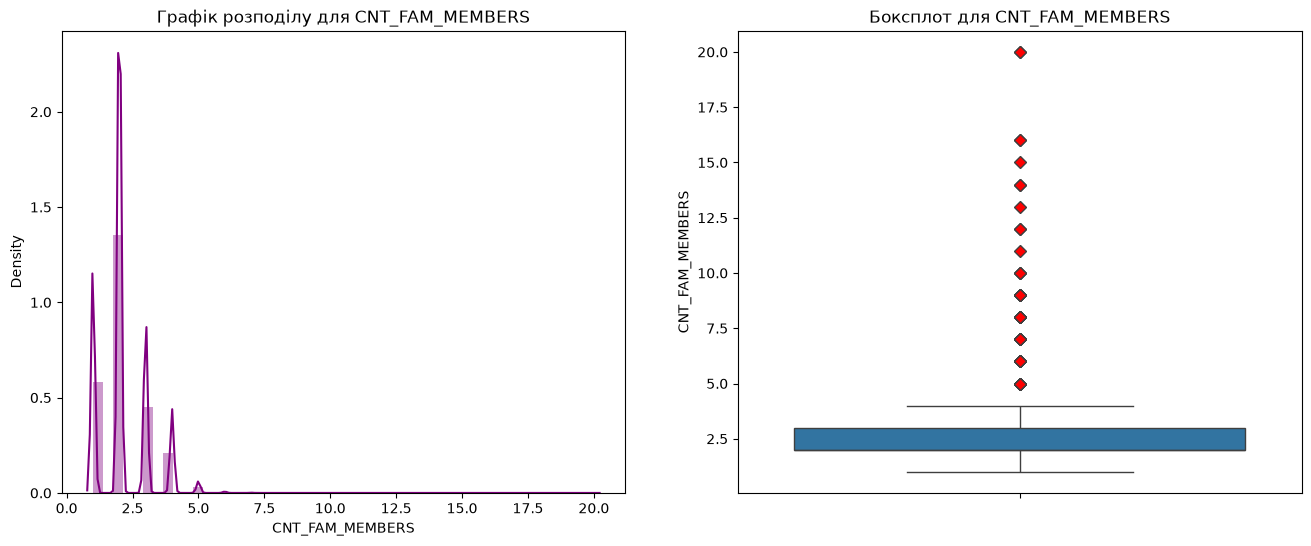

In [146]:
dist_box(df,'CNT_FAM_MEMBERS')

Розрахуємо IQR (Inter Quartile range)

In [147]:
Q1 = df['CNT_FAM_MEMBERS'].quantile(0.25)
Q3 = df['CNT_FAM_MEMBERS'].quantile(0.75)
IQR = Q3 - Q1
print(IQR)

1.0


Значення *до* (Q1 - 1,5 * IQR) та *після* (Q3 + 1,5 * IQR) є викидами

In [148]:
Min_value = (Q1 - 1.5 * IQR)
Max_value = (Q3 + 1.5 * IQR)
print("Мінімальне значення, до якого існують викиди: {}".format(Min_value))
print("Максимальне значення, після якого існують викиди: {}".format(Max_value))

Мінімальне значення, до якого існують викиди: 0.5
Максимальне значення, після якого існують викиди: 4.5


Кількість та відсоток викидів за правилом IQR (відсоток рахуємо від заявників з відомим значенням, 2 пропуски не враховуємо).  
Поріг беремо з функції `outlier_range` з лекції та зберігаємо в окрему змінну `fam_max`: глобальний `Max_value` перезаписується при аналізі кожної колонки, і наступні клітинки залежали б від порядку запуску

In [149]:
fam_max = outlier_range(df, 'CNT_FAM_MEMBERS')

fam_known = df['CNT_FAM_MEMBERS'].dropna()
outliers_count = (fam_known > fam_max).sum()
outliers_percentage = ((fam_known > fam_max).mean() * 100).round(2)
print('Викидів:', outliers_count, f'({outliers_percentage}% від {len(fam_known)} заявників з відомим значенням)')

Викидів: 4007 (1.3% від 307509 заявників з відомим значенням)


Перевірка зв'язку з `CNT_CHILDREN`: різниця між кількістю членів сім'ї та кількістю дітей

In [150]:
(df['CNT_FAM_MEMBERS'] - df['CNT_CHILDREN']).value_counts()

2.00    226207
1.00     81302
Name: count, dtype: int64

Порівняння викидів у двох колонках. Обидва пороги рахуємо функцією `outlier_range`: 2.5 для `CNT_CHILDREN` (як у прикладі вище) та 4.5 для `CNT_FAM_MEMBERS`.  
Підписи таблиці формуємо з тих самих змінних, щоб вони не розійшлися з порогами. Рядки з пропущеним `CNT_FAM_MEMBERS` виключаємо, щоб вони не потрапили в групу `False`

In [151]:
children_max = outlier_range(df, 'CNT_CHILDREN')

fam_df = df[df['CNT_FAM_MEMBERS'].notnull()]
pd.crosstab(fam_df['CNT_CHILDREN'] > children_max, fam_df['CNT_FAM_MEMBERS'] > fam_max,
            rownames = [f'CNT_CHILDREN > {children_max}'], colnames = [f'CNT_FAM_MEMBERS > {fam_max}'])

CNT_FAM_MEMBERS > 4.5,False,True
CNT_CHILDREN > 2.5,,
False,303237,0
True,265,4007


Подивимось на заявників з дуже великими сім'ями (10 і більше членів)

In [152]:
df[df['CNT_FAM_MEMBERS'] >= 10][['CNT_FAM_MEMBERS', 'CNT_CHILDREN', 'NAME_FAMILY_STATUS',
                                  'YEARS_BIRTH', 'AMT_INCOME_TOTAL', 'TARGET']]

,CNT_FAM_MEMBERS,CNT_CHILDREN,NAME_FAMILY_STATUS,YEARS_BIRTH,AMT_INCOME_TOTAL,TARGET
12615,10.00,8,Married,42,112500.00,0
23881,10.00,9,Single / not married,30,180000.00,1
34545,13.00,11,Married,47,315000.00,1
80948,14.00,12,Married,39,337500.00,0
132585,12.00,10,Married,31,67500.00,0
154317,10.00,8,Married,31,103500.00,0
155369,20.00,19,Single / not married,30,112500.00,0
171125,14.00,12,Married,38,225000.00,0
176011,15.00,14,Separated,49,225000.00,0
183878,16.00,14,Married,56,45000.00,0


**Спостереження**
- 2 пропущені значення (`count` = 307 509 з 307 511), на аналіз викидів це не впливає.
- Більшість заявників мають сім'ю з 1 - 4 осіб (98.7%): найчастіше 2 особи (51.5%), далі 1 (22.1%), 3 (17.1%) і 4 (8.0%).
- Q1 = 2, Q3 = 3, IQR = 1, тож за правилом IQR верхня межа - **4.5**, нижня - 0.5 (менших за 1 значень немає, тому викидів знизу немає).
- Значень більше 4.5, тобто **5 і більше членів сім'ї**, - 4 007 (1.3% заявників з відомим значенням). Діаграма розмаху показує їх як викиди.
- `CNT_FAM_MEMBERS` майже повністю визначається `CNT_CHILDREN`: різниця між ними завжди 1 (заявник без партнера) або 2 (заявник з партнером).  
  Тому всі викиди в цій колонці (5+ членів сім'ї) є також викидами в `CNT_CHILDREN` (3+ дітей). Зворотне не завжди так: 265 заявників з 3 дітьми без партнера (сім'я з 4 осіб) є викидами за `CNT_CHILDREN`, але не за `CNT_FAM_MEMBERS`.
- Від 7 членів сім'ї - лише по кілька десятків або одиниць заявників на значення. 10 і більше членів сім'ї - лише 14 заявників (максимум - 20 членів сім'ї при 19 дітях у заявників 28-30 років).  
  Такі значення виглядають або як одиничні випадки, або як помилки введення.

**Висновок**
- За правилом IQR викидами в `CNT_FAM_MEMBERS` є значення **5 і більше** (> 4.5), це 1.3% заявників з відомим значенням.
- Великі сім'ї з 5 - 6 осіб реальні, тому видаляти їх не варто: як і для `CNT_CHILDREN`, для них можна провести окремий аналіз.
- Значення **10 і більше** (14 заявників) - екстремальні викиди, ймовірно помилки введення, тож для них потрібна окрема перевірка.

### Аналіз стовпця `AMT_ANNUITY`

In [153]:
df['AMT_ANNUITY'].value_counts().sort_values(ascending = False).head()

AMT_ANNUITY
9000.00     6385
13500.00    5514
6750.00     2279
10125.00    2035
37800.00    1602
Name: count, dtype: int64

In [154]:
(df['AMT_ANNUITY'].value_counts(normalize = True).sort_values(ascending = False) * 100).head()

AMT_ANNUITY
9000.00    2.08
13500.00   1.79
6750.00    0.74
10125.00   0.66
37800.00   0.52
Name: proportion, dtype: float64

In [155]:
df['AMT_ANNUITY'].describe(percentiles = [0.25,0.75,0.99,0.999])

count   307499.00
mean     27108.57
std      14493.74
min       1615.50
25%      16524.00
50%      24903.00
75%      34596.00
99%      70006.50
99.9%   110047.50
max     258025.50
Name: AMT_ANNUITY, dtype: float64

Побудуємо графік для `AMT_ANNUITY`

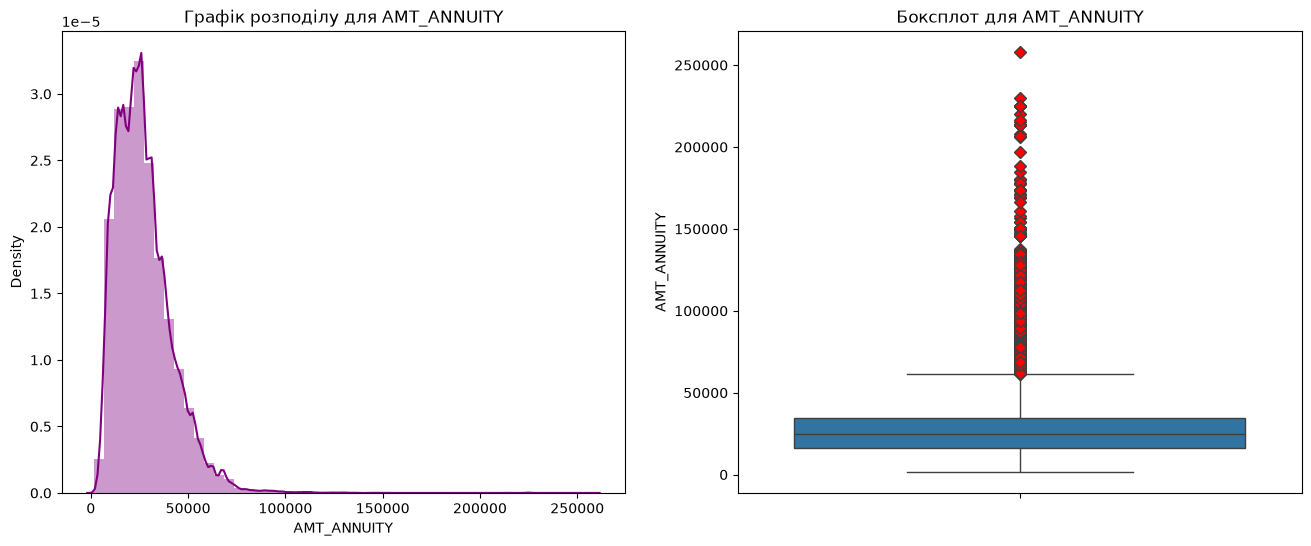

In [156]:
dist_box(df,'AMT_ANNUITY')

Розрахуємо IQR (Inter Quartile range)

In [157]:
Q1 = df['AMT_ANNUITY'].quantile(0.25)
Q3 = df['AMT_ANNUITY'].quantile(0.75)
IQR = Q3 - Q1
print(IQR)

18072.0


Значення *до* (Q1 - 1,5 * IQR) та *після* (Q3 + 1,5 * IQR) є викидами

In [158]:
Min_value = (Q1 - 1.5 * IQR)
Max_value = (Q3 + 1.5 * IQR)
print("Мінімальне значення, до якого існують викиди: {}".format(Min_value))
print("Максимальне значення, після якого існують викиди: {}".format(Max_value))

Мінімальне значення, до якого існують викиди: -10584.0
Максимальне значення, після якого існують викиди: 61704.0


Кількість та відсоток викидів за правилом IQR (відсоток рахуємо від заявників з відомим значенням, 12 пропусків не враховуємо). Поріг, як і вище, зберігаємо в окрему змінну `annuity_max`

In [159]:
annuity_max = outlier_range(df, 'AMT_ANNUITY')

annuity_known = df['AMT_ANNUITY'].dropna()
outliers_count = (annuity_known > annuity_max).sum()
outliers_percentage = ((annuity_known > annuity_max).mean() * 100).round(2)
print('Викидів:', outliers_count, f'({outliers_percentage}% від {len(annuity_known)} заявників з відомим значенням)')

Викидів: 7504 (2.44% від 307499 заявників з відомим значенням)


- Розподіл має довгий правий хвіст до ~258 тисяч.
- Як і для `AMT_INCOME_TOTAL`, побудуємо графік лише для значень нижче 99,9% перцентиля, тобто ~110 тисяч.

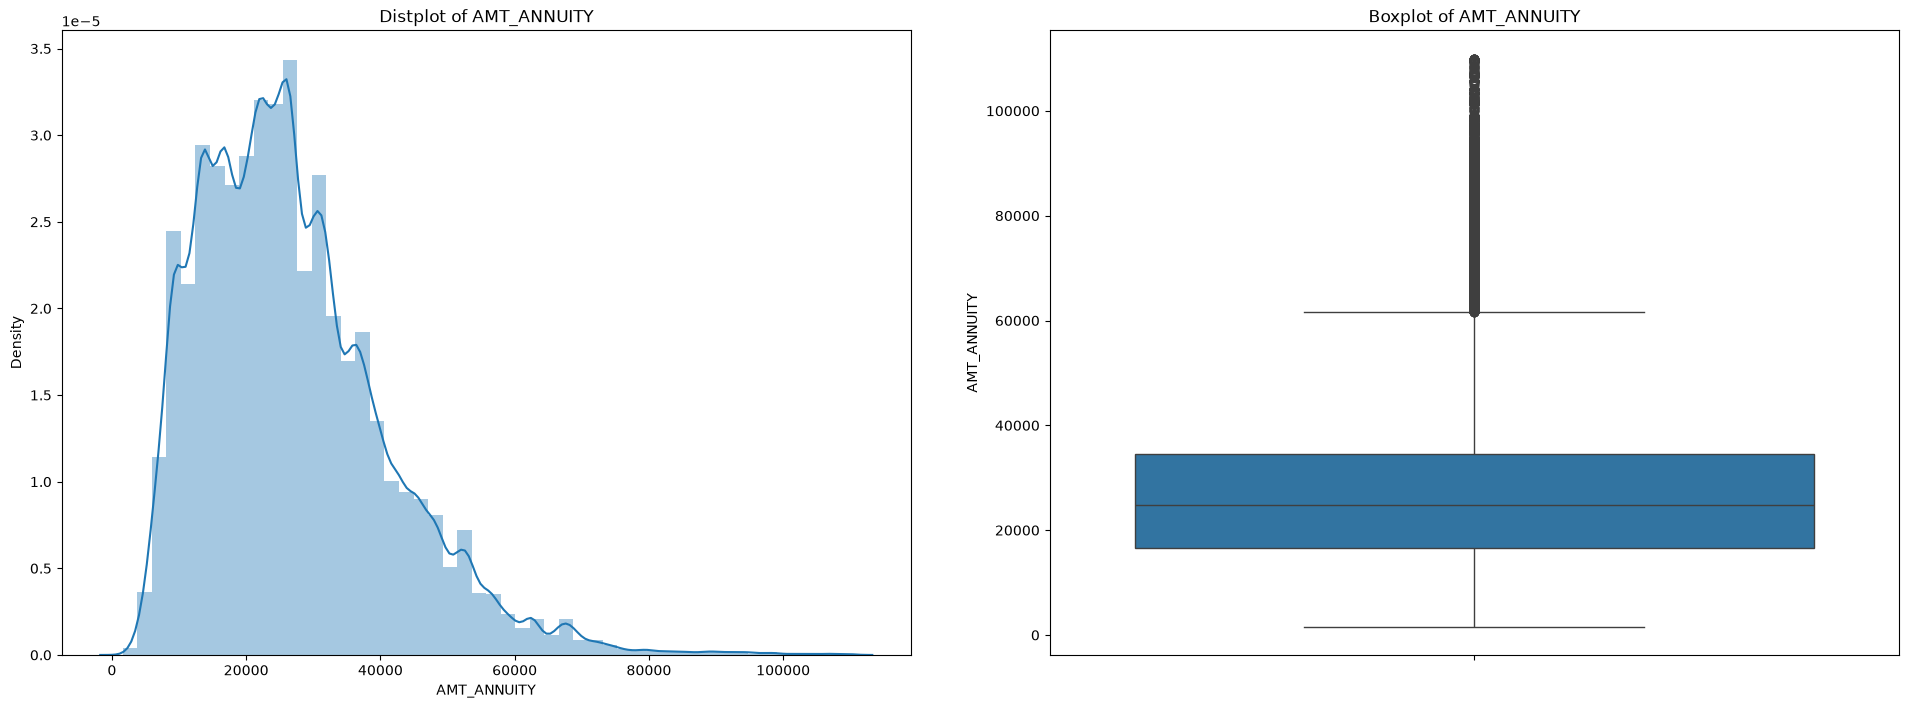

In [160]:
annuity_999 = df['AMT_ANNUITY'].quantile(0.999)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    plt.subplots(1,2 ,figsize = (20,8))

    plt.subplot(121)
    sns.distplot(df[df['AMT_ANNUITY'] < annuity_999].AMT_ANNUITY)
    pltname = 'Distplot of ' + 'AMT_ANNUITY'
    plt.title(pltname)

    plt.subplot(122)
    sns.boxplot(df[df['AMT_ANNUITY'] < annuity_999].AMT_ANNUITY)
    pltname = 'Boxplot of ' + 'AMT_ANNUITY'
    plt.title(pltname)

    plt.tight_layout(pad = 4)
    plt.show()

Перевірка, чи великі ануїтети узгоджуються з іншими даними: медіана суми кредиту та доходу для викидів (`True`) і решти заявників (`False`).  
12 рядків з пропущеним `AMT_ANNUITY` виключаємо, щоб вони не потрапили в групу `False`

In [161]:
annuity_df = df[df['AMT_ANNUITY'].notnull()]
annuity_df.groupby(annuity_df['AMT_ANNUITY'] > annuity_max)[['AMT_CREDIT', 'AMT_INCOME_TOTAL']].median()

,AMT_CREDIT,AMT_INCOME_TOTAL
AMT_ANNUITY,,
False,501435.00,140400.00
True,1350000.00,270000.00


Відношення ануїтетного платежу до суми кредиту (періодичність платежу в описі колонки не вказана - `Loan annuity`)

In [162]:
(df['AMT_ANNUITY'] / df['AMT_CREDIT']).describe(percentiles = [0.01,0.99])

count   307499.00
mean         0.05
std          0.02
min          0.02
1%           0.03
50%          0.05
99%          0.11
max          0.12
dtype: float64

Відношення ануїтетного платежу до доходу клієнта (`AMT_INCOME_TOTAL`, в описі колонки - `Income of the client`, періодичність доходу теж не вказана). Медіани вище порівнюють лише групи, тому перевіримо окремі записи

In [163]:
annuity_income_ratio = annuity_df['AMT_ANNUITY'] / annuity_df['AMT_INCOME_TOTAL']
annuity_income_ratio.describe(percentiles = [0.5,0.99,0.999])

count   307499.00
mean         0.18
std          0.09
min          0.00
50%          0.16
99%          0.48
99.9%        0.73
max          1.88
dtype: float64

Заявники, у яких ануїтетний платіж більший за дохід: кількість, скільки з них є викидами за IQR, та записи з найбільшим відношенням

In [164]:
annuity_gt_income = annuity_df[annuity_income_ratio > 1]
print('Ануїтетний платіж більший за дохід:', len(annuity_gt_income))
print('З них викидів за IQR:', (annuity_gt_income['AMT_ANNUITY'] > annuity_max).sum())

annuity_gt_income.assign(ANNUITY_INCOME_RATIO = annuity_income_ratio)[['AMT_ANNUITY', 'AMT_INCOME_TOTAL', 'AMT_CREDIT',
                                                                       'ANNUITY_INCOME_RATIO']].sort_values(by = 'ANNUITY_INCOME_RATIO', ascending = False).head()

Ануїтетний платіж більший за дохід: 33
З них викидів за IQR: 9


,AMT_ANNUITY,AMT_INCOME_TOTAL,AMT_CREDIT,ANNUITY_INCOME_RATIO
20727,48118.50,25650.00,2173500.00,1.88
197677,70677.00,45000.00,743031.00,1.57
247615,45724.50,31500.00,679500.00,1.45
226137,62698.50,45000.00,1800000.00,1.39
678,74191.50,54000.00,1885500.00,1.37


Подивимось на заявників з ануїтетом понад 99,9% перцентиль

In [165]:
df[df['AMT_ANNUITY'] > annuity_999][['AMT_ANNUITY', 'AMT_CREDIT', 'AMT_INCOME_TOTAL',
                                      'NAME_CONTRACT_TYPE', 'TARGET']].sort_values(by = 'AMT_ANNUITY', ascending = False).head(10)

,AMT_ANNUITY,AMT_CREDIT,AMT_INCOME_TOTAL,NAME_CONTRACT_TYPE,TARGET
17948,258025.50,4050000.00,783000.00,Cash loans,0
101508,230161.50,2303460.00,1575000.00,Cash loans,0
32100,225000.00,2250000.00,405000.00,Revolving loans,0
266148,225000.00,2250000.00,900000.00,Revolving loans,0
265026,225000.00,2250000.00,450000.00,Revolving loans,0
268278,225000.00,2250000.00,765000.00,Revolving loans,0
268455,225000.00,2250000.00,675000.00,Revolving loans,0
157614,225000.00,2250000.00,1125000.00,Revolving loans,0
184287,225000.00,2250000.00,630000.00,Revolving loans,0
132913,225000.00,2250000.00,675000.00,Revolving loans,0


Частка дефолтів у відсотках (`TARGET` = 1) та кількість рядків серед викидів за IQR (`True`) і решти заявників (`False`), також без рядків з пропущеним `AMT_ANNUITY`

In [166]:
annuity_df.groupby(annuity_df['AMT_ANNUITY'] > annuity_max)['TARGET'].agg(
    default_rate_pct=lambda s: s.mean() * 100,
    count='count'
)

,default_rate_pct,count
AMT_ANNUITY,,
False,8.17,299995
True,4.12,7504


**Спостереження**
- 12 пропущених значень (`count` = 307 499 з 307 511), на аналіз викидів це не впливає.
- Найчастіші значення "круглі" (9 000, 13 500, 6 750 ...), але чіткої моди немає: найчастіше значення зустрічається лише у ~2% рядків.
- Медіана - 24 903, середнє - 27 109. Розподіл скошений вправо: 99% значень менші за ~70 тисяч, а максимум - ~258 тисяч.
- Q1 = 16 524, Q3 = 34 596, IQR = 18 072, тож за правилом IQR верхня межа - **61 704**. Нижня межа від'ємна (-10 584), тому викидів знизу немає (мінімум - 1 615.5).
- Значень більше 61 704 - 7 504 (2.44% заявників з відомим значенням). Без значень вище 99,9% перцентиля (~110 тисяч) розподіл виглядає плавним, але діаграма розмаху все одно показує довгий хвіст після ~62 тисяч.
- На рівні груп великі ануїтети не схожі на помилки: у таких заявників і кредит (медіана 1 350 000 проти 501 435), і дохід (медіана 270 000 проти 140 400) значно вищі. Відношення ануїтетного платежу до суми кредиту для всіх заявників знаходиться у вузькому діапазоні (~2% - 12.4%). Наприклад, максимальний ануїтет 258 025.5 відповідає максимальному кредиту 4 050 000.
- Але на рівні окремих записів є несостиковки: у **33 заявників ануїтетний платіж більший за дохід** (до 1.88 раза), 9 з них - викиди за IQR. Наприклад, дохід 45 000 і ануїтет 70 677. Якщо обидві величини вказані за однаковий період, такі записи виглядають сумнівно.
- Частка дефолтів серед викидів - ~4.1%, тобто приблизно вдвічі менша, ніж у решти заявників (~8.2%): великі ануїтети платять заможніші клієнти.

**Висновок**
- За правилом IQR викидами в `AMT_ANNUITY` є значення **понад 61 704** (2.44% заявників з відомим значенням).
- Екстремальні викиди - значення понад 99,9% перцентиль (**~110 тисяч**, 306 заявників).
- На рівні груп ці значення узгоджуються з сумою кредиту та доходом, тому підстав автоматично видаляти їх немає. До того ж разом з ними зникла б група з нижчою часткою дефолтів.
- Проте є окремі записи (33 заявники), де ануїтетний платіж більший за дохід. Їх варто перевірити окремо.
- Під час подальшого аналізу викиди можна розглядати окремо або обмежити графіки (як вище) порогом 99,9%.

# Розбиття на біни безперервних колонок для аналізу

### Категоризація стовпця `AMT_GOODS_PRICE

In [167]:
df['AMT_GOODS_PRICE'].value_counts().sort_values(ascending = False).head()

AMT_GOODS_PRICE
450000.00    26029
225000.00    25294
675000.00    24969
900000.00    15417
270000.00    11479
Name: count, dtype: int64

In [168]:
(df['AMT_GOODS_PRICE'].value_counts(normalize = True).sort_values(ascending = False) * 100).head()

AMT_GOODS_PRICE
450000.00   8.46
225000.00   8.23
675000.00   8.12
900000.00   5.01
270000.00   3.73
Name: proportion, dtype: float64

Подивимось статистичний звіт для `AMT_GOODS_PRICE

In [169]:
df['AMT_GOODS_PRICE'].describe(percentiles = [0.25,0.75,0.99,0.9999])

count     307511.00
mean      538162.28
std       369405.27
min        40500.00
25%       238500.00
50%       450000.00
75%       679500.00
99%      1800000.00
99.99%   2933964.00
max      4050000.00
Name: AMT_GOODS_PRICE, dtype: float64

Розподілимо значення в `AMT_GOODS_PRICE` на 5 бінів і створимо новий стовпець `AMT_GOODS_PRICE_CATEGORY`.

In [170]:
df['AMT_GOODS_PRICE_CATEGORY'] = pd.cut(df['AMT_GOODS_PRICE'],
                                        bins = 5, labels = ['very low', 'low', 'medium', 'high', 'very high'])

Перевірка заповнення значень згідно з очікуванням

In [171]:
df['AMT_GOODS_PRICE_CATEGORY'].value_counts()

AMT_GOODS_PRICE_CATEGORY
very low     247244
low           56094
medium         4108
high             47
very high        18
Name: count, dtype: int64

### Категоризація стовпця `YEARS_BIRTH`

Ми будемо класифікувати `YEARS_BIRTH` замість `DAYS_BIRTH`, оскільки роки легше інтерпретувати, ніж дні

In [172]:
df['YEARS_BIRTH'].value_counts().sort_values(ascending = False).head()

YEARS_BIRTH
39    9023
38    8793
37    8727
40    8602
41    8495
Name: count, dtype: int64

In [173]:
(df['YEARS_BIRTH'].value_counts(normalize = True).sort_values(ascending = False) * 100).head()

YEARS_BIRTH
39   2.93
38   2.86
37   2.84
40   2.80
41   2.76
Name: proportion, dtype: float64

Подивимось статистичний звіт для  `YEARS_BIRTH`

In [174]:
df['YEARS_BIRTH'].describe(percentiles = [0.25,0.75,0.99,0.9999])

count    307511.00
mean         43.94
std          11.96
min          21.00
25%          34.00
50%          43.00
75%          54.00
99%          67.00
99.99%       69.00
max          69.00
Name: YEARS_BIRTH, dtype: float64

Категоризуймо значення з `YEARS_BIRTH` у новий стовпець `YEARS_BIRTH_CATEGORY`.

In [175]:
df['YEARS_BIRTH_CATEGORY'] = df['YEARS_BIRTH'].apply(age_cat)

Перевірка заповнення значень згідно з очікуванням

In [176]:
df['YEARS_BIRTH_CATEGORY'].value_counts().sort_values(ascending = False)

YEARS_BIRTH_CATEGORY
30-40    82770
40-50    75509
50-60    67955
20-30    48869
60-70    32408
Name: count, dtype: int64

### Категоризація стовпця `YEARS_REGISTRATION`

Ми будемо класифікувати `YEARS_REGISTRATION` замість `DAYS_REGISTRATION`, оскільки роки легше інтерпретувати, ніж дні

In [177]:
df['YEARS_REGISTRATION'].value_counts().sort_values(ascending = False).head()

YEARS_REGISTRATION
1     15661
2     15564
3     13894
13    12866
12    12697
Name: count, dtype: int64

In [178]:
(df['YEARS_REGISTRATION'].value_counts(normalize = True).sort_values(ascending = False) * 100).head()

YEARS_REGISTRATION
1    5.09
2    5.06
3    4.52
13   4.18
12   4.13
Name: proportion, dtype: float64

Подивимось статистичний звіт для `YEARS_REGISTRATION`

In [179]:
df['YEARS_REGISTRATION'].describe(percentiles = [0.25,0.75,0.99,0.9999])

count    307511.00
mean         13.66
std           9.66
min           0.00
25%           6.00
50%          12.00
75%          20.00
99%          38.00
99.99%       54.25
max          68.00
Name: YEARS_REGISTRATION, dtype: float64

Категоризуймо значення з `YEARS_REGISTRATION` в новий стовпець `YEARS_REGISTRATION_CATEGORY`.

In [180]:
df['YEARS_REGISTRATION_CATEGORY'] = df['YEARS_REGISTRATION'].apply(age_cat)

Перевірка заповнення значень згідно з очікуванням

In [181]:
df['YEARS_REGISTRATION_CATEGORY'].value_counts().sort_values(ascending = False)

YEARS_REGISTRATION_CATEGORY
0-20     230697
20-30     59288
30-40     16051
40-50      1406
50-60        60
60-70         9
Name: count, dtype: int64

# Зберігання оновлених даних зі стисненням

In [182]:
# filename = "drive/MyDrive/Machine Learning для людей/data/credit/application_data_processed"
# compression_options = dict(method='zip', archive_name=f'{filename}.csv')
# df.to_csv(f'{filename}.zip', compression=compression_options, index=False)

# Перевірка дисбалансу для цільового стовпця `TARGET`

### Аналіз стовпця `TARGET`

In [183]:
df['TARGET'].value_counts().sort_values(ascending = False)

TARGET
0    282686
1     24825
Name: count, dtype: int64

In [184]:
df['TARGET'].value_counts(normalize = True).sort_values(ascending = False) * 100

TARGET
0   91.93
1    8.07
Name: proportion, dtype: float64

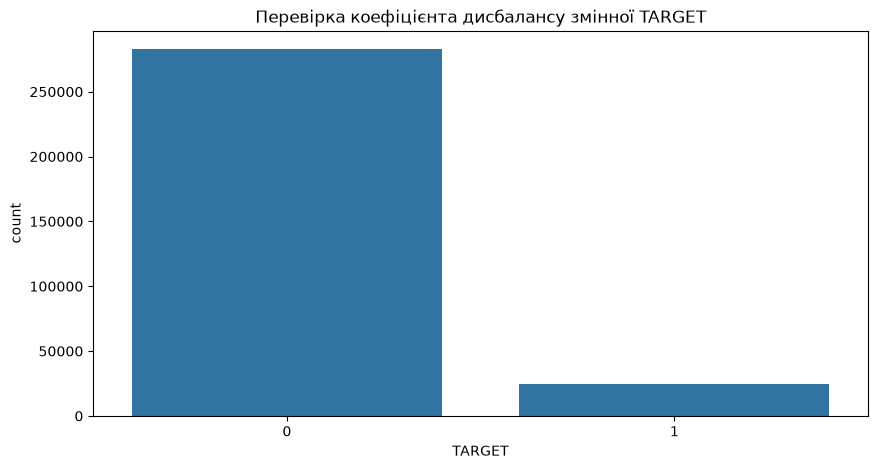

In [185]:
plt.figure(figsize = (10,5))
sns.countplot(x = df['TARGET'], data = df)
plt.title('Перевірка коефіцієнта дисбалансу змінної TARGET')
plt.show()

**Спостереження**

- Ми маємо дисбаланс у змінній `TARGET` на основі % спостережень
 - Значення `TARGET` 1 - це клієнт, який має труднощі з оплатою (прострочення платежу більше ніж на X днів принаймні за одним з перших Y платежів за кредитом). Це лише 8,07% даних
 - Значення `TARGET` 0 - всі інші випадки, окрім 1. Це 91,93% даних

# Розподіл даних на основі `TARGET`

### Створіть новий фрейм даних зі значенням `TARGET` 1
- Значення `TARGET` 1 представляє клієнта з платіжними труднощами (він/вона прострочив платіж більш ніж на X днів принаймні по одному з перших Y платежів за кредитом). Це лише 8,07% даних

In [186]:
df1 = df[df['TARGET'] == 1]

In [187]:
df1.TARGET.value_counts()

TARGET
1    24825
Name: count, dtype: int64

### Створити новий фрейм даних зі значенням `TARGET` 0
- Значення `TARGET` 0 представляє всі інші випадки, крім 1. Це 91.93% даних

In [188]:
df0 = df[df['TARGET'] == 0]

In [189]:
df0.TARGET.value_counts()

TARGET
0    282686
Name: count, dtype: int64

# Одномірний аналіз категоріальних змінних

### Аналіз стовпця `NAME_CONTRACT_TYPE`

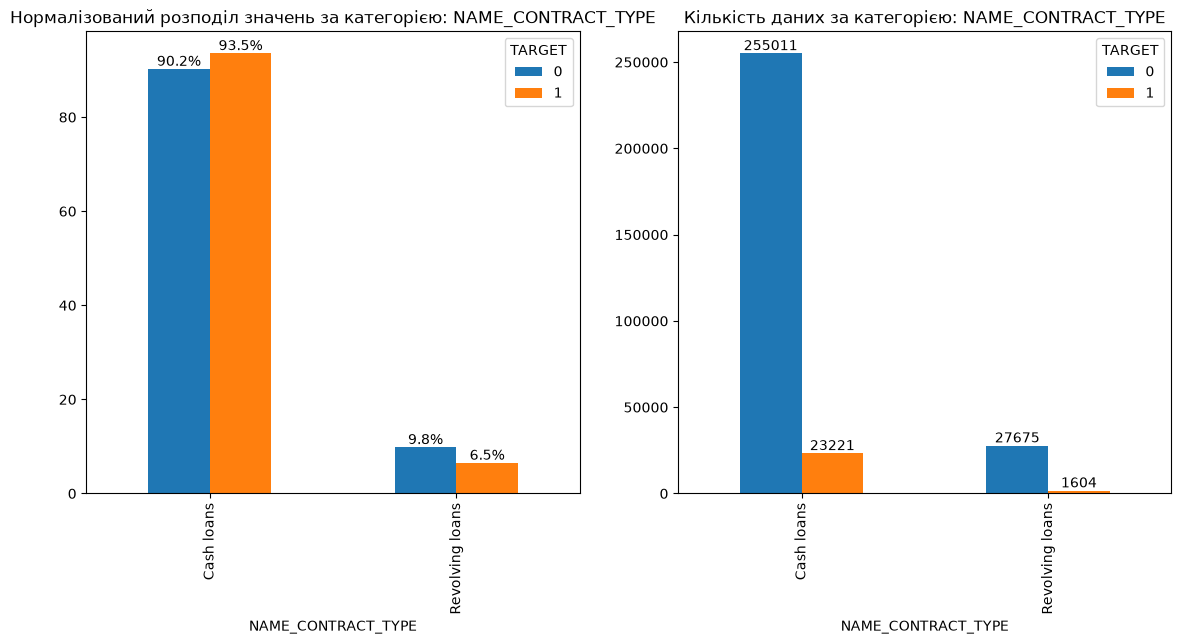

In [190]:
uni_cat_target_compare(df, 'NAME_CONTRACT_TYPE')

**Спостереження**

- Дивлячись на гістограми, ми не бачимо суттєвих відмінностей у `NAME_CONTRACT_TYPE` між клієнтами, які мають труднощі з оплатою, та клієнтами, які платять вчасно

**Висновок**
- Колонка `NAME_CONTRACT_TYPE` не надає жодних переконливих доказів на користь клієнтів, які мають труднощі з оплатою АБО вчасно сплачують

# ДЗ 4. Одновимірний аналіз категоріальної колонки

За наведеним прикладом вище, проведіть аналіз залежності між категоріальною колонкою і цільовою для колонок
- CODE_GENDER
- FLAG_OWN_CAR

Опціонально (для тих, кому цікаво дослідити більше даних)
- NAME_INCOME_TYPE
- NAME_EDUCATION_TYPE
- NAME_FAMILY_STATUS


Чи є вплив цих змінних на цільову та який саме?

### Аналіз стовпця `CODE_GENDER`

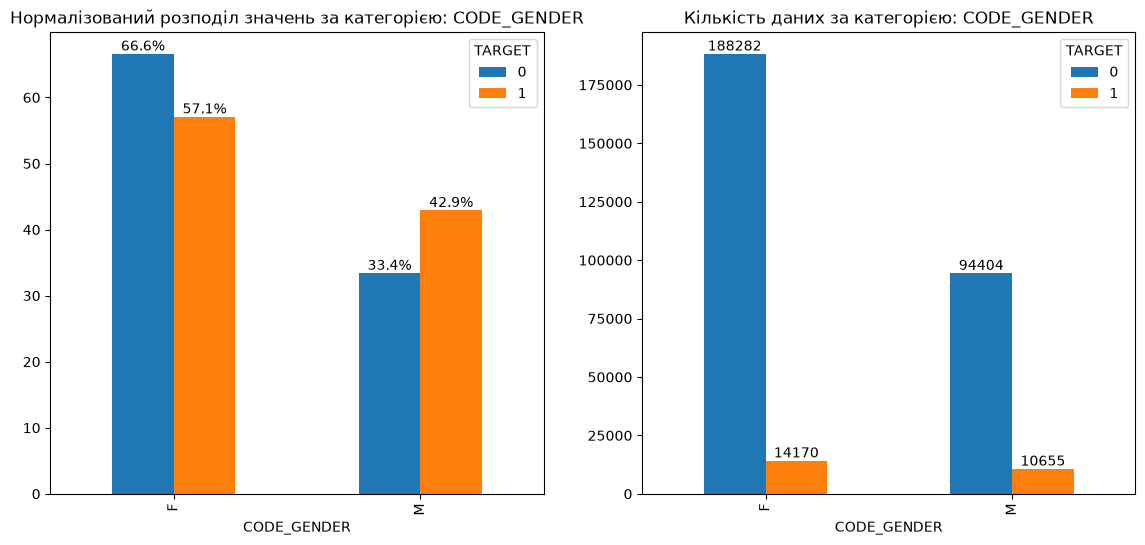

In [191]:
uni_cat_target_compare(df, 'CODE_GENDER')

Частка клієнтів з платіжними труднощами у відсотках (`TARGET` = 1) та кількість заявників для кожної статі (4 значення `XNA` раніше замінені на `F`)

In [192]:
gender_target = df.groupby('CODE_GENDER')['TARGET'].agg(target_rate_pct = 'mean', count = 'count')
gender_target['target_rate_pct'] = (gender_target['target_rate_pct'] * 100).round(2)
gender_target

,target_rate_pct,count
CODE_GENDER,,
F,7.00,202452
M,10.14,105059


Розподіл статі всередині кожної групи `TARGET` у відсотках (кожен стовпець у сумі дає 100%)

In [193]:
(pd.crosstab(df['CODE_GENDER'], df['TARGET'], normalize = 'columns') * 100).round(2)

TARGET,0,1
CODE_GENDER,,
F,66.60,57.08
M,33.40,42.92


**Спостереження**
- Жінок серед заявників приблизно вдвічі більше, ніж чоловіків: 202 452 (65.8%) проти 105 059 (34.2%).
- Серед клієнтів без зафіксованих платіжних труднощів (`TARGET` = 0) жінок 66.6%, а серед клієнтів з платіжними труднощами (`TARGET` = 1) - лише 57.1%. Частка чоловіків, навпаки, зростає з 33.4% до 42.9%.
- Частка клієнтів з платіжними труднощами серед чоловіків - **10.14%**, серед жінок - **7.00%**, тобто у чоловіків вона приблизно в 1.45 раза вища (середня по всіх заявниках - 8.07%).

**Висновок**
- Між `CODE_GENDER` і цільовою змінною є зв'язок: серед чоловіків частка клієнтів з платіжними труднощами (`TARGET` = 1) вища, ніж серед жінок (10.14% проти 7.00%).
- Стать можна використовувати як одну з ознак для прогнозування `TARGET`, але сама по собі вона не розділяє клієнтів: навіть серед чоловіків ~90% не мають зафіксованих платіжних труднощів.

### Аналіз стовпця `FLAG_OWN_CAR`

Нагадування: на початку ноутбука значення `FLAG_OWN_CAR` перетворені з `Y`/`N` на `1`/`0` (`1` - заявник має автомобіль)

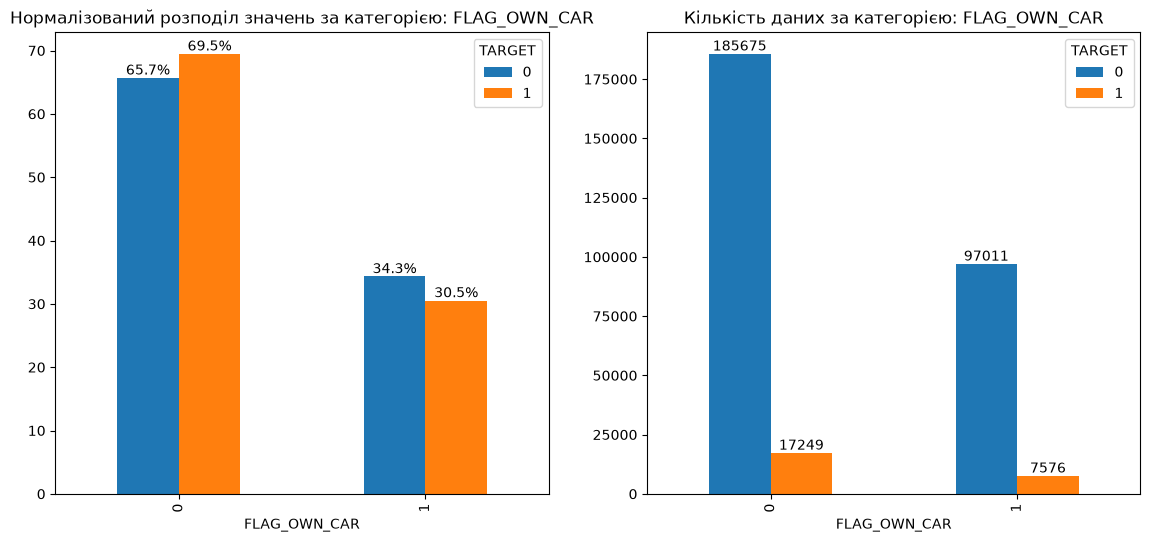

In [194]:
uni_cat_target_compare(df, 'FLAG_OWN_CAR')

Частка клієнтів з платіжними труднощами у відсотках (`TARGET` = 1) та кількість заявників з автомобілем (`1`) і без нього (`0`)

In [195]:
car_target = df.groupby('FLAG_OWN_CAR')['TARGET'].agg(target_rate_pct = 'mean', count = 'count')
car_target['target_rate_pct'] = (car_target['target_rate_pct'] * 100).round(2)
car_target

,target_rate_pct,count
FLAG_OWN_CAR,,
0,8.50,202924
1,7.24,104587


Розподіл заявників з автомобілем і без нього всередині кожної групи `TARGET` у відсотках (кожен стовпець у сумі дає 100%)

In [196]:
(pd.crosstab(df['FLAG_OWN_CAR'], df['TARGET'], normalize = 'columns') * 100).round(2)

TARGET,0,1
FLAG_OWN_CAR,,
0,65.68,69.48
1,34.32,30.52


**Спостереження**
- Більшість заявників не мають автомобіля: 202 924 (66.0%) проти 104 587 (34.0%) з автомобілем.
- Серед клієнтів без зафіксованих платіжних труднощів (`TARGET` = 0) власників автомобіля 34.3%, а серед клієнтів з платіжними труднощами (`TARGET` = 1) - 30.5%. Різниця є, але помітно менша, ніж для `CODE_GENDER` (~4 в.п. проти ~9.5 в.п.).
- Частка клієнтів з платіжними труднощами серед заявників без автомобіля - **8.50%**, серед власників автомобіля - **7.24%**, тобто у заявників без автомобіля вона приблизно в 1.17 раза вища.

**Висновок**
- Між `FLAG_OWN_CAR` і цільовою змінною є слабкий зв'язок: серед власників автомобіля частка клієнтів з платіжними труднощами (`TARGET` = 1) трохи нижча (7.24% проти 8.50%).
- Можливе пояснення - наявність автомобіля пов'язана з вищим доходом / кращим фінансовим станом. Але це лише гіпотеза: у цьому аналізі вона не перевірялась.
- Зв'язок слабший, ніж у `CODE_GENDER`, тому окремо ця ознака мало допомагає відрізнити клієнтів з платіжними труднощами, але може бути корисною разом з іншими ознаками.

# Кореляційний аналіз числових змінних

### Побудова кореляційної матриці для випадків із платіжними труднощами

In [197]:
df1.select_dtypes(include=["int64","float64"]).shape

(24825, 39)

Є 66 числових стовпчиків. Створимо кореляційну матрицб `corr` для кращого перегляду результатів

In [198]:
corr_df1 = df1.select_dtypes(include=["int64","float64"]).corr()

In [199]:
corr_df1.head()

,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,EXT_SOURCE_2,EXT_SOURCE_3,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,YEARS_BIRTH,YEARS_EMPLOYED,YEARS_REGISTRATION,YEARS_ID_PUBLISH,YEARS_LAST_PHONE_CHANGE
TARGET,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CNT_CHILDREN,NaN,1.00,0.00,-0.00,0.03,-0.01,-0.03,-0.26,-0.19,-0.15,0.03,0.89,0.04,0.04,-0.02,-0.02,-0.02,-0.01,-0.00,0.05,0.05,-0.01,-0.02,0.03,0.00,0.03,-0.01,-0.01,-0.00,-0.01,-0.01,-0.01,-0.02,-0.04,-0.26,-0.19,-0.15,0.03,-0.01
AMT_INCOME_TOTAL,NaN,0.00,1.00,0.04,0.05,0.04,0.01,-0.00,-0.01,-0.00,0.00,0.01,-0.02,-0.02,0.01,0.01,0.01,0.01,-0.00,-0.00,-0.00,0.01,-0.02,-0.00,-0.01,-0.00,-0.00,0.00,0.00,-0.00,0.00,0.00,-0.00,0.00,-0.00,-0.01,0.00,0.00,0.00
AMT_CREDIT,NaN,-0.00,0.04,1.00,0.75,0.98,0.07,0.14,0.00,0.03,0.05,0.05,-0.06,-0.07,0.03,0.02,0.03,0.03,-0.03,-0.04,-0.02,0.12,0.08,0.02,-0.03,0.02,-0.03,0.11,-0.01,0.00,0.01,0.06,-0.02,-0.04,0.14,0.00,0.03,0.05,0.11
AMT_ANNUITY,NaN,0.03,0.05,0.75,1.00,0.75,0.07,0.01,-0.08,-0.03,0.02,0.08,-0.07,-0.09,0.03,0.03,0.07,0.06,-0.01,0.00,0.01,0.12,0.04,0.01,-0.02,0.01,-0.03,0.08,0.01,-0.00,0.03,0.05,-0.01,-0.01,0.01,-0.08,-0.03,0.02,0.08


Створимо теплову карту для перегляду кореляцій вище 80% і 99,99%

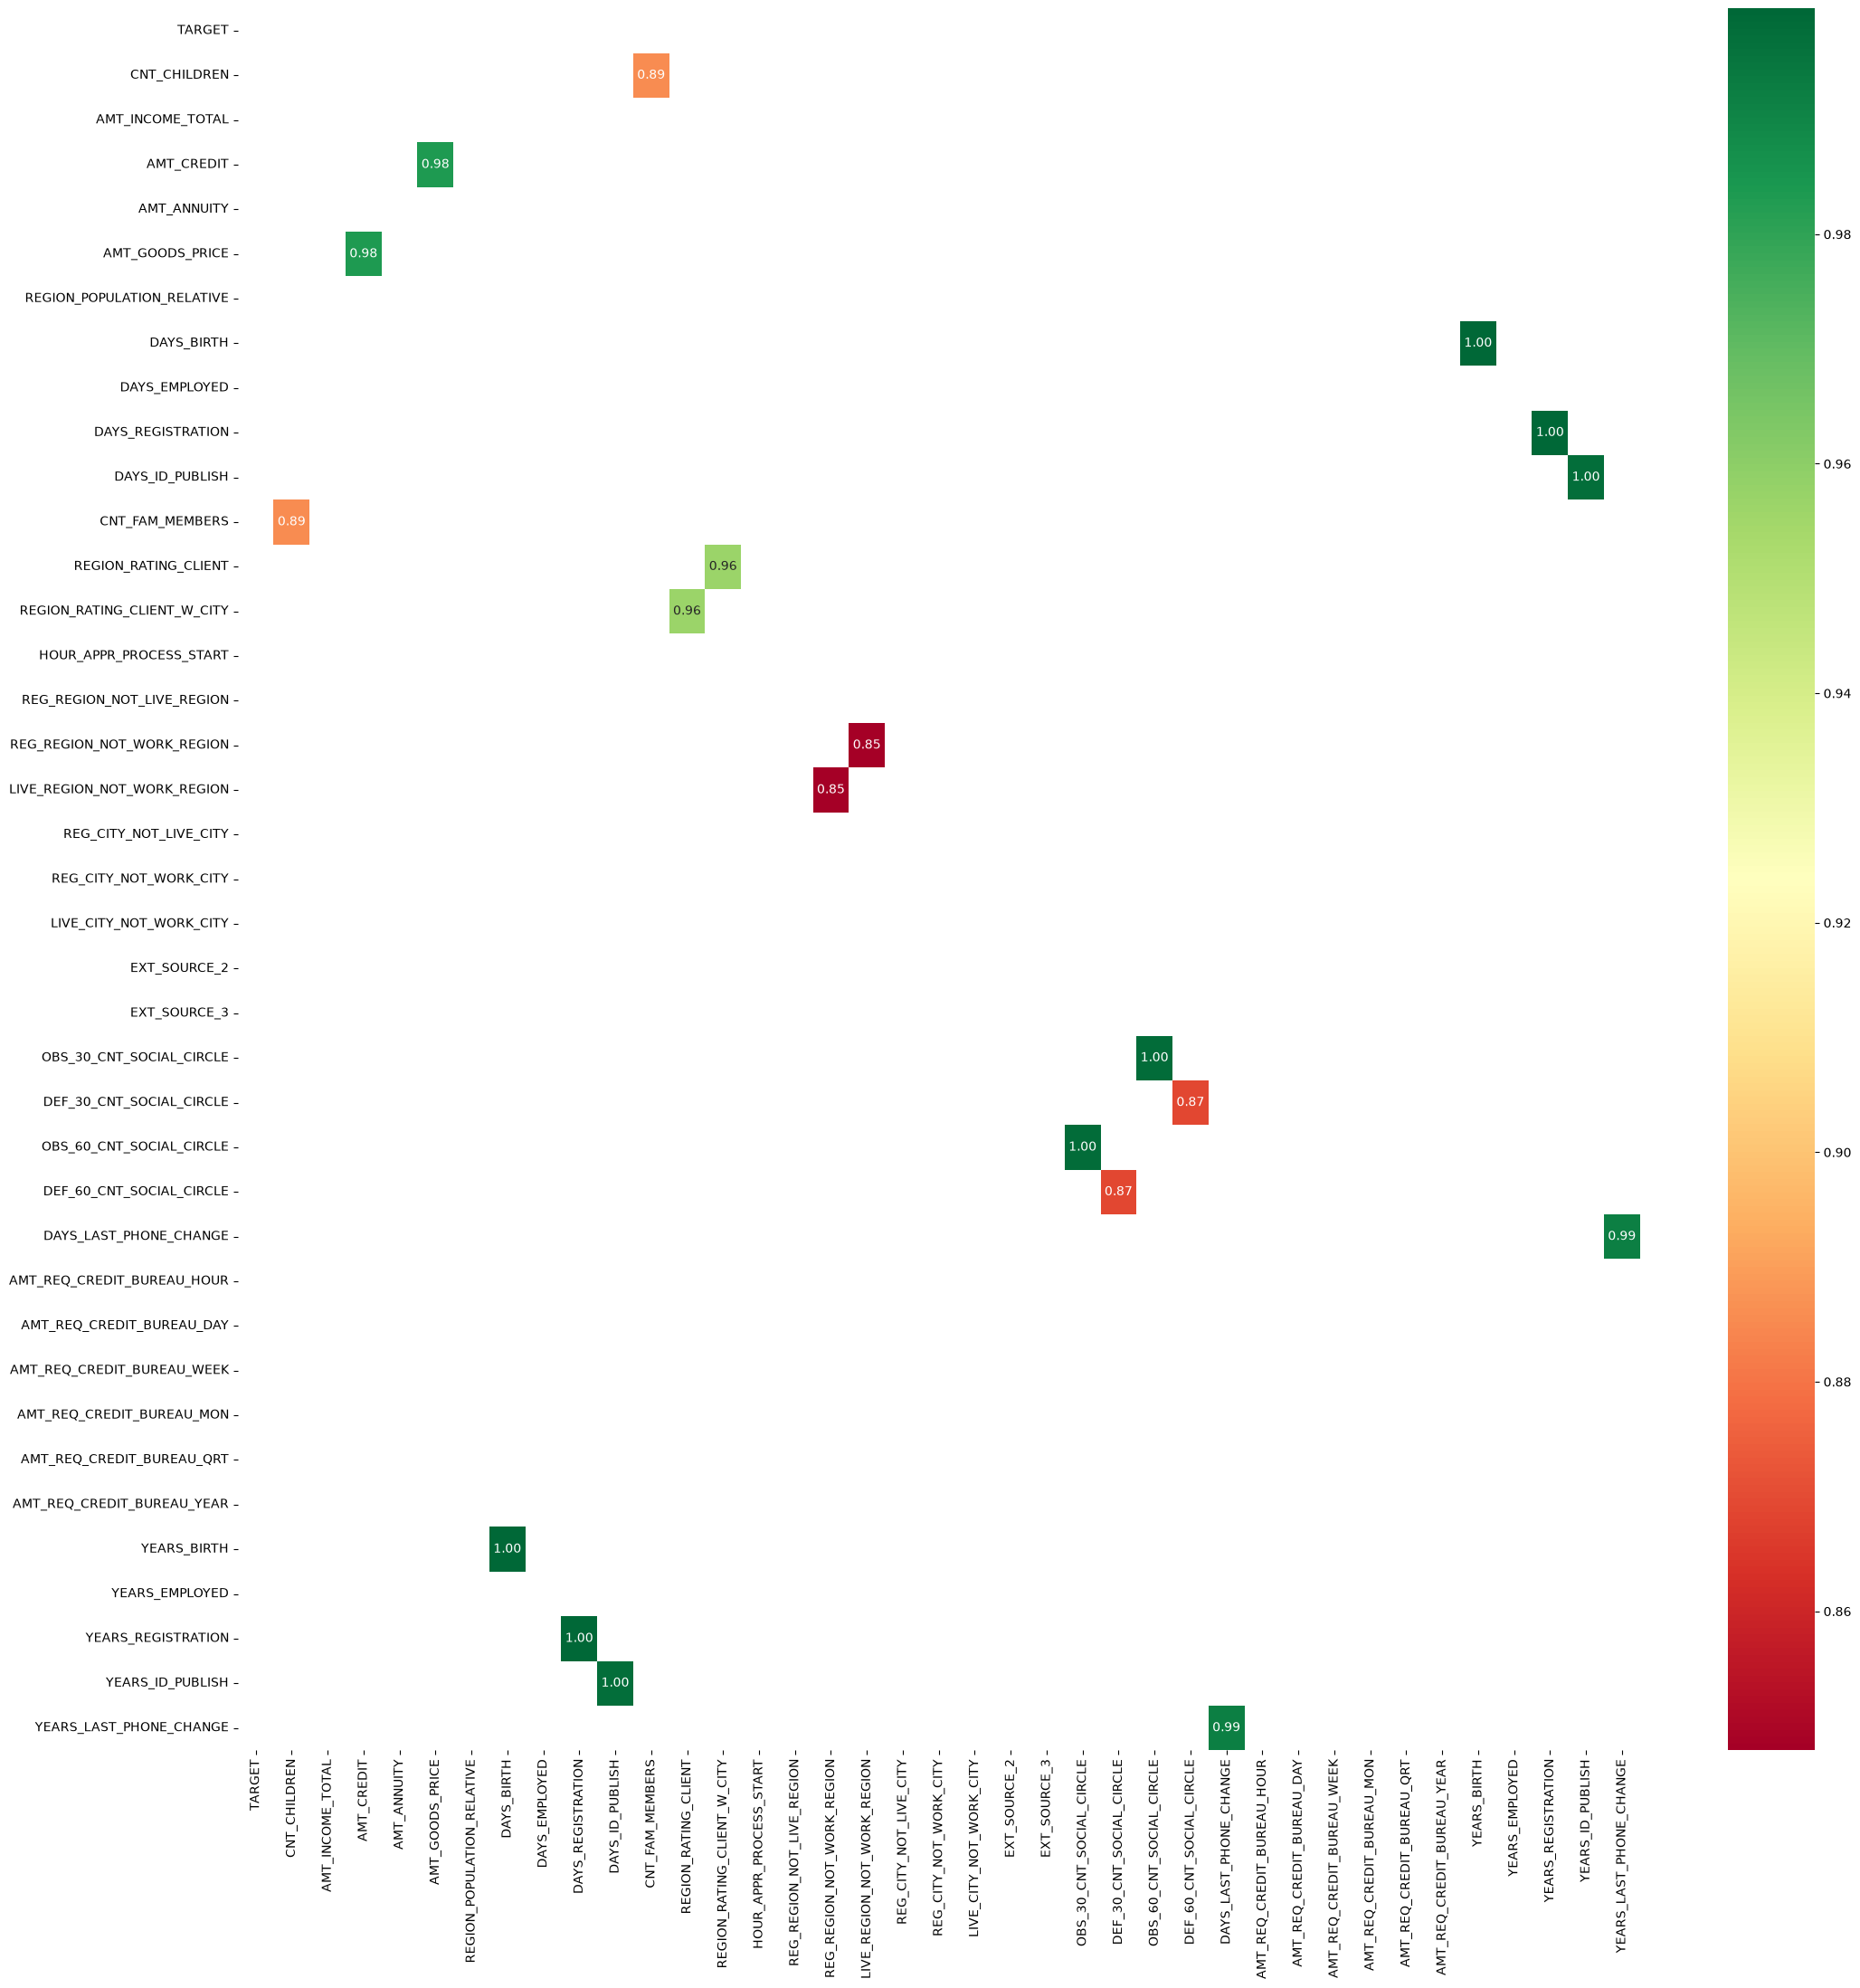

In [200]:
plt.figure(figsize = (25,25))
sns.heatmap(data = corr_df1[(corr_df1 >= 0.8) & (corr_df1 < 0.9999)], annot = True, cmap = "RdYlGn", cbar = True, fmt='.2f')
plt.show()

### Подивимось на 10 найкращих кореляцій для випадків із платіжними труднощами

In [201]:
corr_df1[corr_df1 <= 0.99].unstack().sort_values(ascending = False).head(22)

AMT_CREDIT                   AMT_GOODS_PRICE               0.98
AMT_GOODS_PRICE              AMT_CREDIT                    0.98
REGION_RATING_CLIENT         REGION_RATING_CLIENT_W_CITY   0.96
REGION_RATING_CLIENT_W_CITY  REGION_RATING_CLIENT          0.96
CNT_FAM_MEMBERS              CNT_CHILDREN                  0.89
CNT_CHILDREN                 CNT_FAM_MEMBERS               0.89
DEF_60_CNT_SOCIAL_CIRCLE     DEF_30_CNT_SOCIAL_CIRCLE      0.87
DEF_30_CNT_SOCIAL_CIRCLE     DEF_60_CNT_SOCIAL_CIRCLE      0.87
LIVE_REGION_NOT_WORK_REGION  REG_REGION_NOT_WORK_REGION    0.85
REG_REGION_NOT_WORK_REGION   LIVE_REGION_NOT_WORK_REGION   0.85
REG_CITY_NOT_WORK_CITY       LIVE_CITY_NOT_WORK_CITY       0.78
LIVE_CITY_NOT_WORK_CITY      REG_CITY_NOT_WORK_CITY        0.78
AMT_GOODS_PRICE              AMT_ANNUITY                   0.75
AMT_ANNUITY                  AMT_GOODS_PRICE               0.75
AMT_CREDIT                   AMT_ANNUITY                   0.75
AMT_ANNUITY                  AMT_CREDIT 

Оскільки у нас є комбінації, що повторюються, дивлячись на наведену вище таблицю і видаляючи дублі, ми отримуємо топ-10 кореляцій, як показано нижче:

- AMT_GOODS_PRICE -              AMT_CREDIT                    0.98
- REGION_RATING_CLIENT -         REGION_RATING_CLIENT_W_CITY   0.96
- CNT_FAM_MEMBERS -              CNT_CHILDREN                  0.89
- DEF_60_CNT_SOCIAL_CIRCLE -     DEF_30_CNT_SOCIAL_CIRCLE      0.87
- REG_REGION_NOT_WORK_REGION -   LIVE_REGION_NOT_WORK_REGION   0.85
- LIVE_CITY_NOT_WORK_CITY -      REG_CITY_NOT_WORK_CITY        0.78
- AMT_ANNUITY -                  AMT_GOODS_PRICE               0.75
- AMT_ANNUITY -                  AMT_CREDIT                    0.75
- DAYS_EMPLOYED -                FLAG_DOCUMENT_6               0.62
- DAYS_BIRTH -                   DAYS_EMPLOYED                 0.58

### Побудова кореляційної матриці для випадків із вчасними платежеми

In [202]:
df0.select_dtypes(include=["int64","float64"]).shape

(282686, 39)

Є 66 числових стовпчиків. Створимо кореляційну матрицю `corr` для кращого перегляду результатів

In [203]:
corr_df0 = df0.select_dtypes(include=["int64","float64"]).corr()

In [204]:
corr_df0.head()

,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,EXT_SOURCE_2,EXT_SOURCE_3,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,YEARS_BIRTH,YEARS_EMPLOYED,YEARS_REGISTRATION,YEARS_ID_PUBLISH,YEARS_LAST_PHONE_CHANGE
TARGET,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CNT_CHILDREN,NaN,1.00,0.03,0.00,0.02,-0.00,-0.02,-0.34,-0.25,-0.19,0.03,0.88,0.02,0.02,-0.01,-0.01,0.01,0.02,0.02,0.07,0.07,-0.02,-0.04,0.01,-0.00,0.01,-0.00,0.01,-0.00,0.00,-0.00,-0.01,-0.01,-0.04,-0.34,-0.25,-0.19,0.03,0.01
AMT_INCOME_TOTAL,NaN,0.03,1.00,0.34,0.42,0.35,0.17,-0.06,-0.14,-0.06,-0.02,0.03,-0.19,-0.20,0.08,0.07,0.14,0.13,0.01,0.02,0.02,0.14,-0.07,-0.03,-0.03,-0.03,-0.03,0.04,0.00,0.01,0.01,0.06,0.01,0.03,-0.06,-0.14,-0.06,-0.02,0.04
AMT_CREDIT,NaN,0.00,0.34,1.00,0.77,0.99,0.10,0.05,-0.07,-0.01,0.00,0.06,-0.10,-0.11,0.05,0.02,0.05,0.05,-0.03,-0.02,0.00,0.13,0.04,-0.00,-0.02,-0.00,-0.02,0.07,-0.00,0.00,-0.00,0.05,0.02,-0.05,0.05,-0.07,-0.01,0.00,0.07
AMT_ANNUITY,NaN,0.02,0.42,0.77,1.00,0.78,0.12,-0.01,-0.10,-0.04,-0.01,0.08,-0.13,-0.15,0.05,0.04,0.08,0.08,-0.01,0.00,0.01,0.13,0.03,-0.01,-0.02,-0.01,-0.02,0.06,0.00,0.00,0.01,0.04,0.01,-0.01,-0.01,-0.10,-0.04,-0.01,0.06


Створимо теплову карту для перегляду кореляцій вище 80% і 99,99%

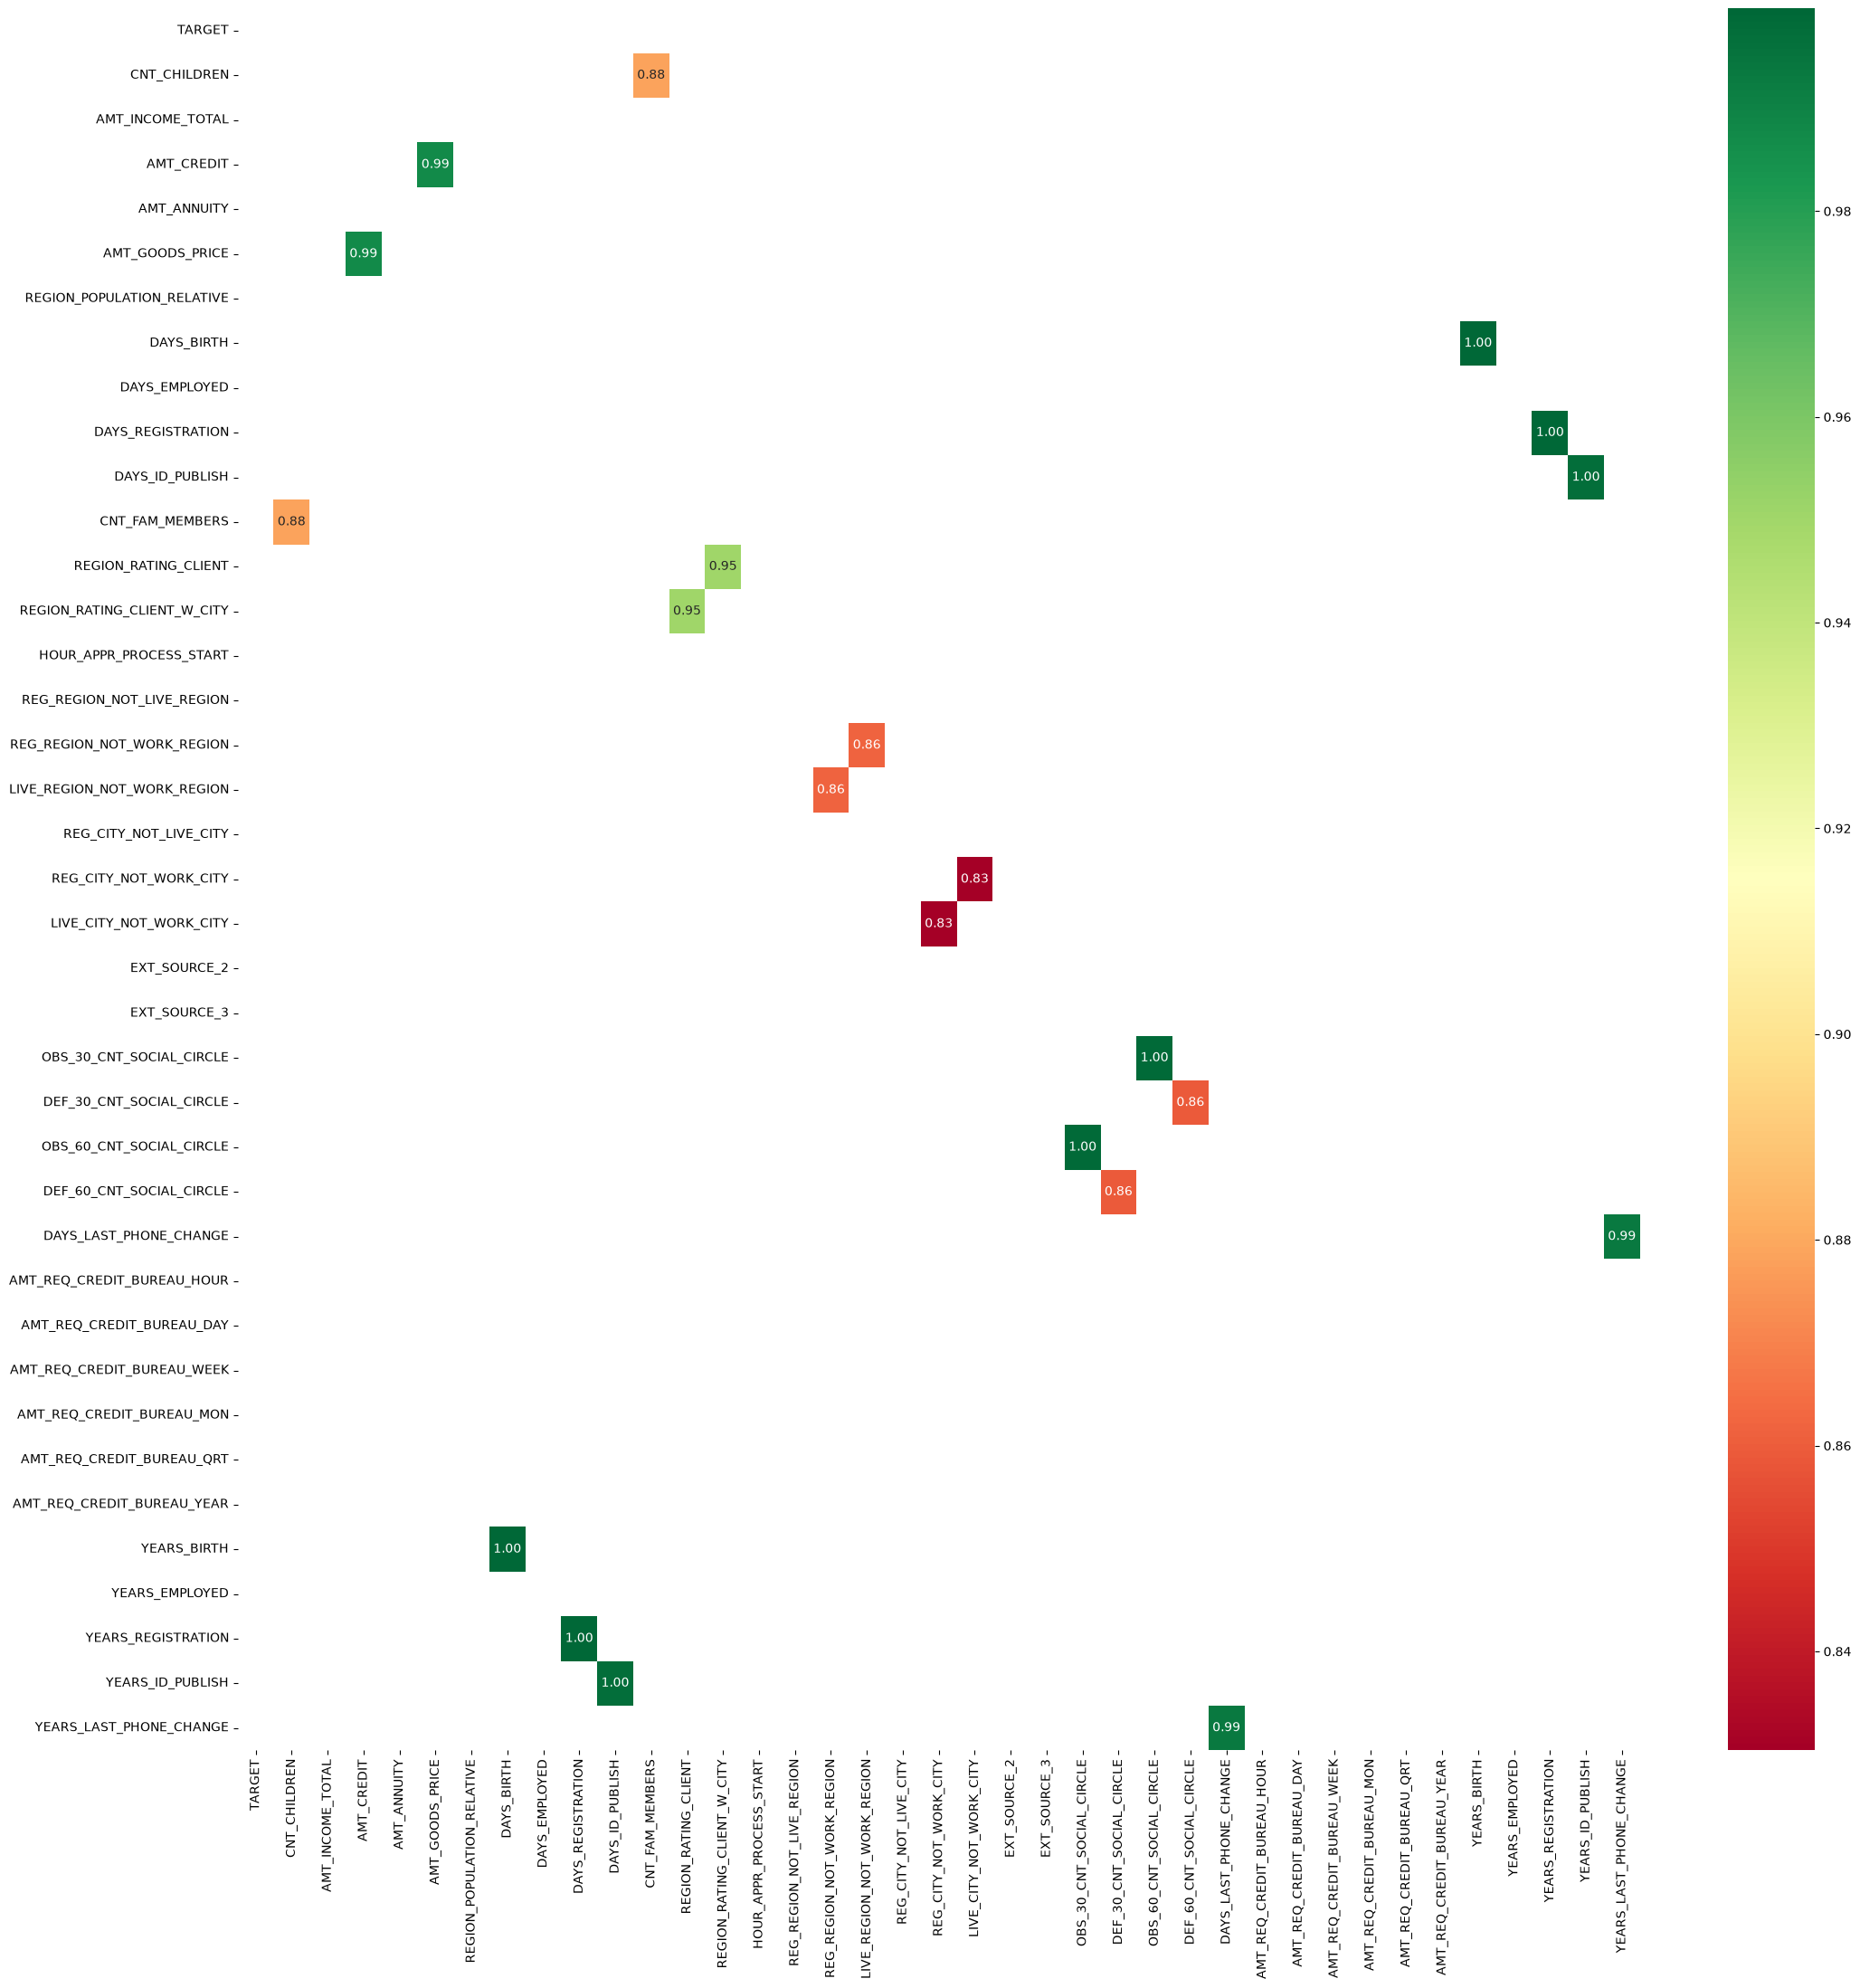

In [205]:
plt.figure(figsize = (25,25))
sns.heatmap(data = corr_df0[(corr_df0 >= 0.8) & (corr_df0 < 0.9999)], annot = True, cmap = "RdYlGn", cbar = True, fmt='.2f')
plt.show()

### Подивимось на 10 найкращих кореляцій для вчасних платежів

In [206]:
corr_df0[corr_df0 <= 0.99].unstack().sort_values(ascending = False).head(28)

AMT_CREDIT                   AMT_GOODS_PRICE               0.99
AMT_GOODS_PRICE              AMT_CREDIT                    0.99
REGION_RATING_CLIENT_W_CITY  REGION_RATING_CLIENT          0.95
REGION_RATING_CLIENT         REGION_RATING_CLIENT_W_CITY   0.95
CNT_FAM_MEMBERS              CNT_CHILDREN                  0.88
CNT_CHILDREN                 CNT_FAM_MEMBERS               0.88
LIVE_REGION_NOT_WORK_REGION  REG_REGION_NOT_WORK_REGION    0.86
REG_REGION_NOT_WORK_REGION   LIVE_REGION_NOT_WORK_REGION   0.86
DEF_60_CNT_SOCIAL_CIRCLE     DEF_30_CNT_SOCIAL_CIRCLE      0.86
DEF_30_CNT_SOCIAL_CIRCLE     DEF_60_CNT_SOCIAL_CIRCLE      0.86
LIVE_CITY_NOT_WORK_CITY      REG_CITY_NOT_WORK_CITY        0.83
REG_CITY_NOT_WORK_CITY       LIVE_CITY_NOT_WORK_CITY       0.83
AMT_ANNUITY                  AMT_GOODS_PRICE               0.78
AMT_GOODS_PRICE              AMT_ANNUITY                   0.78
AMT_CREDIT                   AMT_ANNUITY                   0.77
AMT_ANNUITY                  AMT_CREDIT 

Оскільки у нас є комбінації, що повторюються, дивлячись на наведену вище таблицю і видаляючи дублі, ми отримуємо топ-10 кореляцій, як показано нижче:

- AMT_GOODS_PRICE              AMT_CREDIT                    0.99
- REGION_RATING_CLIENT         REGION_RATING_CLIENT_W_CITY   0.95
- CNT_FAM_MEMBERS              CNT_CHILDREN                  0.88
- REG_REGION_NOT_WORK_REGION   LIVE_REGION_NOT_WORK_REGION   0.86
- DEF_30_CNT_SOCIAL_CIRCLE     DEF_60_CNT_SOCIAL_CIRCLE      0.86
- LIVE_CITY_NOT_WORK_CITY      REG_CITY_NOT_WORK_CITY        0.83
- AMT_ANNUITY                  AMT_GOODS_PRICE               0.78
- AMT_ANNUITY                  AMT_CREDIT                    0.77
- DAYS_BIRTH                   DAYS_EMPLOYED                 0.63
- DAYS_EMPLOYED                FLAG_DOCUMENT_6               0.60

### Порівняємо 10 найкращих кореляцій між випадками із платіжними труднощами та вчасними платежами

**Спостереження**

- Топ-10 кореляцій для Труднощів з оплатою та Вчасних платежів однакові, за винятком незначних відмінностей у відсотках кореляції
- Найвища кореляція для комбінації `AMT_GOODS_PRICE` та `AMT_CREDIT`.
- Для набору даних "Труднощі з оплатою" кореляція між `AMT_GOODS_PRICE` та `AMT_CREDIT` становить 0,98
- Для набору даних "Вчасні платежі" кореляція між `AMT_GOODS_PRICE` та `AMT_CREDIT` становить 0,99

# Одновимірний аналіз числових змінних

### Аналіз стовпця `AMT_CREDIT`

#### Пошук викидів в `AMT_CREDIT` при випадках із платіжними труднощами

Розрахунок IQR (Inter Quartile range)

In [207]:
Q1 = df1['AMT_CREDIT'].quantile(0.25)
Q3 = df1['AMT_CREDIT'].quantile(0.75)
IQR = Q3 - Q1
print(IQR)

448915.5


Значення *до* (Q1 - 1.5 * IQR) та *після* (Q3 + 1.5 * IQR) є викидами.

In [208]:
Min_value1 = (Q1 - 1.5 * IQR)
Max_value1 = (Q3 + 1.5 * IQR)
print("Мінімальне значення, до якого існують викиди: {}".format(Min_value1))
print("Максимальне значення, після якого існують викиди: {}".format(Max_value1))

Мінімальне значення, до якого існують викиди: -388973.25
Максимальне значення, після якого існують викиди: 1406688.75


#### Пошук викидів в `AMT_CREDIT` при випадках із вчасними оплатами

Розрахунок IQR (Inter Quartile range)

In [209]:
Q1 = df0['AMT_CREDIT'].quantile(0.25)
Q3 = df0['AMT_CREDIT'].quantile(0.75)
IQR = Q3 - Q1
print(IQR)

540000.0


Значення *до* (Q1 - 1.5 * IQR) та *після* (Q3 + 1.5 * IQR) є викидами.

In [210]:
Min_value0 = (Q1 - 1.5 * IQR)
Max_value0 = (Q3 + 1.5 * IQR)
print("Мінімальне значення, до якого існують викиди: {}".format(Min_value0))
print("Максимальне значення, після якого існують викиди: {}".format(Max_value0))

Мінімальне значення, до якого існують викиди: -540000.0
Максимальне значення, після якого існують викиди: 1620000.0


Видалення викидів і побудова діаграми розподілу

In [211]:
def kde_no_outliers(df0, df1, Max_value0, Max_value1, column):
  plt.figure(figsize = (14,6))
  sns.kdeplot(df1[df1[column] <= Max_value1][column],label = 'Payment difficulties')
  sns.kdeplot(df0[df0[column] <= Max_value0][column],label = 'On-Time Payments')
  plt.ticklabel_format(style='plain', axis='x')
  plt.xticks(rotation = 45)
  plt.legend()
  plt.show()

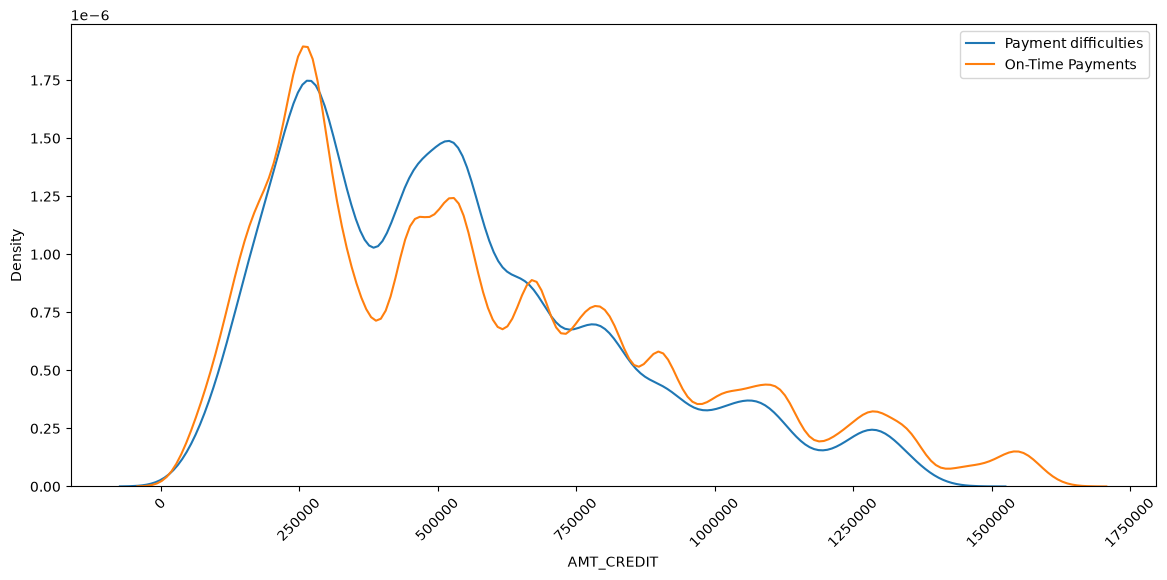

In [212]:
kde_no_outliers(df0, df1, Max_value0, Max_value1, 'AMT_CREDIT')

**Спостереження**

- Для `AMT_CREDIT` від 250000 до приблизно 650000 більше клієнтів мають труднощі з оплатою
- Для `AMT_CREDIT` > 750000 більше клієнтів, які вчасно здійснюють платежі

# ДЗ 5. Одновимірний аналіз числової колонки

За наведеним вище прикладом, проведіть одновимірний аналіз (виявлення викидів, їх усунення та побудова KDE  графіку) для числових змінних
- `YEARS_BIRTH`
- `AMT_GOODS_PRICE`
- `DAYS_EMPLOYED`

Опціонально:
- `CNT_CHILDREN`
- `AMT_INCOME_TOTAL`

Для цього винесіть функціонал для аналізу у функцію та викличіть функцію для кожної двійки змінних.

Зробіть висновки з аналізу.

Функція для одновимірного аналізу числової колонки (за прикладом аналізу `AMT_CREDIT` вище).
На відміну від прикладу:
- межі викидів за IQR рахуються в одній функції для обох груп і показуються в таблиці. Додатково межі рахуються для всіх заявників разом (рядок `All applicants`);
- для KDE обидві групи відсікаються за **спільним діапазоном** - межами IQR, порахованими на всіх заявниках разом. Якби кожну групу відсікати за її власними межами, одні й ті самі значення лишались би в одній групі й зникали з іншої, і різниця кривих у хвості була б артефактом фільтра;
- відсікаються значення і нижче нижньої, і вище верхньої межі, а на графік додані медіани груп (пунктир), щоб легше порівнювати розподіли.

In [213]:
def uni_num_target_analysis(df0, df1, column):
    """
    Одновимірний аналіз числової колонки в розрізі TARGET:
    - межі викидів за правилом IQR окремо для кожної групи та для всіх заявників разом;
    - кількість та відсоток викидів (від рядків з відомим значенням);
    - медіани без викидів двома способами: за власними межами групи (median_own_bounds)
      і у спільному діапазоні - межах IQR для всіх заявників разом (median_common_range, як на графіку);
    - KDE-графік для обох груп у спільному діапазоні з медіанами.
    Повертає межі викидів для кожної групи та спільний діапазон.
    """
    groups = {'Payment difficulties': df1, 'On-Time Payments': df0}
    all_data = pd.concat([df1, df0])
    bounds = {}
    summary = {}

    for name, data in {**groups, 'All applicants': all_data}.items():
        values = data[column].dropna()
        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)
        IQR = Q3 - Q1
        min_value = Q1 - 1.5 * IQR
        max_value = Q3 + 1.5 * IQR
        is_outlier = (values < min_value) | (values > max_value)
        bounds[name] = (min_value, max_value)

        summary[name] = {
            'count': len(values),
            'median': values.median(),
            'mean': values.mean(),
            'Q1': Q1,
            'Q3': Q3,
            'IQR': IQR,
            'min_value': min_value,
            'max_value': max_value,
            'min': values.min(),
            'max': values.max(),
            'outliers_count': is_outlier.sum(),
            'outliers_pct': is_outlier.mean() * 100,
            'median_own_bounds': values[~is_outlier].median(),
        }

    # медіана у спільному діапазоні - та сама, що показана пунктиром на KDE
    common_min, common_max = bounds['All applicants']
    for name, data in {**groups, 'All applicants': all_data}.items():
        values = data[column].dropna()
        summary[name]['median_common_range'] = values[values.between(common_min, common_max)].median()

    print(f'Межі викидів за IQR для {column}')
    # після .T усі стовпці стають float - повертаємо цілий тип лічильникам
    display(pd.DataFrame(summary).T.astype({'count': int, 'outliers_count': int}))

    # KDE у спільному діапазоні для обох груп (cut = 0 - щоб крива не виходила за межі даних)
    min_value, max_value = bounds['All applicants']
    print(f'Спільний діапазон для KDE: від {min_value:,.2f} до {max_value:,.2f}')
    plt.figure(figsize = (14,6))
    for (name, data), color in zip(groups.items(), ['tab:red', 'tab:blue']):
        values = data[column].dropna()
        in_range = (values >= min_value) & (values <= max_value)
        print(f'{name}: на графіку {in_range.sum()} з {len(values)} ({in_range.mean() * 100:.2f}%)')
        values = values[in_range]
        sns.kdeplot(values, label = name, color = color, cut = 0)
        plt.axvline(values.median(), color = color, linestyle = '--',
                    label = f'Медіана у спільному діапазоні ({name}): {values.median():,.0f}')
    plt.title(f'KDE для {column} у спільному діапазоні без викидів')
    plt.ticklabel_format(style='plain', axis='x')
    plt.xticks(rotation = 45)
    plt.legend()
    plt.show()

    return bounds

### Аналіз стовпця `YEARS_BIRTH`

Межі викидів за IQR для YEARS_BIRTH


,count,median,mean,Q1,Q3,IQR,min_value,max_value,min,max,outliers_count,outliers_pct,median_own_bounds,median_common_range
Payment difficulties,24825,39.00,40.78,31.00,49.00,18.00,4.00,76.00,21.00,69.00,0,0.00,39.00,39.00
On-Time Payments,282686,43.00,44.22,34.00,54.00,20.00,4.00,84.00,21.00,69.00,0,0.00,43.00,43.00
All applicants,307511,43.00,43.94,34.00,54.00,20.00,4.00,84.00,21.00,69.00,0,0.00,43.00,43.00


Спільний діапазон для KDE: від 4.00 до 84.00
Payment difficulties: на графіку 24825 з 24825 (100.00%)
On-Time Payments: на графіку 282686 з 282686 (100.00%)


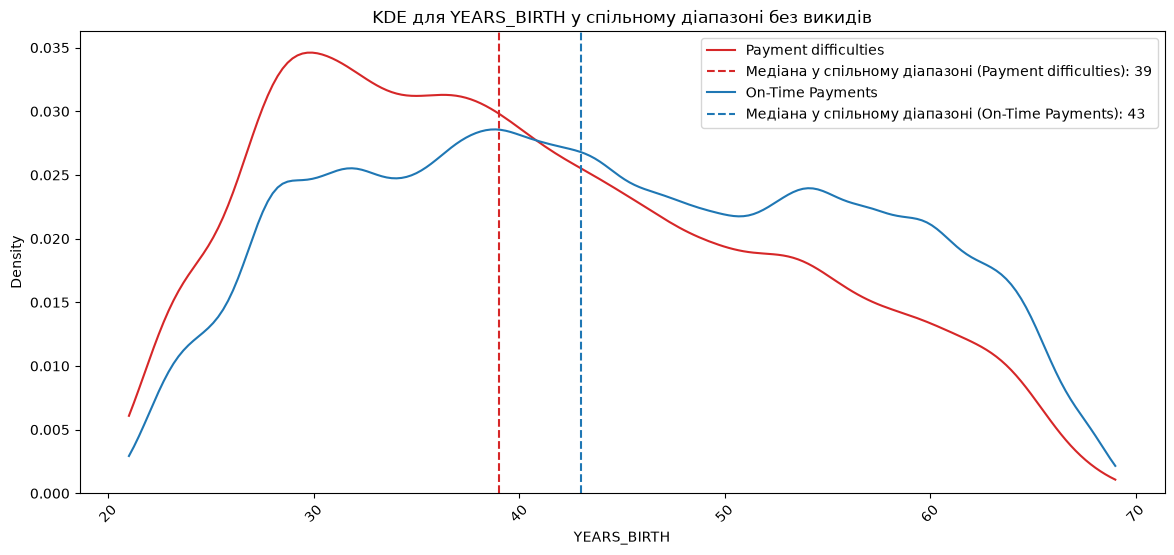

In [214]:
years_birth_bounds = uni_num_target_analysis(df0, df1, 'YEARS_BIRTH')

KDE згладжує дискретні значення: `YEARS_BIRTH` - це 49 цілих років. Тому додатково будуємо гістограму, де кожен стовпчик - один рік (`discrete = True`). `stat = 'density'` і `common_norm = False` нормують кожну групу окремо, як на KDE, тому групи різного розміру можна порівнювати

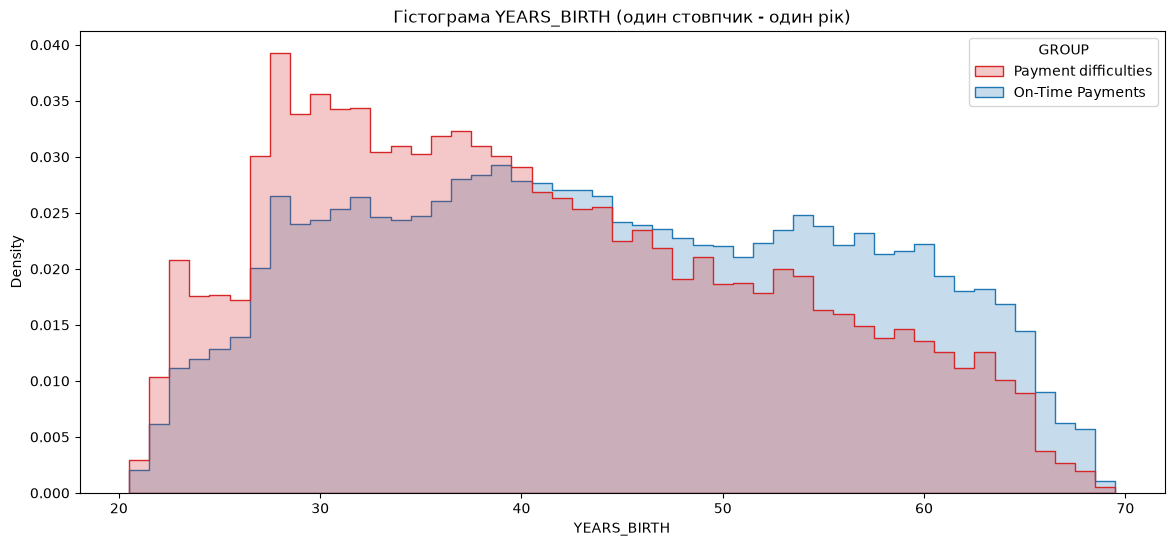

In [215]:
target_groups = df.assign(GROUP = df['TARGET'].map({1: 'Payment difficulties', 0: 'On-Time Payments'}))
group_palette = {'Payment difficulties': 'tab:red', 'On-Time Payments': 'tab:blue'}

plt.figure(figsize = (14,6))
sns.histplot(data = target_groups, x = 'YEARS_BIRTH', hue = 'GROUP', palette = group_palette,
             discrete = True, stat = 'density', common_norm = False, element = 'step')
plt.title('Гістограма YEARS_BIRTH (один стовпчик - один рік)')
plt.show()

Частка клієнтів з платіжними труднощами у відсотках (`TARGET` = 1) та кількість заявників у кожній віковій категорії (`YEARS_BIRTH_CATEGORY` створена вище функцією `age_cat`).  
Групи формуються за **округленим** віком `YEARS_BIRTH` (`round(DAYS_BIRTH / 365)`), а `age_cat` **включає праву межу**: `20-30` - це 21-30 років, `30-40` - 31-40, `40-50` - 41-50, `50-60` - 51-60, `60-70` - 61-69 (старших за 69 у даних немає). Наприклад, 50 років потрапляє в `40-50`, а не в `50-60`.  
Округлений вік - це не повні роки: `round` відрізняється від кількості повних років (`floor(DAYS_BIRTH / 365)`) приблизно у половини заявників (50.3%). Тому в реальному віці (`DAYS_BIRTH / 365`) групи - це приблизно: `20-30` ≈ 20.5-30.5 років, `30-40` ≈ 30.5-40.5, `40-50` ≈ 40.5-50.5, `50-60` ≈ 50.5-60.5, `60-70` ≈ 60.5-69.1

In [216]:
age_target = df.groupby('YEARS_BIRTH_CATEGORY')['TARGET'].agg(target_rate_pct = 'mean', count = 'count')
age_target['target_rate_pct'] = (age_target['target_rate_pct'] * 100).round(2)
age_target

,target_rate_pct,count
YEARS_BIRTH_CATEGORY,,
20-30,11.44,48869
30-40,9.43,82770
40-50,7.58,75509
50-60,6.04,67955
60-70,4.92,32408


**Спостереження**
- Пропусків немає, округлений вік в обох групах - від 21 до 69 років (реальний вік `DAYS_BIRTH / 365` - від ~20.5 до ~69.1).
- Клієнти з платіжними труднощами (`TARGET` = 1): Q1 = 31, Q3 = 49, IQR = 18, межі викидів - 4 і 76 років. Клієнти зі вчасними платежами (`TARGET` = 0): Q1 = 34, Q3 = 54, IQR = 20, межі - 4 і 84 роки.
- Усі значення лежать всередині меж, тобто **викидів немає**: прибирати нічого не потрібно, KDE побудований на всіх даних.
- Клієнти з платіжними труднощами молодші: медіана 39 років проти 43, середнє 40.8 проти 44.2. На KDE червона крива має пік близько 30 років і проходить вище за синю приблизно до 40 років, а після 40 - нижче. Гістограма по роках (без згладжування) це підтверджує: червона вища за синю для кожного року від 21 до 40 включно, а її пік - 28 років.
- Частка клієнтів з платіжними труднощами послідовно зменшується з віком (в дужках - округлений вік): 11.44% (`20-30`, 21-30 років) → 9.43% (`30-40`, 31-40) → 7.58% (`40-50`, 41-50) → 6.04% (`50-60`, 51-60) → 4.92% (`60-70`, 61-69). У наймолодшій групі вона приблизно в 2.3 раза вища, ніж у найстаршій.

**Висновок**
- У `YEARS_BIRTH` викидів немає.
- Вік пов'язаний з цільовою змінною: чим молодший заявник, тим вища частка платіжних труднощів. Найвища частка - **11.44% у групі `20-30`** (округлений вік 21-30, реально ≈20.5-30.5 років), найнижча - **4.92% у групі `60-70`** (округлений вік 61-69, реально ≈60.5-69.1).
- Вище за середню по всіх заявниках (8.07%) частка лише у групах `20-30` і `30-40` (округлений вік до 40 включно, тобто реально до ≈40.5 років). Починаючи з групи `40-50` (округлений вік 41-50) вона нижча за середню і далі продовжує зменшуватись: у групі `50-60` - 6.04%, у групі `60-70` - 4.92%.

### Аналіз стовпця `AMT_GOODS_PRICE`

Нагадування: у ДЗ 2 278 пропусків (усі - `Revolving loans`) заповнені значенням `AMT_CREDIT`, тому пропусків у колонці немає

Межі викидів за IQR для AMT_GOODS_PRICE


,count,median,mean,Q1,Q3,IQR,min_value,max_value,min,max,outliers_count,outliers_pct,median_own_bounds,median_common_range
Payment difficulties,24825,450000.00,488769.96,238500.00,675000.00,436500.00,-416250.00,1329750.00,45000.00,3600000.00,612,2.47,450000.00,450000.00
On-Time Payments,282686,450000.00,542499.82,238500.00,688500.00,450000.00,-436500.00,1363500.00,40500.00,4050000.00,7947,2.81,450000.00,450000.00
All applicants,307511,450000.00,538162.28,238500.00,679500.00,441000.00,-423000.00,1341000.00,40500.00,4050000.00,14731,4.79,450000.00,450000.00


Спільний діапазон для KDE: від -423,000.00 до 1,341,000.00
Payment difficulties: на графіку 24223 з 24825 (97.58%)
On-Time Payments: на графіку 268557 з 282686 (95.00%)


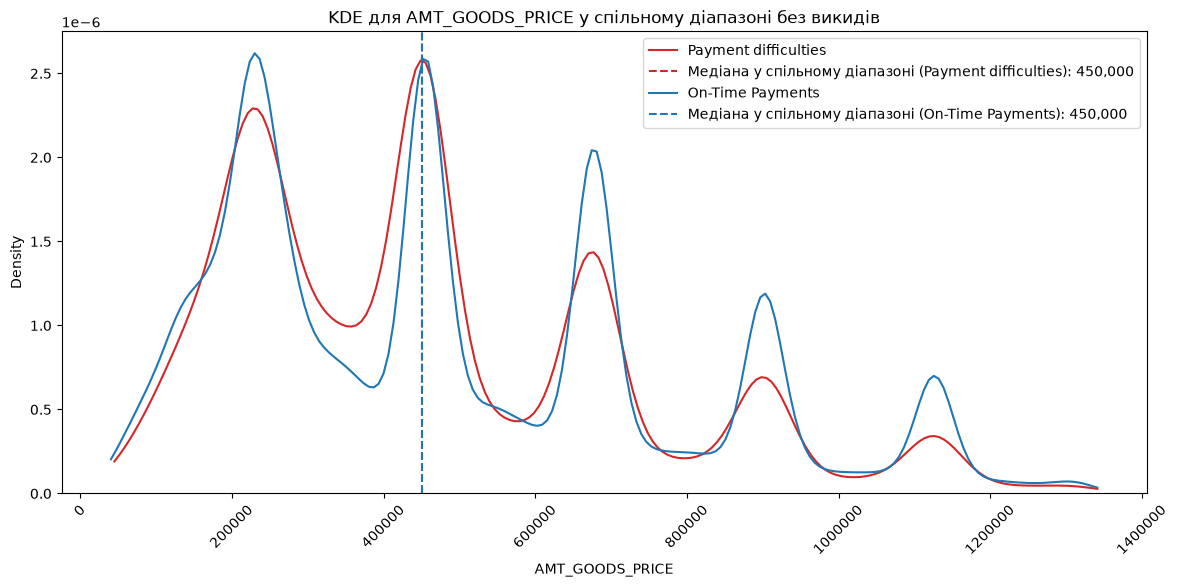

In [217]:
goods_price_bounds = uni_num_target_analysis(df0, df1, 'AMT_GOODS_PRICE')

KDE згладжує піки на "круглих" цінах. Тому додатково будуємо гістограму в тому самому спільному діапазоні (до `goods_price_bounds['All applicants']`) зі стовпчиками шириною 22 500, центрованими на кратних 22 500 значеннях, щоб кожна "кругла" ціна була в центрі свого стовпчика. Нижче - частка платіжних труднощів для п'яти найчастіших значень ціни

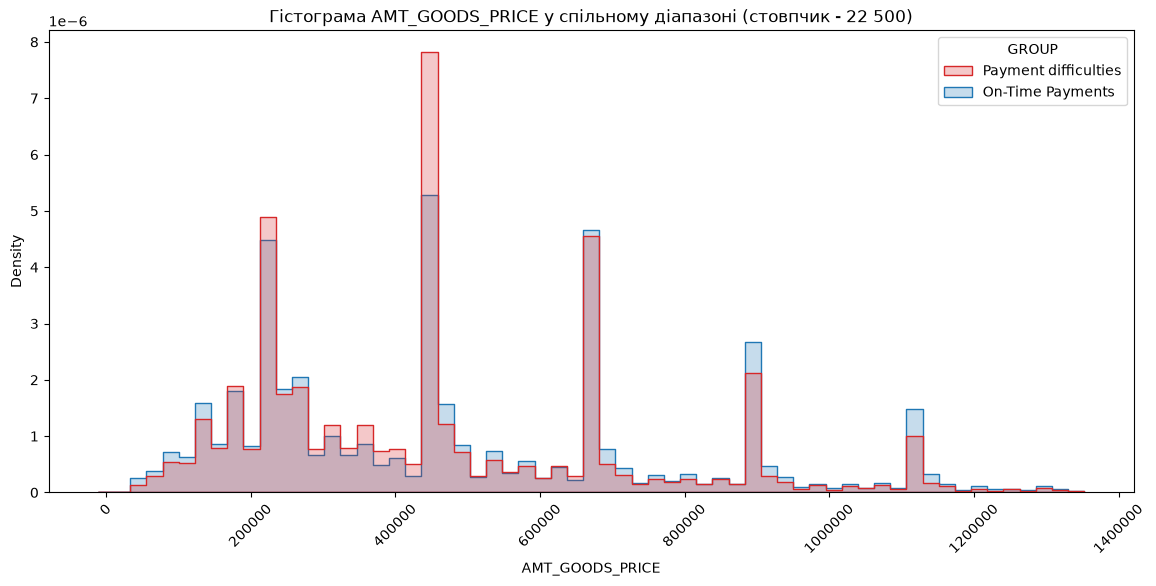

,target_rate_pct,count
AMT_GOODS_PRICE,,
225000.00,9.07,25294
270000.00,7.26,11479
450000.00,13.74,26029
675000.00,8.83,24969
900000.00,6.80,15417


Інтервал 373 500 - 522 000: частка TARGET = 1 - 10.37% (61549 заявок), без значення 450 000 - 7.91% (35520 заявок)


In [218]:
goods_hist = target_groups[target_groups['AMT_GOODS_PRICE'] <= goods_price_bounds['All applicants'][1]]

plt.figure(figsize = (14,6))
sns.histplot(data = goods_hist, x = 'AMT_GOODS_PRICE', hue = 'GROUP', palette = group_palette,
             binwidth = 22500, binrange = (-11250, goods_price_bounds['All applicants'][1] + 11250),
             stat = 'density', common_norm = False, element = 'step')
plt.title('Гістограма AMT_GOODS_PRICE у спільному діапазоні (стовпчик - 22 500)')
plt.ticklabel_format(style='plain', axis='x')
plt.xticks(rotation = 45)
plt.show()

top_prices = df['AMT_GOODS_PRICE'].value_counts().head(5).index
top_prices_target = df[df['AMT_GOODS_PRICE'].isin(top_prices)].groupby('AMT_GOODS_PRICE')['TARGET'].agg(
    target_rate_pct = 'mean', count = 'count')
top_prices_target['target_rate_pct'] = (top_prices_target['target_rate_pct'] * 100).round(2)
display(top_prices_target)

middle_bin = (df['AMT_GOODS_PRICE'] > 373500) & (df['AMT_GOODS_PRICE'] <= 522000)
middle_without_450k = middle_bin & (df['AMT_GOODS_PRICE'] != 450000)
print(f"Інтервал 373 500 - 522 000: частка TARGET = 1 - {df.loc[middle_bin, 'TARGET'].mean() * 100:.2f}% "
      f"({middle_bin.sum()} заявок), без значення 450 000 - {df.loc[middle_without_450k, 'TARGET'].mean() * 100:.2f}% "
      f"({middle_without_450k.sum()} заявок)")

Частка клієнтів з платіжними труднощами у відсотках (`TARGET` = 1) за інтервалами ціни товару. Беремо 5 квантильних інтервалів (`pd.qcut`), а не `AMT_GOODS_PRICE_CATEGORY` (5 інтервалів однакової ширини), бо там майже всі заявники потрапляють у `very low` / `low`.  
Інтервали вийдуть **нерівними за кількістю заявок** (не квінтилі в строгому сенсі): у колонці багато повторюваних "круглих" цін (наприклад, 225 000 - 25 294 заявки), а однакові значення `pd.qcut` не може розділити між сусідніми інтервалами

In [219]:
goods_price_bins = pd.qcut(df['AMT_GOODS_PRICE'], q = 5, duplicates = 'drop')
goods_target = df.groupby(goods_price_bins, observed = True)['TARGET'].agg(target_rate_pct = 'mean', count = 'count')
goods_target['target_rate_pct'] = (goods_target['target_rate_pct'] * 100).round(2)
goods_target

,target_rate_pct,count
AMT_GOODS_PRICE,,
"(40499.999, 225000.0]",8.01,71603
"(225000.0, 373500.0]",8.80,51558
"(373500.0, 522000.0]",10.37,61549
"(522000.0, 814500.0]",7.58,61364
"(814500.0, 4050000.0]",5.73,61437


Перевірка хвоста: чи узгоджуються дорогі товари (вище спільної межі IQR `goods_price_bounds['All applicants']`) з сумою кредиту та доходом. Порівнюємо викиди (`True`) з рештою заявників (`False`): медіани, відношення суми кредиту до ціни товару та частку записів, де кредит відрізняється від ціни товару строго більш ніж на 50% (`CREDIT_GOODS_MISMATCH`)

In [220]:
goods_max = goods_price_bounds['All applicants'][1]
goods_tail = df.assign(
    IS_OUTLIER = df['AMT_GOODS_PRICE'] > goods_max,
    CREDIT_TO_GOODS = df['AMT_CREDIT'] / df['AMT_GOODS_PRICE']
)
goods_tail['CREDIT_GOODS_MISMATCH'] = (goods_tail['CREDIT_TO_GOODS'] - 1).abs() > 0.5

goods_tail.groupby('IS_OUTLIER').agg(
    count = ('AMT_GOODS_PRICE', 'count'),
    goods_price_median = ('AMT_GOODS_PRICE', 'median'),
    credit_median = ('AMT_CREDIT', 'median'),
    income_median = ('AMT_INCOME_TOTAL', 'median'),
    credit_to_goods_min = ('CREDIT_TO_GOODS', 'min'),
    credit_to_goods_median = ('CREDIT_TO_GOODS', 'median'),
    credit_to_goods_max = ('CREDIT_TO_GOODS', 'max'),
    mismatch_pct = ('CREDIT_GOODS_MISMATCH', lambda s: s.mean() * 100)
)

,count,goods_price_median,credit_median,income_median,credit_to_goods_min,credit_to_goods_median,credit_to_goods_max,mismatch_pct
IS_OUTLIER,,,,,,,,
False,292780,450000.00,495000.00,135000.00,0.15,1.12,6.00,0.89
True,14731,1431000.00,1575000.00,225000.00,0.50,1.09,1.28,0.00


**Спостереження**
- Пропусків немає (заповнені в ДЗ 2). Значення "круглі", тому KDE має кілька окремих піків: 225 000, 450 000, 675 000, 900 000, 1 125 000. Ще одне часте значення у вихідних даних - 1 350 000 (5 040 заявок), але воно вище спільної межі 1 341 000, тому на KDE не потрапляє.
- Нижня межа викидів від'ємна в обох групах, тому викидів знизу немає. Верхня межа - **1 329 750** для `TARGET` = 1 і **1 363 500** для `TARGET` = 0.
- Викидів 612 (2.47%) серед клієнтів з платіжними труднощами та 7 947 (2.81%) серед клієнтів зі вчасними платежами. Максимум - 3 600 000 і 4 050 000 відповідно.
- Для всіх заявників разом верхня межа - **1 341 000**, викидів 14 731 (4.79%) - помітно більше, ніж у групах окремо. Головна причина - "кругле" значення 1 350 000 (5 040 заявок): воно лежить між спільною межею і межею для `TARGET` = 0. Разом із сусідніми "круглими" значеннями близько 1.35 млн воно робить відсоток викидів дуже чутливим до точного положення межі.
- Медіана в обох групах однакова - 450 000 (і з викидами, і без них, тому на графіку пунктирні лінії збігаються). Але середнє в групі з труднощами нижче (488 770 проти 542 500): у клієнтів зі вчасними платежами довший хвіст дорогих товарів.
- KDE побудований у спільному діапазоні (до 1 341 000) для обох груп: на графіку 97.58% клієнтів з платіжними труднощами і 95.00% клієнтів зі вчасними платежами. Значення 1 350 000 відсікається в обох групах однаково.
- На KDE червона крива вища в діапазоні ~300 000 - 450 000, а синя - на піках 675 000 і вище. Але KDE згладжує "круглі" значення, і на ньому здається, що на піку 450 000 криві майже збігаються. Гістограма показує інше: на самому значенні 450 000 стовпчик клієнтів з платіжними труднощами помітно вищий, на 225 000 - трохи вищий, а на 900 000 і 1 125 000 - нижчий; на 675 000 стовпчики майже однакові.
- За таблицею найчастіших цін частка платіжних труднощів при ціні рівно **450 000 - 13.74%** (26 029 заявок), тобто в 1.7 раза вища за середню 8.07%. Для інших "круглих" цін вона близька до середньої або нижча: 225 000 - 9.07%, 675 000 - 8.83%, 270 000 - 7.26%, 900 000 - 6.80%.
- Перевірка хвоста (14 731 запис вище спільної межі 1 341 000): медіана ціни товару 1 431 000, суми кредиту - 1 575 000, доходу - 225 000 (проти 450 000, 495 000 і 135 000 у решти). Відношення суми кредиту до ціни товару у викидах лежить у межах 0.50 - 1.28 (медіана 1.09). Максимальне розходження - рівно 50%: це 2 записи з кредитом 675 000 при ціні товару 1 350 000 (відношення 0.50). Записів, де розходження строго більше 50%, немає (`CREDIT_GOODS_MISMATCH` = 0). У решти заявників цей діапазон навіть ширший (0.15 - 6.00). Застереження: 278 пропусків ціни заповнені в ДЗ 2 значенням `AMT_CREDIT`, тому в цих записах відношення дорівнює 1 за побудовою. Але у хвіст потрапили лише 3 з них (решта 275 - серед інших заявників), і без них медіани, мінімуми та максимуми в обох групах не змінюються.
- Частка клієнтів з платіжними труднощами за квантильними інтервалами ціни: 8.01% (до 225 000), 8.80% (225 000 - 373 500), **10.37%** (373 500 - 522 000; без значення 450 000 у цьому інтервалі - лише 7.91%), 7.58% (522 000 - 814 500), **5.73%** (понад 814 500). Інтервали нерівні за розміром - від 51 558 (225 000 - 373 500) до 71 603 заявок (до 225 000) замість ~61 500, бо "круглі" ціни не діляться між інтервалами. Тому це порівняння часток у групах різного розміру, але кожна група достатньо велика (понад 50 тис. заявок), щоб частки були стабільними.

**Висновок**
- Викиди в `AMT_GOODS_PRICE` за правилом IQR залежать від того, які межі брати:
  - **за груповими межами** (1 329 750 для `TARGET` = 1 і 1 363 500 для `TARGET` = 0) - 8 559 заявок (~2.8%);
  - **за спільною межею 1 341 000**, яка використовується для KDE, - 14 731 заявка (4.79%). Різниця 6 172 заявки складається з 6 182 записів з `TARGET` = 0 між спільною межею 1 341 000 і груповою межею 1 363 500 мінус 10 записів з `TARGET` = 1 між груповою межею 1 329 750 і спільною 1 341 000. **≈78% різниці** дає значення 1 350 000 (4 818 записів з `TARGET` = 0), решту - сусідні "круглі" значення близько 1.35 млн: 1 354 500 (815), 1 345 500 (279), 1 363 500 (222), 1 359 000 (48).
- Ці значення **правдоподібні**: у кожному записі хвоста ціна товару узгоджується з сумою кредиту (відношення 0.50 - 1.28), а дохід таких заявників вищий за середній. Явних ознак помилок не видно, але повністю підтвердити коректність значень за цими даними не можна.
- Тому викиди ми **виключили тільки з KDE**, а з датафрейму не видаляли.
- Зв'язок з цільовою змінною не лінійний. Найвища частка платіжних труднощів - не для середніх цін загалом, а для конкретного значення **450 000** (13.74%): саме воно підіймає інтервал 373 500 - 522 000 до 10.37%, без нього там 7.91%. Найнижча частка - для дорогих товарів (понад 814 500). KDE цей ефект приховує, його видно лише на гістограмі та в таблиці за конкретними значеннями. Це узгоджується з висновком для `AMT_CREDIT` вище.

### Аналіз стовпця `DAYS_EMPLOYED`

Нагадування: вище `DAYS_EMPLOYED` переведені в додатні дні, а значення **365243** (~1000 років) - це не реальний стаж, а позначка для заявників без поточної роботи (практично всі - `Pensioner`: 55 352 з 55 374, або 99.96%, решта 22 - `Unemployed`). Спочатку подивимось, як часто воно зустрічається в кожній групі `TARGET`

In [221]:
EMPLOYED_ANOMALY = 365243

employed_anomaly = df.groupby(df['DAYS_EMPLOYED'] == EMPLOYED_ANOMALY)['TARGET'].agg(target_rate_pct = 'mean', count = 'count')
employed_anomaly['target_rate_pct'] = (employed_anomaly['target_rate_pct'] * 100).round(2)
employed_anomaly.index.name = f'DAYS_EMPLOYED == {EMPLOYED_ANOMALY}'
employed_anomaly

,target_rate_pct,count
DAYS_EMPLOYED == 365243,,
False,8.66,252137
True,5.40,55374


Якщо рахувати IQR разом із 365243, ці 18% записів зсувають квартилі і самі потрапляють у викиди, хоча це окрема група, а не помилка в даних. Тому аналіз викидів проводимо тільки для заявників з реальним стажем (без 365243)

Межі викидів за IQR для DAYS_EMPLOYED


,count,median,mean,Q1,Q3,IQR,min_value,max_value,min,max,outliers_count,outliers_pct,median_own_bounds,median_common_range
Payment difficulties,21835,1230.00,1814.92,594.00,2380.50,1786.50,-2085.75,5060.25,0.00,16069.00,1338,6.13,1142.00,1184.00
On-Time Payments,230302,1691.00,2438.14,789.00,3254.00,2465.00,-2908.50,6951.50,0.00,17912.00,13723,5.96,1570.00,1564.00
All applicants,252137,1648.00,2384.17,767.00,3175.00,2408.00,-2845.00,6787.00,0.00,17912.00,15149,6.01,1525.00,1525.00


Спільний діапазон для KDE: від -2,845.00 до 6,787.00
Payment difficulties: на графіку 21195 з 21835 (97.07%)
On-Time Payments: на графіку 215793 з 230302 (93.70%)


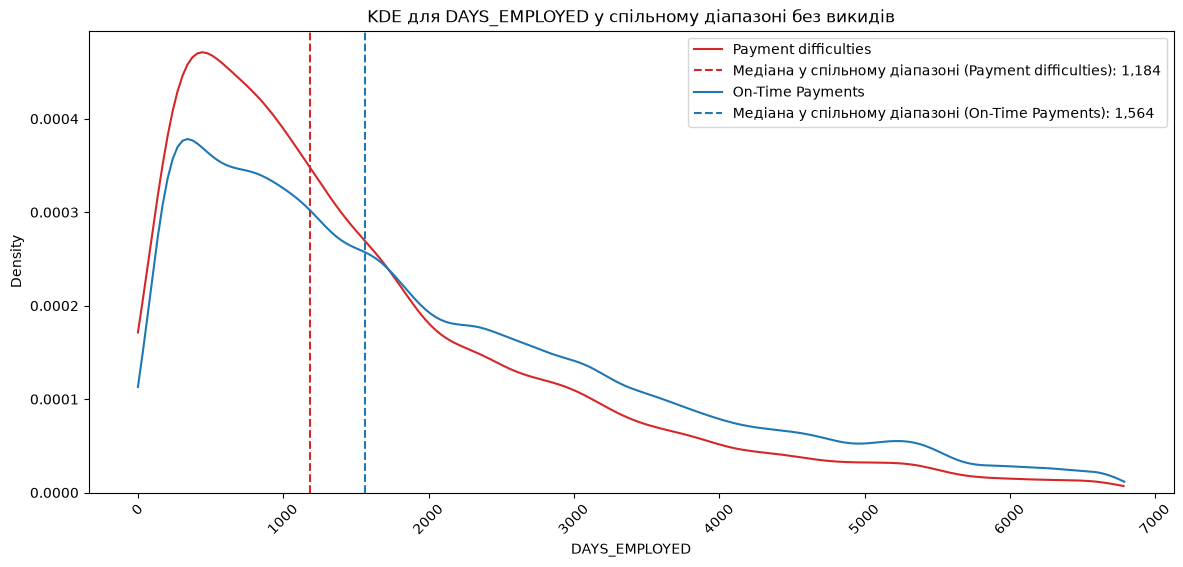

In [222]:
df0_employed = df0[df0['DAYS_EMPLOYED'] != EMPLOYED_ANOMALY]
df1_employed = df1[df1['DAYS_EMPLOYED'] != EMPLOYED_ANOMALY]

days_employed_bounds = uni_num_target_analysis(df0_employed, df1_employed, 'DAYS_EMPLOYED')

Частка клієнтів з платіжними труднощами у відсотках (`TARGET` = 1) за стажем у роках (заявники з позначкою 365243 не враховуються).  
Межі інтервалів задаємо в днях (1 рік = 365 днів), а не через `YEARS_EMPLOYED`: ця колонка округлена через `round`, тому, наприклад, стаж 1.4 року потрапив би в інтервал `0-1`. Інтервали включають праву межу: `0-1` - від 0 до 365 днів включно, `1-3` - від 366 до 1 095 днів і т.д.

In [223]:
employed_df = df[df['DAYS_EMPLOYED'] != EMPLOYED_ANOMALY]
employed_bins = pd.cut(employed_df['DAYS_EMPLOYED'], bins = [years * 365 for years in [0, 1, 3, 5, 10, 20, 50]],
                       labels = ['0-1', '1-3', '3-5', '5-10', '10-20', '20+'], include_lowest = True)
employed_target = employed_df.groupby(employed_bins, observed = True)['TARGET'].agg(target_rate_pct = 'mean', count = 'count')
employed_target['target_rate_pct'] = (employed_target['target_rate_pct'] * 100).round(2)
employed_target

,target_rate_pct,count
DAYS_EMPLOYED,,
0-1,10.97,27982
1-3,11.07,61472
3-5,9.67,46857
5-10,7.37,64872
10-20,5.51,38398
20+,4.19,12556


**Спостереження**
- Позначку **365243** мають 55 374 заявники (18.0%). Серед клієнтів з платіжними труднощами таких 12.0% (2 990 з 24 825), а серед клієнтів зі вчасними платежами - 18.5% (52 384 з 282 686). Частка платіжних труднощів у цій групі - **5.40%** проти 8.66% у заявників з реальним стажем.
- Для заявників з реальним стажем: `TARGET` = 1 - Q1 = 594, Q3 = 2 380.5, IQR = 1 786.5; `TARGET` = 0 - Q1 = 789, Q3 = 3 254, IQR = 2 465.
- Нижні межі від'ємні, тому викидів знизу немає. Верхня межа - **5 060 днів (~13.9 року)** для `TARGET` = 1 і **6 951.5 дня (~19 років)** для `TARGET` = 0.
- Викидів 1 338 (6.13%) і 13 723 (5.96%). Максимальний стаж - 16 069 і 17 912 днів (~44 і ~49 років). Такий стаж можливий за довге трудове життя, тобто це не помилки, а довгий правий хвіст розподілу.
- Клієнти з платіжними труднощами мають менший стаж: медіана 1 230 днів (~3.4 року) проти 1 691 (~4.6 року), без викидів за власними межами групи (`median_own_bounds`) - 1 142 проти 1 570. На KDE червона крива вища приблизно до 1 800 днів (~5 років), далі - нижча.
- KDE побудований у спільному діапазоні для обох груп - до **6 787 днів (~18.6 року)**, межі IQR для всіх заявників з реальним стажем разом. На графіку 97.07% клієнтів з платіжними труднощами і 93.70% клієнтів зі вчасними платежами; медіани в цьому діапазоні (`median_common_range`, пунктир на графіку) - 1 184 і 1 564 дні. Нижча частка в другій групі означає, що довгий стаж частіше трапляється у клієнтів зі вчасними платежами.
- Частка клієнтів з платіжними труднощами за стажем: 10.97% (0-1 рік) → 11.07% (1-3) → 9.67% (3-5) → 7.37% (5-10) → 5.51% (10-20) → 4.19% (20+). Для перших 3 років вона майже однакова (~11%), а далі зменшується.

**Висновок**
- 365243 - це не викид, який треба видалити, а окрема група заявників без поточної роботи (практично всі - пенсіонери, плюс 22 безробітних) з нижчою часткою платіжних труднощів. Тому для аналізу викидів її варто відокремлювати. Для моделі краще позначити її окремою колонкою-прапорцем, ніж просто видаляти.
- Викидами за правилом IQR серед заявників з реальним стажем є стаж понад **~14 - 19 років** (~6% заявників). Це реальні значення, тому для KDE ми їх відсікли, а з даних видаляти не варто.
- Стаж пов'язаний з цільовою змінною: чим менший стаж, тим вища частка платіжних труднощів. Найбільший ризик (~11%) - у заявників, які працюють на поточному місці до 3 років; при стажі понад 20 років частка падає до 4.19%.

### Чому IQR позначає правий хвіст у `AMT_GOODS_PRICE` і `DAYS_EMPLOYED`

Правило IQR симетричне: воно відкладає однакову відстань 1.5 × IQR вниз від Q1 і вгору від Q3. Для симетричних розподілів це працює добре, але в `AMT_GOODS_PRICE` і `DAYS_EMPLOYED` довгий правий хвіст. Тому нижня межа стає від'ємною, а верхня відсікає звичайні великі значення.

Перевіримо, скільки викидів залишиться, якщо рахувати IQR на логарифмі значень (`log1p`, бо є нульовий стаж). Межі переводимо назад в одиниці колонки. Беремо всіх заявників разом, для `DAYS_EMPLOYED` - без позначки 365243

In [224]:
def iqr_bounds(values):
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1
    return Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

log_check = {}
for column, data in [('AMT_GOODS_PRICE', df), ('DAYS_EMPLOYED', employed_df)]:
    values = data[column].dropna()
    for scale, transformed in [('original', values), ('log1p', np.log1p(values))]:
        min_value, max_value = iqr_bounds(transformed)
        outliers_low = (transformed < min_value).sum()
        outliers_high = (transformed > max_value).sum()
        if scale == 'log1p':
            min_value, max_value = np.expm1(min_value), np.expm1(max_value)
        log_check[(column, scale)] = {
            'skew': transformed.skew(),
            'min_value': min_value,
            'max_value': max_value,
            'outliers_low': outliers_low,
            'outliers_high': outliers_high,
            'outliers_pct': (outliers_low + outliers_high) / len(values) * 100,
        }

pd.DataFrame.from_dict(log_check, orient = 'index')

skew  min_value  max_value  outliers_low  \
AMT_GOODS_PRICE original  1.35 -423000.00 1341000.00             0   
                log1p    -0.29   49594.28 3267682.19          1327   
DAYS_EMPLOYED   original  1.97   -2845.00    6787.00             0   
                log1p    -0.44      90.32   26708.11           903   

                          outliers_high  outliers_pct  
AMT_GOODS_PRICE original          14731          4.79  
                log1p                18          0.44  
DAYS_EMPLOYED   original          15149          6.01  
                log1p                 0          0.36

**Спостереження**
- Обидва розподіли скошені вправо: асиметрія (`skew`) 1.35 для `AMT_GOODS_PRICE` і 1.97 для `DAYS_EMPLOYED`. Після `log1p` вони майже симетричні (-0.29 і -0.44).
- У вихідній шкалі всі викиди - зверху (14 731 і 15 149, 4.79% і 6.01%). У логарифмічній шкалі їх лише 0.44% і 0.36%, і переважно знизу: ціна товару нижче ~49 600 (1 327 заявок) і стаж менше ~90 днів (903 заявники).
- Зверху в логарифмічній шкалі викидів майже немає: 18 заявок з ціною понад ~3 268 000, а для стажу жодного (межа ~26 700 днів більша за максимум 17 912).
- Отже, "викиди" за IQR у вихідній шкалі - це наслідок форми розподілу, а не помилки в даних. Для KDE ми їх відсікли, щоб показати основну частину розподілу, але з датафрейму не видаляли

### Висновки ДЗ 5
- **`YEARS_BIRTH`** - викидів немає. Молодші заявники частіше мають платіжні труднощі: від 11.44% у групі `20-30` (округлений вік 21-30, реально ≈20.5-30.5 років) до 4.92% у групі `60-70` (округлений вік 61-69, реально ≈60.5-69.1); групи сформовані за округленим віком (`round`, а не повні роки), права межа включена.
- **`AMT_GOODS_PRICE`** - викиди: за груповими межами IQR (1 329 750 / 1 363 500) - 8 559 заявок (~2.8%), за спільною межею 1 341 000, яка використовується для KDE, - 14 731 (4.79%); ≈78% різниці дає значення 1 350 000, решту - сусідні "круглі" значення близько 1.35 млн. Це правдоподібні дорогі товари: у хвості ціна узгоджується з сумою кредиту, явних ознак помилок немає (але повністю підтвердити це за цими даними не можна). Найвищий ризик зосереджений на одному "круглому" значенні **450 000** (13.74% проти середніх 8.07%; саме воно дає 10.37% в інтервалі 373 500 - 522 000, без нього - 7.91%), найнижчий - для дорогих товарів (понад 814 500, 5.73%). KDE згладжує цей пік, його видно лише на гістограмі.
- **`DAYS_EMPLOYED`** - значення 365243 (18%) - окрема група без поточної роботи з нижчим ризиком (5.40%), її треба аналізувати окремо. Серед решти заявників викиди - стаж понад ~14 - 19 років (~6%). Менший стаж - вища частка платіжних труднощів (~11% при стажі до 3 років, 4.19% при стажі понад 20 років).
- В усіх трьох колонках викиди (там, де вони є) - це правдоподібні значення з довгого правого хвоста. Правило IQR симетричне, тому для скошених вправо `AMT_GOODS_PRICE` і `DAYS_EMPLOYED` воно позначає звичайний правий хвіст: у логарифмічній шкалі викидів лише ~0.4%, і майже всі вони знизу. Тому ми відсікали їх лише для побудови KDE, а з датафрейму не видаляли.
- Усі три змінні пов'язані з `TARGET`. Найчіткіший зв'язок - у віку та стажу (частка платіжних труднощів зменшується майже вдвічі і більше від найменших значень до найбільших), а для ціни товару зв'язок нелінійний.

# Двовимірний/Багатовимірний аналіз

## Неперервні vs неперервні змінні

### Аналіз стовпця `AMT_GOODS_PRICE` vs `AMT_CREDIT`

**Пошук викидів для ствопця `AMT_GOODS_PRICE ` для групи із платіжними труднощами**

In [225]:
max_value1_AMT_GOODS_PRICE = outlier_range(df1,'AMT_GOODS_PRICE')
max_value1_AMT_GOODS_PRICE

np.float64(1329750.0)

**Пошук викидів для ствопця `AMT_CREDIT` для групи із платіжними труднощами**

In [226]:
max_value1_AMT_CREDIT = outlier_range(df1,'AMT_CREDIT')
max_value1_AMT_CREDIT

np.float64(1406688.75)

**Пошук викидів для `AMT_GOODS_PRICE `для групи із вчасними оплатами**

In [227]:
max_value0_AMT_GOODS_PRICE = outlier_range(df0,'AMT_GOODS_PRICE')
max_value0_AMT_GOODS_PRICE

np.float64(1363500.0)

**Пошук викидів для `AMT_CREDIT `для групи із вчасними оплатами**

In [228]:
max_value0_AMT_CREDIT = outlier_range(df0,'AMT_CREDIT')
max_value0_AMT_CREDIT

np.float64(1620000.0)

Побудова діаграми розсіювання для порівняння з видаленими викидами

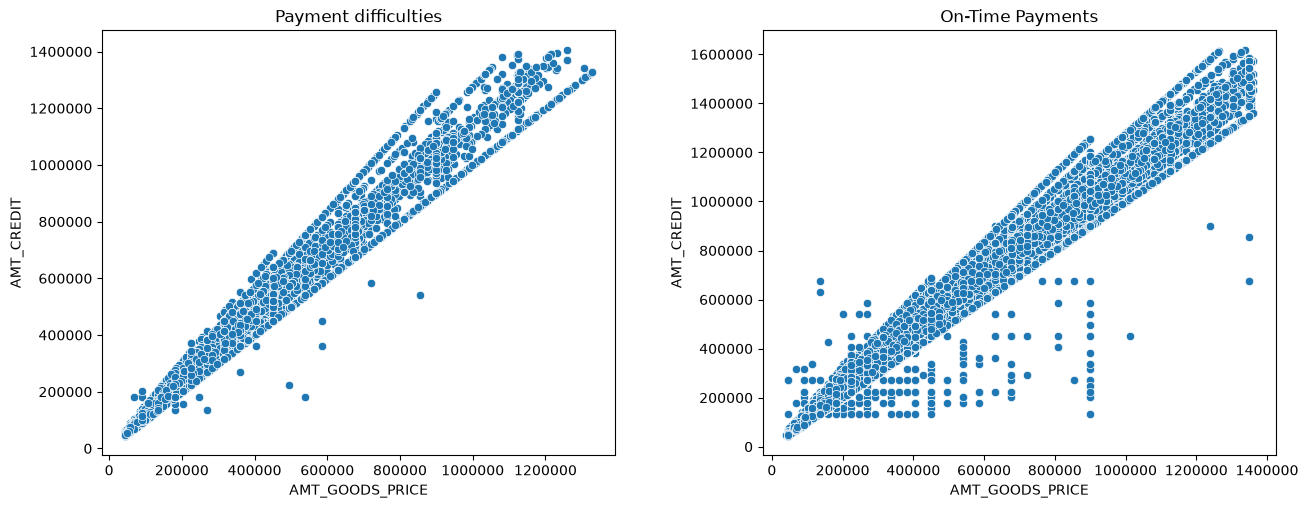

In [229]:
plt.figure(figsize = (14, 6))

plt.subplot(1,2,1)
plt.title('Payment difficulties')
sns.scatterplot(x = df1[df1['AMT_GOODS_PRICE'] < max_value1_AMT_GOODS_PRICE].AMT_GOODS_PRICE,
                y = df1[df1['AMT_CREDIT'] < max_value1_AMT_CREDIT].AMT_CREDIT, data = df1)
plt.ticklabel_format(style='plain', axis='x')
plt.ticklabel_format(style='plain', axis='y')

plt.subplot(1,2,2)
plt.title('On-Time Payments')
sns.scatterplot(x = df0[df0['AMT_GOODS_PRICE'] < max_value0_AMT_GOODS_PRICE].AMT_GOODS_PRICE,
                y = df0[df0['AMT_CREDIT'] < max_value0_AMT_CREDIT].AMT_CREDIT, data = df0)
plt.ticklabel_format(style='plain', axis='x')
plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout(pad = 4)
plt.show()

**Спостереження**
- AMT_GOODS_PRICE та AMT_CREDIT мають сильну позитивну кореляцію. Це означає, що зі збільшенням ціни товару зростає і сума кредиту

# ДЗ 6. Кореляційний аналіз для пари числових змінних

За наведеним вище прикладом, проведіть кореляційний аналіз для пар змінних
- AMT_ANNUITY і AMT_CREDIT

Опціонально:
- DAYS_EMPLOYED і AMT_INCOME_TOTAL
- AMT_CREDIT і DAYS_BIRTH

[Для цього винесіть функціонал для аналізу у функцію та викличіть функцію для кожної двійки змінних.](https://)
Зробіть висновок про наявність кореляції між змінними.

Функція для кореляційного аналізу пари числових колонок (за прикладом аналізу `AMT_GOODS_PRICE` vs `AMT_CREDIT` вище, деталі - у docstring). На відміну від прикладу:
- викиди відсікаються **однією маскою** за обома колонками: рядок прибирається, якщо хоча б одна з них вища за свою межу IQR. У прикладі `x` і `y` фільтруються окремо, а seaborn потім вирівнює їх за індексом, тож результат той самий, але неявний. Одна маска потрібна ще й для того, щоб коефіцієнти рахувались на тих самих рядках, що й на графіку;
- крім графіків, рахуються коефіцієнти **Пірсона** (лінійний зв'язок) і **Спірмена** (монотонний зв'язок) - на всіх даних, без викидів і у спільному діапазоні. Так видно, чи не створюють кореляцію самі викиди;
- графіки двох груп можна порівнювати напряму: однаковий **спільний діапазон** (межі IQR для всіх заявників разом), спільні осі та однакова кількість випадкових точок з кожної групи (у `TARGET` = 0 рядків приблизно в 11 разів більше);
- групи підписані як `TARGET = 0 (all other cases)`, а не `On-Time Payments`: за словником датасету `TARGET` = 0 - це всі інші випадки, тобто не обов'язково всі платежі вчасні.

In [230]:
def bi_num_corr_analysis(df0, df1, x, y):
    """
    Кореляційний аналіз пари числових колонок у розрізі TARGET:
    - верхні межі викидів за IQR (функція outlier_range) для кожної колонки окремо в кожній групі
      та для всіх заявників разом;
    - рядок вважається викидом, якщо хоча б одна з двох колонок вища за свою межу;
    - коефіцієнти кореляції Пірсона (лінійний зв'язок) і Спірмена (монотонний зв'язок)
      на всіх даних, без викидів за межами своєї групи і у спільному діапазоні
      (за межами для всіх заявників разом, як на графіках);
    - діаграми розсіювання для обох груп у спільному діапазоні, зі спільними осями
      і з однаковою кількістю випадкових точок з кожної групи, щоб групи можна було порівнювати.
    Рядки з пропусками в x або y не враховуються; якщо в групі не залишилось жодної повної пари,
    її рядок у таблиці містить count = 0, а межі, outliers_pct і коефіцієнти - NaN.
    Таблиця виводиться всередині функції і повертається для подальших розрахунків, тому результат
    варто присвоювати змінній (інакше в останньому рядку клітинки таблиця виведеться двічі).
    """
    # назви груп - як у словнику датасету: TARGET = 0 - це всі інші випадки, а не обов'язково вчасні платежі
    groups = {'TARGET = 1 (payment difficulties)': df1, 'TARGET = 0 (all other cases)': df0}
    # для всіх заявників разом потрібні лише дві колонки - не копіюємо весь датафрейм
    all_pairs = pd.concat([df1[[x, y]], df0[[x, y]]]).dropna()
    summary = {}
    common_range = {}

    # спільний діапазон - межі викидів, пораховані для всіх заявників разом
    common_max_x = outlier_range(all_pairs, x)
    common_max_y = outlier_range(all_pairs, y)

    for name, data in {**groups, 'All applicants': all_pairs}.items():
        data = data[[x, y]].dropna()
        if data.empty:
            # явно записуємо рядок з нулями та NaN і переходимо до наступної групи
            print(f'{name}: немає рядків з відомими {x} і {y} - межі та коефіцієнти NaN')
            common_range[name] = data
            summary[name] = {'count': 0, f'max_value_{x}': np.nan, f'max_value_{y}': np.nan,
                             'count_no_outliers': 0, 'outliers_pct': np.nan,
                             'pearson': np.nan, 'spearman': np.nan,
                             'pearson_no_outliers': np.nan, 'spearman_no_outliers': np.nan,
                             'count_common_range': 0, 'pearson_common_range': np.nan,
                             'spearman_common_range': np.nan}
            continue
        max_x = outlier_range(data, x)
        max_y = outlier_range(data, y)
        clean = data[(data[x] <= max_x) & (data[y] <= max_y)]
        in_common = data[(data[x] <= common_max_x) & (data[y] <= common_max_y)]
        common_range[name] = in_common

        summary[name] = {
            'count': len(data),
            f'max_value_{x}': max_x,
            f'max_value_{y}': max_y,
            'count_no_outliers': len(clean),
            'outliers_pct': (1 - len(clean) / len(data)) * 100,
            # Спірмен = Пірсон для рангів (method = 'spearman' потребує scipy)
            'pearson': data[x].corr(data[y]),
            'spearman': data[x].rank().corr(data[y].rank()),
            'pearson_no_outliers': clean[x].corr(clean[y]),
            'spearman_no_outliers': clean[x].rank().corr(clean[y].rank()),
            # для All applicants спільний діапазон збігається з власними межами,
            # тому *_common_range у цьому рядку дорівнюють *_no_outliers (перевірка узгодженості)
            'count_common_range': len(in_common),
            'pearson_common_range': in_common[x].corr(in_common[y]),
            'spearman_common_range': in_common[x].rank().corr(in_common[y].rank()),
        }

    result = pd.DataFrame(summary).T.astype({'count': int, 'count_no_outliers': int, 'count_common_range': int})
    print(f'Кореляція {x} і {y}')
    display(result)

    # розмір груп дуже різний (TARGET = 0 приблизно в 11 разів більше), і більша група виглядала б "щільнішою"
    # лише через кількість точок. Тому на графік з кожної групи беремо однакову випадкову вибірку
    # розміром з меншу групу; коефіцієнти в заголовках - на всіх рядках у спільному діапазоні
    plot_size = min(len(common_range[name]) for name in groups)
    print(f'Спільний діапазон для графіків: {x} <= {common_max_x:,.2f}, {y} <= {common_max_y:,.2f}')
    print(f'На кожному графіку - {plot_size:,} випадкових точок з групи (random_state = 42)')
    fig, axes = plt.subplots(1, 2, figsize = (14, 6), sharex = True, sharey = True)
    for ax, (name, color) in zip(axes, zip(groups, ['tab:red', 'tab:blue'])):
        sns.scatterplot(data = common_range[name].sample(n = plot_size, random_state = 42), x = x, y = y, color = color,
                        alpha = 0.1, s = 10, edgecolor = None, ax = ax)
        ax.set_title(f"{name}, спільний діапазон\nPearson = {summary[name]['pearson_common_range']:.2f}, "
                     f"Spearman = {summary[name]['spearman_common_range']:.2f}")
        ax.ticklabel_format(style='plain', axis='both')
        ax.tick_params(axis = 'x', rotation = 45)
    plt.tight_layout(pad = 4)
    plt.show()

    return result

### Аналіз стовпців `AMT_ANNUITY` vs `AMT_CREDIT`

Кореляція AMT_ANNUITY і AMT_CREDIT


,count,max_value_AMT_ANNUITY,max_value_AMT_CREDIT,count_no_outliers,outliers_pct,pearson,spearman,pearson_no_outliers,spearman_no_outliers,count_common_range,pearson_common_range,spearman_common_range
TARGET = 1 (payment difficulties),24825,56398.50,1406688.75,23864,3.87,0.75,0.81,0.74,0.80,24349,0.75,0.80
TARGET = 0 (all other cases),282674,62187.75,1620000.00,271996,3.78,0.77,0.83,0.77,0.82,271652,0.77,0.82
All applicants,307499,61704.00,1616625.00,296001,3.74,0.77,0.83,0.77,0.82,296001,0.77,0.82


Спільний діапазон для графіків: AMT_ANNUITY <= 61,704.00, AMT_CREDIT <= 1,616,625.00
На кожному графіку - 24,349 випадкових точок з групи (random_state = 42)


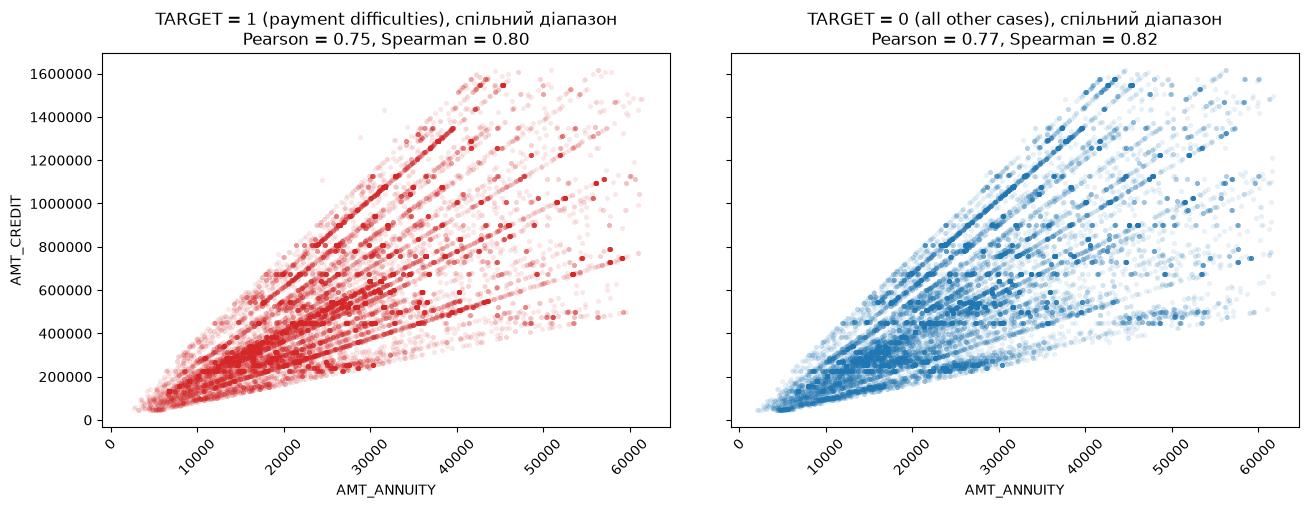

In [231]:
annuity_credit_corr = bi_num_corr_analysis(df0, df1, 'AMT_ANNUITY', 'AMT_CREDIT')

Чому Спірмен вищий за Пірсона? Порівняємо обидва коефіцієнти з Пірсоном для логарифмів `AMT_ANNUITY` і `AMT_CREDIT` (усі значення додатні, тому логарифм визначений). Логарифм стискає довгий правий хвіст і вирівнює розкид, що зростає з сумою, але не змінює форму зв'язку на кожному промені

In [232]:
# Пірсон для логарифмів обох колонок: якщо він вищий за звичайний Пірсон і за Спірмена,
# то різниця Пірсон / Спірмен пояснюється розкидом, що зростає з сумою, і довгим правим хвостом,
# а не нелінійністю зв'язку
log_corr = {}
for name, data in {'TARGET = 1 (payment difficulties)': df1, 'TARGET = 0 (all other cases)': df0,
                   'All applicants': df}.items():
    pairs = data[['AMT_ANNUITY', 'AMT_CREDIT']].dropna()
    log_corr[name] = {
        'pearson': pairs['AMT_ANNUITY'].corr(pairs['AMT_CREDIT']),
        'spearman': pairs['AMT_ANNUITY'].rank().corr(pairs['AMT_CREDIT'].rank()),
        'pearson_log': np.log(pairs['AMT_ANNUITY']).corr(np.log(pairs['AMT_CREDIT'])),
    }
pd.DataFrame(log_corr).T

,pearson,spearman,pearson_log
TARGET = 1 (payment difficulties),0.75,0.81,0.83
TARGET = 0 (all other cases),0.77,0.83,0.85
All applicants,0.77,0.83,0.84


Чи суттєва різниця коефіцієнтів Пірсона між групами (0.75 і 0.77)? Перевіримо її статистичну значущість за допомогою z-перетворення Фішера і порівняємо частку поясненої дисперсії r²

In [233]:
# Чи значуща різниця коефіцієнтів Пірсона між групами TARGET? z-перетворення Фішера:
# z = arctanh(r), стандартна похибка різниці - sqrt(1 / (n1 - 3) + 1 / (n0 - 3))
import math

r1, n1 = annuity_credit_corr.loc['TARGET = 1 (payment difficulties)', ['pearson', 'count']]
r0, n0 = annuity_credit_corr.loc['TARGET = 0 (all other cases)', ['pearson', 'count']]
z_stat = (np.arctanh(r0) - np.arctanh(r1)) / math.sqrt(1 / (n1 - 3) + 1 / (n0 - 3))
p_value = math.erfc(abs(z_stat) / math.sqrt(2))  # двосторонній p-value

print(f'Pearson: TARGET = 1 - {r1:.4f} (n = {n1:,.0f}), TARGET = 0 - {r0:.4f} (n = {n0:,.0f})')
print(f'Різниця: {r0 - r1:.4f}, z = {z_stat:.2f}, p-value = {p_value:.1e}')
print(f'Частка поясненої дисперсії r^2: {r1 ** 2:.3f} проти {r0 ** 2:.3f}')

Pearson: TARGET = 1 - 0.7522 (n = 24,825), TARGET = 0 - 0.7713 (n = 282,674)
Різниця: 0.0191, z = 6.88, p-value = 5.9e-12
Частка поясненої дисперсії r^2: 0.566 проти 0.595


На діаграмах точки лежать на окремих "променях" з початку координат: на кожному промені відношення ануїтетного платежу до суми кредиту однакове. Перевіримо, від чого воно залежить: порахуємо кореляцію та відношення `AMT_ANNUITY / AMT_CREDIT` (у відсотках) окремо для кожного типу кредиту (`NAME_CONTRACT_TYPE`) і групи `TARGET`. `pct_ratio_eq_5` - відсоток (не частка) записів, де платіж становить рівно 5% від суми кредиту

In [234]:
annuity_credit = df[['AMT_ANNUITY', 'AMT_CREDIT', 'NAME_CONTRACT_TYPE', 'TARGET']].dropna()
annuity_credit['ANNUITY_TO_CREDIT'] = annuity_credit['AMT_ANNUITY'] / annuity_credit['AMT_CREDIT']

contract_corr = {}
for (contract_type, target), data in annuity_credit.groupby(['NAME_CONTRACT_TYPE', 'TARGET']):
    ratio = data['ANNUITY_TO_CREDIT']
    contract_corr[(contract_type, target)] = {
        'count': len(data),
        'pearson': data['AMT_ANNUITY'].corr(data['AMT_CREDIT']),
        'spearman': data['AMT_ANNUITY'].rank().corr(data['AMT_CREDIT'].rank()),
        'ratio_min_pct': ratio.min() * 100,
        'ratio_median_pct': ratio.median() * 100,
        'ratio_max_pct': ratio.max() * 100,
        'pct_ratio_eq_5': np.isclose(ratio, 0.05).mean() * 100,
    }

contract_corr = pd.DataFrame(contract_corr).T.astype({'count': int})
contract_corr.index.names = ['NAME_CONTRACT_TYPE', 'TARGET']
contract_corr

count  pearson  spearman  ratio_min_pct  \
NAME_CONTRACT_TYPE TARGET                                             
Cash loans         0       254999     0.75      0.80           2.21   
                   1        23221     0.73      0.78           2.21   
Revolving loans    0        27675     0.97      1.00           5.00   
                   1         1604     1.00      1.00           5.00   

                           ratio_median_pct  ratio_max_pct  pct_ratio_eq_5  
NAME_CONTRACT_TYPE TARGET                                                   
Cash loans         0                   4.83          12.44            0.00  
                   1                   4.92          12.44            0.00  
Revolving loans    0                   5.00          10.00           99.85  
                   1                   5.00           5.00          100.00

Чому для `Revolving loans` з `TARGET` = 0 Пірсон (0.97) помітно нижчий за Спірмена (0.999986)? Порівняємо записи з платежем рівно 10% з рештою записів цієї групи (платіж 5%)

In [235]:
# Revolving loans з TARGET = 0: записи з платежем рівно 10% порівняно з рештою (платіж 5%)
revolving0 = annuity_credit[(annuity_credit['NAME_CONTRACT_TYPE'] == 'Revolving loans') & (annuity_credit['TARGET'] == 0)]
is_10pct = pd.Series(np.isclose(revolving0['ANNUITY_TO_CREDIT'], 0.10), index = revolving0.index)

display(revolving0.groupby(is_10pct.rename('ANNUITY_TO_CREDIT == 10%')).agg(
    count = ('AMT_CREDIT', 'count'),
    credit_median = ('AMT_CREDIT', 'median'),
    credit_mean = ('AMT_CREDIT', 'mean'),
    credit_max = ('AMT_CREDIT', 'max'),
    annuity_mean = ('AMT_ANNUITY', 'mean'),
))
without_10pct = revolving0[~is_10pct]
print(f"Записів з AMT_CREDIT = 2 250 000 серед платежів 10%: {(revolving0.loc[is_10pct, 'AMT_CREDIT'] == 2250000).sum()}")
print(f"Pearson з усіма записами: {revolving0['AMT_ANNUITY'].corr(revolving0['AMT_CREDIT']):.6f}, "
      f"без записів з платежем 10%: {without_10pct['AMT_ANNUITY'].corr(without_10pct['AMT_CREDIT']):.6f}")

,count,credit_median,credit_mean,credit_max,annuity_mean
ANNUITY_TO_CREDIT == 10%,,,,,
False,27634,270000.00,325969.10,2250000.00,16298.45
True,41,2250000.00,1655670.73,2250000.00,165567.07


Записів з AMT_CREDIT = 2 250 000 серед платежів 10%: 23
Pearson з усіма записами: 0.967536, без записів з платежем 10%: 1.000000


На графіку `TARGET` = 0 внизу праворуч помітний щільний кластер: кредити ~450 000 - 500 000 з платежем 40 000 - 60 000, тобто платіж ~10% суми (короткі кредити). Перевіримо для `Cash loans`, чи відрізняється відношення платежу до суми кредиту в групах `TARGET`. Це попередня однофакторна перевірка, а не повний аналіз зв'язку з `TARGET`

In [236]:
# Cash loans: відношення платежу до суми кредиту у відсотках
cash = annuity_credit[annuity_credit['NAME_CONTRACT_TYPE'] == 'Cash loans'].copy()
cash['ANNUITY_TO_CREDIT_PCT'] = cash['ANNUITY_TO_CREDIT'] * 100

print('Перцентилі ANNUITY_TO_CREDIT_PCT за групами TARGET')
display(cash.groupby('TARGET')['ANNUITY_TO_CREDIT_PCT'].quantile([0.5, 0.75, 0.9, 0.95]).unstack().round(2))

# кластер, помітний на графіку TARGET = 0 внизу праворуч
cluster = cash['AMT_CREDIT'].between(450000, 500000) & cash['AMT_ANNUITY'].between(40000, 60000)
print(f"Кластер AMT_CREDIT 450 000 - 500 000 і AMT_ANNUITY 40 000 - 60 000: {cluster.sum()} записів, "
      f"медіана відношення - {cash.loc[cluster, 'ANNUITY_TO_CREDIT_PCT'].median():.2f}%, "
      f"частка TARGET = 1 - {cash.loc[cluster, 'TARGET'].mean() * 100:.2f}% "
      f"(для всіх Cash loans - {cash['TARGET'].mean() * 100:.2f}%)")

print('Частка TARGET = 1 за інтервалами ANNUITY_TO_CREDIT_PCT')
ratio_bins = pd.cut(cash['ANNUITY_TO_CREDIT_PCT'], [0, 4, 6, 8, 10, 13])
ratio_target = cash.groupby(ratio_bins, observed = True)['TARGET'].agg(target_rate_pct = 'mean', count = 'count')
ratio_target['target_rate_pct'] = (ratio_target['target_rate_pct'] * 100).round(2)
ratio_target

Перцентилі ANNUITY_TO_CREDIT_PCT за групами TARGET


,0.50,0.75,0.90,0.95
TARGET,,,,
0,4.83,6.68,9.79,10.55
1,4.92,6.73,7.97,10.27


Кластер AMT_CREDIT 450 000 - 500 000 і AMT_ANNUITY 40 000 - 60 000: 3164 записів, медіана відношення - 10.27%, частка TARGET = 1 - 5.34% (для всіх Cash loans - 8.35%)
Частка TARGET = 1 за інтервалами ANNUITY_TO_CREDIT_PCT


,target_rate_pct,count
ANNUITY_TO_CREDIT_PCT,,
"(0, 4]",6.56,98532
"(4, 6]",9.48,95339
"(6, 8]",11.94,45710
"(8, 10]",5.49,19025
"(10, 13]",6.20,19614


**Спостереження**
- Аналіз зроблено для 307 499 заявників (12 рядків з пропущеним `AMT_ANNUITY` не враховуються): 24 825 з платіжними труднощами (`TARGET` = 1) і 282 674 без платіжних труднощів за критерієм датасету (`TARGET` = 0).
- Кореляція між `AMT_ANNUITY` і `AMT_CREDIT` **сильна позитивна** в обох групах: Пірсон - **0.75** для `TARGET` = 1 і **0.77** для `TARGET` = 0 (для всіх заявників - 0.77, так само як у кореляційній матриці вище). Спірмен ще вищий - **0.81** і **0.83**. Це не ознака нелінійності: на кожному промені (див. нижче) зв'язок лінійний, але розкид зростає разом із сумою, а в обох колонок довгий правий хвіст, і кілька великих значень сильніше впливають на Пірсона, ніж на ранги. Перевірка: Пірсон для логарифмів обох колонок - **0.83** і **0.85**, тобто вищий і за звичайний Пірсон, і за Спірмена.
- Верхні межі викидів за IQR: для `TARGET` = 1 - 56 398.5 (`AMT_ANNUITY`) і 1 406 688.75 (`AMT_CREDIT`), для `TARGET` = 0 - 62 187.75 і 1 620 000. Нижні межі від'ємні, тому викидів знизу немає. Хоча б одна з колонок є викидом у 961 рядку (3.87%) з `TARGET` = 1 і 10 678 рядках (3.78%) з `TARGET` = 0.
- Без викидів коефіцієнти майже не змінюються (Пірсон 0.74 і 0.77, Спірмен 0.80 і 0.82), тобто кореляцію створюють не викиди, а основна маса даних.
- Графіки побудовані у спільному діапазоні (`AMT_ANNUITY` <= 61 704, `AMT_CREDIT` <= 1 616 625 - межі IQR для всіх заявників разом): у нього потрапляють 24 349 з 24 825 записів (98.08%) з `TARGET` = 1 і 271 652 з 282 674 (96.10%) з `TARGET` = 0. Щоб кількість точок на графіках була однаковою, для `TARGET` = 0 показано випадкові 24 349 з них. Коефіцієнти в цьому діапазоні практично ті самі: Пірсон 0.75 і 0.77, Спірмен 0.80 і 0.82.
- На діаграмах розсіювання точки утворюють "віяло" променів з початку координат: що більший кредит, то більший платіж, але при тій самій сумі кредиту платіж може відрізнятися в кілька разів. Тому розкид зростає разом із сумою, і кореляція не дорівнює 1.
- Таблиця за типами кредиту пояснює ці промені:
  - **`Revolving loans`** (29 279 записів): платіж - рівно **5%** від суми кредиту: у всіх 1 604 записах з `TARGET` = 1 і в 27 634 з 27 675 записів (99.85%) з `TARGET` = 0. Решта 41 запис з `TARGET` = 0 має платіж рівно 10%. Тому для `TARGET` = 1 обидва коефіцієнти дорівнюють рівно 1, а для `TARGET` = 0 зв'язок майже, але не ідеально монотонний: Спірмен = 0.999986 (у таблиці округлюється до 1.00), а Пірсон помітно нижчий - 0.97. Причина - ці 41 запис (0.15% групи): це найбільші кредити (медіана `AMT_CREDIT` - 2 250 000, тобто максимум; 23 з 41 записів мають саме цю суму; середнє - 1.66 млн проти 0.33 млн у решти). Такі віддалені точки мають великий вплив на Пірсона, але на ранги майже не впливають. Без них Пірсон дорівнює 1.
  - **`Cash loans`** (278 220 записів): платіж становить від 2.21% до 12.44% суми кредиту (медіана - 4.83% для `TARGET` = 0 і 4.92% для `TARGET` = 1). Це відповідає сумі кредиту, яка приблизно в 8 - 45 разів більша за платіж. Імовірно, відношення визначається строком кредиту та ставкою (у даних цих колонок немає), тому кореляція тут нижча: Пірсон 0.75 і 0.73, Спірмен 0.80 і 0.78.
- На графіку `TARGET` = 0 внизу праворуч видно щільний кластер коротких кредитів: `AMT_CREDIT` 450 000 - 500 000 і платіж 40 000 - 60 000 (3 164 записи `Cash loans`, медіана відношення - 10.27%). Частка `TARGET` = 1 у ньому - 5.34% проти 8.35% для всіх `Cash loans`. Це узгоджується з перцентилями відношення: медіани та 75-й перцентиль у групах майже однакові (4.83% і 4.92%, 6.68% і 6.73%), але 90-й перцентиль - **9.79% для `TARGET` = 0 проти 7.97% для `TARGET` = 1**, тобто кредитів з високою часткою платежу більше серед `TARGET` = 0.
- Частка `TARGET` = 1 за інтервалами відношення змінюється **немонотонно**: 6.56% (до 4%) → 9.48% (4 - 6%) → **11.94%** (6 - 8%) → 5.49% (8 - 10%) → 6.20% (10 - 13%). Найнижча вона для найдовших (найменша частка платежу) і найкоротших кредитів. Це однофакторне порівняння: інші ознаки (дохід, вік, тип товару тощо) тут не враховані.
- У групі з платіжними труднощами кореляція трохи нижча, ніж у групі з `TARGET` = 0 (0.75 проти 0.77 за Пірсоном), Через великі вибірки ця різниця формально статистично значуща (z-перетворення Фішера: z = 6.88, p-value ≈ 6e-12), але **практично несуттєва**: частка поясненої дисперсії r² - 0.57 проти 0.59, а характер зв'язку (промені та "віяло") в обох групах однаковий.

**Висновок**
- Між `AMT_ANNUITY` і `AMT_CREDIT` є **сильна позитивна кореляція** (Пірсон ≈ 0.75 - 0.77, Спірмен ≈ 0.81 - 0.83): що більша сума кредиту, то більший ануїтетний платіж. Зв'язок стійкий - він майже не змінюється без викидів і майже однаковий в обох групах `TARGET`. Але це характеризує лише зв'язок двох сум між собою: чи допомагають самі суми або їх відношення відрізнити `TARGET` = 1 від `TARGET` = 0, кореляційний аналіз не перевіряв - для цього потрібно окремо дослідити зв'язок кожної з них з `TARGET`. Є лише попередня ознака для відношення `AMT_ANNUITY / AMT_CREDIT` у `Cash loans`: частка `TARGET` = 1 змінюється від 5.49% до 11.94% залежно від інтервалу відношення, і нелінійно.
- Кореляція не повна, бо платіж залежить не лише від суми, а й від умов кредиту: для `Revolving loans` це майже завжди фіксовані 5% від суми кредиту (Спірмен = 1 для `TARGET` = 1 і 0.999986 для `TARGET` = 0 через 41 запис з платежем 10%), а для `Cash loans` - від 2.2% до 12.4%.
- Дві колонки значною мірою дублюють одна одну. **Гіпотеза для перевірки на валідації**: у моделі може вистачити однієї з них, а замість другої може бути корисним відношення `AMT_ANNUITY / AMT_CREDIT`, бо воно несе інформацію про умови кредиту, якої немає в самій сумі. На користь цього говорить немонотонна залежність частки `TARGET` = 1 від відношення в `Cash loans`, але це однофакторне спостереження, яке потрібно перевірити.

## Неперервні та категоріальні змінні

In [237]:
def draw_boxplot(df, categorical, continuous, max_continuous, title, hue_column, subplot_position):
    """
    Малює блок-діаграму для заданого DataFrame, категоріальної та неперервної змінної.
    """
    plt.subplot(1, 2, subplot_position)
    plt.title(title)
    red_diamond = dict(markerfacecolor='r', marker='D')
    sns.boxplot(x=categorical,
                y=df[df[continuous] < max_continuous][continuous],
                data=df,
                flierprops=red_diamond,
                order=sorted(df[categorical].unique(), reverse=True),
                hue=hue_column, hue_order=sorted(df[hue_column].unique(), reverse=True))
    plt.ticklabel_format(style='plain', axis='y')
    plt.xticks(rotation=90)

def bi_boxplot(categorical, continuous, max_continuous1, max_continuous0, hue_column):
    """
    Створює паралельні блок-діаграми для двох груп, визначених у наборі даних, на основі
    категоріальної та неперервної змінної, виділяючи відмінності за допомогою відтінків.
    """
    plt.figure(figsize=(16, 10))

    # Графік для першо групи "Труднощі з платежами" (Payment Difficulties)
    draw_boxplot(df1, categorical, continuous, max_continuous1, 'Payment Difficulties', hue_column, 1)

    # Графік для другої групи "Вчасні оплати" (On-Time Payments)
    draw_boxplot(df0, categorical, continuous, max_continuous0, 'On-Time Payments', hue_column, 2)

    plt.tight_layout(pad=4)
    plt.show()

### Аналіз стовпців `AMT_CREDIT` vs `NAME_EDUCATION_TYPE` vs `CODE_GENDER`

**Пошук викидів для `AMT_CREDIT `для групи із платіжними труднощами**

In [238]:
max_value1_AMT_CREDIT = outlier_range(df1,'AMT_CREDIT')
max_value1_AMT_CREDIT

np.float64(1406688.75)

**Пошук викидів для `AMT_CREDIT ` для групи із вчасними платежами**

In [239]:
max_value0_AMT_CREDIT = outlier_range(df0,'AMT_CREDIT')
max_value0_AMT_CREDIT

np.float64(1620000.0)

**Клієнт з платіжними труднощами**

In [240]:
df1.groupby(by = ['NAME_EDUCATION_TYPE','CODE_GENDER']).AMT_CREDIT.describe().head()

count      mean       std       min  \
NAME_EDUCATION_TYPE CODE_GENDER                                         
Academic degree     F              3.00 950245.50 504711.38 544491.00   
Higher education    F           2438.00 648500.58 410415.70  47970.00   
                    M           1571.00 642070.94 409695.93  45000.00   
Incomplete higher   F            504.00 520150.35 352227.49  91692.00   
                    M            368.00 554723.82 347843.71  74628.00   

                                      25%       50%        75%        max  
NAME_EDUCATION_TYPE CODE_GENDER                                            
Academic degree     F           667660.50 790830.00 1153122.75 1515415.50  
Higher education    F           323595.00 545040.00  877500.00 2687355.00  
                    M           329202.00 545040.00  832797.00 2695500.00  
Incomplete higher   F           269550.00 450000.00  675000.00 2695500.00  
                    M           284400.00 497520.00  699976.12 2013840.00

**Клієнт зі вчасними платежами**

In [241]:
df0.groupby(by = ['NAME_EDUCATION_TYPE','CODE_GENDER']).AMT_CREDIT.describe().head()

count      mean       std       min  \
NAME_EDUCATION_TYPE CODE_GENDER                                          
Academic degree     F              97.00 708770.74 463052.42 130824.00   
                    M              64.00 735235.38 497739.97  74182.50   
Higher education    F           47852.00 682485.00 456642.78  45000.00   
                    M           23002.00 713144.54 486073.66  45000.00   
Incomplete higher   F            5780.00 555340.53 385980.60  45000.00   

                                      25%       50%        75%        max  
NAME_EDUCATION_TYPE CODE_GENDER                                            
Academic degree     F           354469.50 607500.00 1006920.00 2463840.00  
                    M           309519.00 610056.00 1036890.00 1984500.00  
Higher education    F           302206.50 568057.50  916470.00 4050000.00  
                    M           315000.00 592560.00  973503.00 4050000.00  
Incomplete higher   F           253737.00 454500.00  760225.50 2517300.00

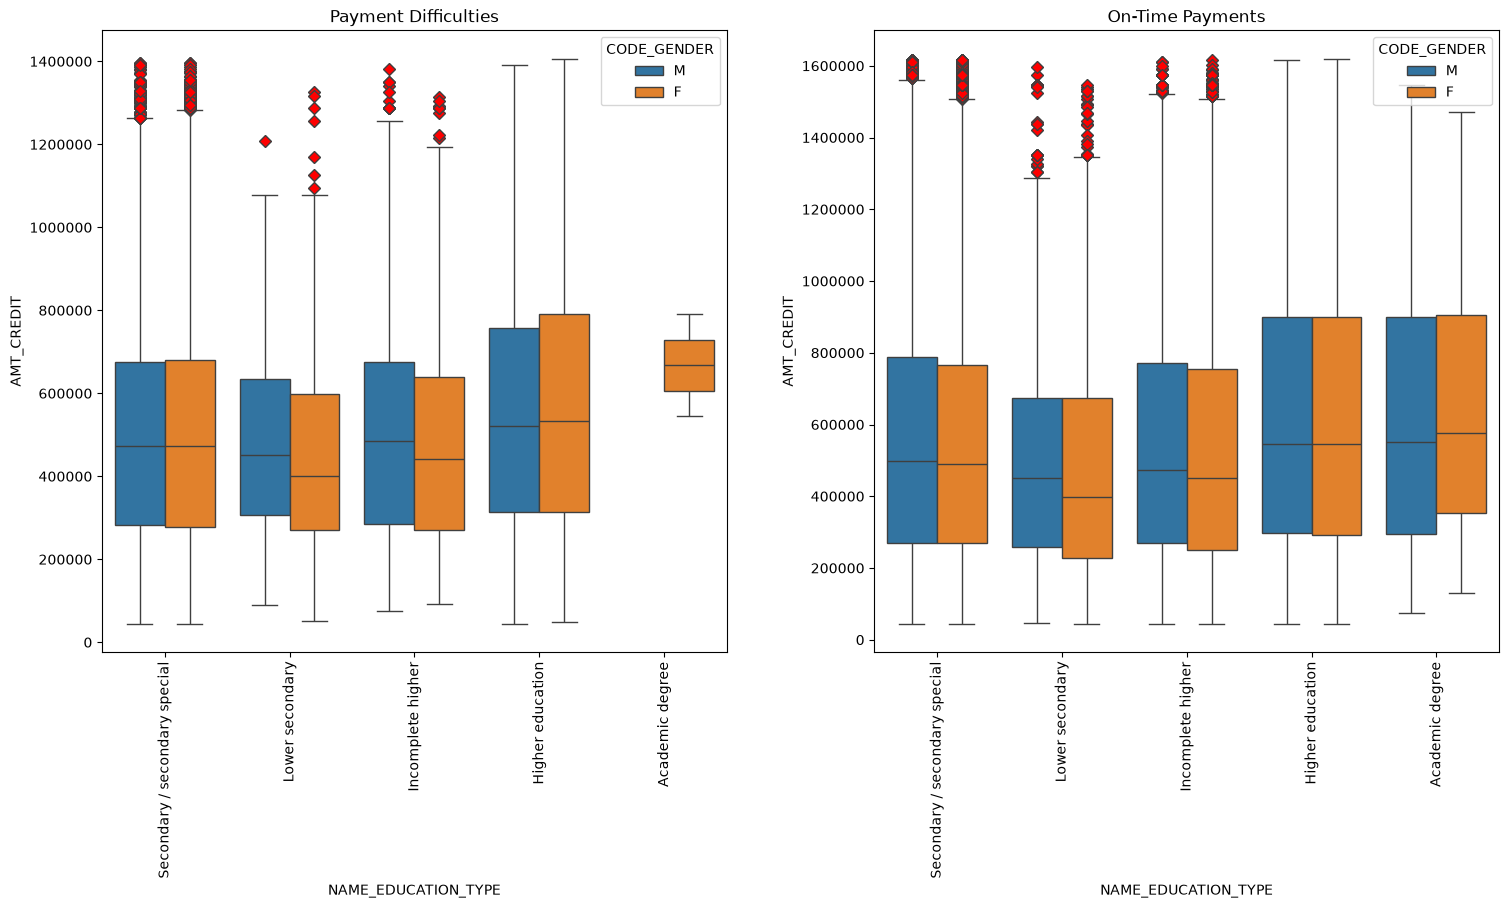

In [242]:
bi_boxplot('NAME_EDUCATION_TYPE','AMT_CREDIT',max_value1_AMT_CREDIT, max_value0_AMT_CREDIT, 'CODE_GENDER')

**Спостереження**

- Клієнти з "академічним ступенем" мають широкий діапазон кредитів для своєчасних платежів, тоді як для клієнтів з проблемами з оплатою цей діапазон значно нижчий
- Якщо поглянути на зведену статистику, то клієнти з "вищою освітою" та проблемами з оплатою беруть середній та медіанний кредит у значно більшому діапазоні, ніж клієнти з вчасною оплатою.
- Чоловіки з академічним ступенем освіти (Academic degree) завжди сплачують вчасно

# ДЗ 7. Кореляційний аналіз між двома категоріальними змінними і числовою

Проведіть аналогічний кореляційний аналіз для трійок змінних

- AMT_INCOME_TOTAL vs NAME_FAMILY_STATUS vs CODE_GENDER

Опціонально - трійки які можна додатково проаналізувати:
- AMT_INCOME_TOTAL vs YEARS_BIRTH_CATEGORY vs NAME_HOUSING_TYPE
- AMT_GOODS_PRICE vs NAME_INCOME_TYPE vs CODE_GENDER
- AMT_INCOME_TOTAL vs OCCUPATION_TYPE vs CODE_GENDER

А ще можете також проаналізувати додатково до обовʼязкової свою трійку :)

Для цього винесіть функціонал для аналізу у функцію та викличіть функцію для кожної трійки змінних.

Зробіть висновок про наявність кореляції між змінними.


Функція для кореляційного аналізу числової колонки і двох категоріальних (за прикладом аналізу `AMT_CREDIT` vs `NAME_EDUCATION_TYPE` vs `CODE_GENDER` вище, деталі - у docstring). Заготовку `numeric_vs_categorical_analysis` доповнено. На відміну від прикладу:
- таблиця будується для **всіх** комбінацій категорій (у прикладі `.head()` показує лише перші 5 рядків), а групи `TARGET` стоять поруч: кількість, медіана, середнє без викидів, відсоток викидів і частка `TARGET` = 1 у кожній комбінації;
- середнє рахується без викидів: у доходу дуже довгий правий хвіст (максимум - 117 000 000), і навіть одне значення сильно зсуває середнє цілої категорії;
- силу зв'язку виражено числом - **корельційним відношенням η²** (eta squared). Це частка дисперсії числової колонки, яку пояснюють категорії: 0% - середні в усіх категоріях однакові (розкид і форма розподілів при цьому можуть відрізнятися), 100% - значення повністю визначається категорією. Тобто η² вимірює лише відмінності середніх між категоріями. Пірсон і Спірмен тут не підходять, бо в `NAME_FAMILY_STATUS` і `CODE_GENDER` немає числового порядку. η² рахується для кожної категоріальної колонки окремо і для їх комбінації, на всіх даних і без викидів. Корінь η = √η² можна порівнювати за шкалою з коефіцієнтом кореляції;
- викиди відсікаються умовою `<=` межі. У прикладі `draw_boxplot` використовує `<`, тому відкидаються й значення, що дорівнюють межі. Для `AMT_INCOME_TOTAL` межа - рівно 337 500, і таких доходів 1 790 - це не викиди;
- на блок-діаграмах залишаються лише значення `<=` межі викидів групи (для доходу - `<= 337 500`). Червоні точки на них - це значення за вусами, розрахованими окремо в кожній комбінації статі та статусу вже після відсікання, а не викиди за межею всієї групи;
- групи підписані як у ДЗ 6: `TARGET = 0 (all other cases)`, бо за словником датасету `TARGET` = 0 - це всі інші випадки, а не обов'язково вчасні платежі.

In [243]:
def correlation_ratio_pct(data, numeric, categorical):
    """
    Корельційне відношення η² (eta squared) у відсотках - частка дисперсії числової колонки numeric,
    яку пояснюють категорії (одна колонка або комбінація кількох колонок зі списку categorical):
    η² = сума квадратів відхилень середніх категорій від загального середнього / загальна сума квадратів.
    0% - середні в усіх категоріях однакові (розкид і форма розподілів при цьому можуть відрізнятися),
    100% - значення повністю визначаються категорією. η² враховує лише відмінності середніх між категоріями.
    """
    data = data[[numeric] + categorical].dropna()
    category_mean = data.groupby(categorical, observed = True)[numeric].transform('mean')
    total_mean = data[numeric].mean()
    return ((category_mean - total_mean) ** 2).sum() / ((data[numeric] - total_mean) ** 2).sum() * 100


def numeric_vs_categorical_analysis(df0, df1, numeric, cat_x, cat_hue):
    """
    Кореляційний аналіз числової колонки numeric і двох категоріальних колонок cat_x та cat_hue
    у розрізі TARGET (за прикладом аналізу AMT_CREDIT vs NAME_EDUCATION_TYPE vs CODE_GENDER вище):
    - верхні межі викидів numeric за IQR (функція outlier_range) для кожної групи TARGET і для всіх заявників разом;
    - таблиця для кожної комбінації cat_x і cat_hue: кількість заявників, медіана, середнє без викидів
      і відсоток викидів у кожній групі TARGET, а також частка TARGET = 1 у комбінації;
    - сила зв'язку - корельційне відношення η² у відсотках (функція correlation_ratio_pct) для cat_x, cat_hue
      та їх комбінації, на всіх даних і без викидів (викиди - значення вищі за межу своєї групи);
    - блок-діаграми numeric за категоріями cat_x з розбивкою за cat_hue для обох груп TARGET після відсікання
      значень вище межі викидів групи; червоні точки на них - значення за вусами (1.5 IQR), розрахованими
      окремо в кожній комбінації cat_x і cat_hue вже після відсікання, а не викиди за межею всієї групи.
    Рядки з пропусками в будь-якій з трьох колонок не враховуються.
    Таблиці виводяться всередині функції і повертаються для подальших розрахунків, тому результат
    варто присвоювати змінним (інакше в останньому рядку клітинки таблиці виведуться ще раз).
    """
    columns = [numeric, cat_x, cat_hue]
    # назви груп - як у ДЗ 6: за словником датасету TARGET = 0 - це всі інші випадки, а не обов'язково вчасні платежі
    groups = {'TARGET = 1 (payment difficulties)': df1[columns].dropna(),
              'TARGET = 0 (all other cases)': df0[columns].dropna()}
    groups_all = {**groups, 'All applicants': pd.concat(groups.values())}

    # 1. Верхні межі викидів (нижні межі для сум зазвичай від'ємні, тому викиди - лише справа)
    max_values = {name: outlier_range(data, numeric) for name, data in groups_all.items()}
    print(f'Верхні межі викидів {numeric} за IQR:')
    for name, max_value in max_values.items():
        print(f'  {name}: {max_value:,.2f}')

    # 2. Статистика для кожної комбінації категорій.
    # Межа включається (<=): значення, що дорівнює межі, ще не є викидом
    stats = []
    for name, data in groups.items():
        suffix = name.split(' (')[0].replace('TARGET = ', '_')   # '_1' або '_0'
        is_outlier = data[numeric] > max_values[name]
        grouped = data.assign(is_outlier = is_outlier).groupby([cat_x, cat_hue], observed = True)
        stats.append(pd.DataFrame({
            f'count{suffix}': grouped[numeric].count(),
            f'median{suffix}': grouped[numeric].median(),
            f'mean_no_outliers{suffix}': data[~is_outlier].groupby([cat_x, cat_hue], observed = True)[numeric].mean(),
            f'outliers_pct{suffix}': grouped['is_outlier'].mean() * 100,
        }))
    stats = pd.concat(stats, axis = 1)
    stats[['count_1', 'count_0']] = stats[['count_1', 'count_0']].fillna(0).astype(int)
    stats['target_rate_pct'] = stats['count_1'] / (stats['count_1'] + stats['count_0']) * 100
    stats = stats[['count_1', 'count_0', 'target_rate_pct', 'median_1', 'median_0',
                   'mean_no_outliers_1', 'mean_no_outliers_0', 'outliers_pct_1', 'outliers_pct_0']]
    print(f'\n{numeric} за комбінаціями {cat_x} і {cat_hue} (суфікс _1 - TARGET = 1, _0 - TARGET = 0)')
    display(stats)

    # 3. Сила зв'язку: η² у відсотках для кожної категоріальної колонки окремо і для їх комбінації
    eta = {}
    for name, data in groups_all.items():
        clean = data[data[numeric] <= max_values[name]]
        eta[name] = {'count': len(data), 'count_no_outliers': len(clean)}
        for label, data_part in {'': data, '_no_outliers': clean}.items():
            for cats in ([cat_x], [cat_hue], [cat_x, cat_hue]):
                eta[name][f"eta2_pct_{'+'.join(cats)}{label}"] = correlation_ratio_pct(data_part, numeric, cats)
    eta = pd.DataFrame(eta).T.astype({'count': int, 'count_no_outliers': int})
    print(f"\nКорельційне відношення η² (%) - частка дисперсії {numeric}, яку пояснюють категорії")
    display(eta)

    # 4. Блок-діаграми після відсікання значень вище межі викидів - кожна група за власною межею, як у прикладі вище.
    # Червоні точки - значення за вусами (1.5 IQR), які seaborn рахує окремо в кожній комбінації cat_x і cat_hue
    order = sorted(groups_all['All applicants'][cat_x].unique())
    hue_order = sorted(groups_all['All applicants'][cat_hue].unique())
    fig, axes = plt.subplots(1, 2, figsize = (16, 8), sharey = True)
    for ax, (name, data) in zip(axes, groups.items()):
        sns.boxplot(data = data[data[numeric] <= max_values[name]], x = cat_x, y = numeric, hue = cat_hue,
                    order = order, hue_order = hue_order, flierprops = dict(markerfacecolor = 'r', marker = 'D'), ax = ax)
        ax.set_title(f'{name}\nпісля відсікання {numeric} вище {max_values[name]:,.0f}')
        ax.ticklabel_format(style = 'plain', axis = 'y')
        ax.tick_params(axis = 'x', rotation = 45)
    # одна легенда праворуч від графіків, щоб не закривала блоки
    axes[0].get_legend().remove()
    axes[1].legend(title = cat_hue, bbox_to_anchor = (1.02, 1), loc = 'upper left')
    plt.tight_layout(pad = 4)
    plt.show()

    return stats, eta

### Аналіз стовпців `AMT_INCOME_TOTAL` vs `NAME_FAMILY_STATUS` vs `CODE_GENDER`

Верхні межі викидів AMT_INCOME_TOTAL за IQR:
  TARGET = 1 (payment difficulties): 337,500.00
  TARGET = 0 (all other cases): 337,500.00
  All applicants: 337,500.00

AMT_INCOME_TOTAL за комбінаціями NAME_FAMILY_STATUS і CODE_GENDER (суфікс _1 - TARGET = 1, _0 - TARGET = 0)


count_1  count_0  target_rate_pct  median_1  \
NAME_FAMILY_STATUS   CODE_GENDER                                                
Civil marriage       F               1753    19017             8.44 135000.00   
                     M               1208     7797            13.41 157500.00   
Married              F               8324   114125             6.80 135000.00   
                     M               6526    67459             8.82 157500.00   
Separated            F               1045    14416             6.76 135000.00   
                     M                575     3734            13.34 157500.00   
Single / not married F               2220    26364             7.77 135000.00   
                     M               2237    14623            13.27 157500.00   
Widow                F                828    14360             5.45 130500.00   
                     M                109      791            12.11 135000.00   

                                  median_0  mean_no_outliers_1  \
NAME_FAMILY_STATUS   CODE_GENDER                                 
Civil marriage       F           135000.00           145966.83   
                     M           157500.00           161755.46   
Married              F           135000.00           138909.74   
                     M           180000.00           167587.73   
Separated            F           139500.00           149536.65   
                     M           180000.00           166245.00   
Single / not married F           135000.00           142628.28   
                     M           157500.00           157287.57   
Widow                F           126000.00           137177.87   
                     M           135000.00           143381.38   

                                  mean_no_outliers_0  outliers_pct_1  \
NAME_FAMILY_STATUS   CODE_GENDER                                       
Civil marriage       F                     151377.58            2.28   
                     M                     166882.75            3.89   
Married              F                     144188.70            2.19   
                     M                     175818.44            5.07   
Separated            F                     152895.00            4.11   
                     M                     172094.29            4.70   
Single / not married F                     149381.22            2.57   
                     M                     165582.43            3.26   
Widow                F                     136036.75            1.81   
                     M                     147034.99            0.92   

                                  outliers_pct_0  
NAME_FAMILY_STATUS   CODE_GENDER                  
Civil marriage       F                      3.49  
                     M                      5.95  
Married              F                      3.28  
                     M                      7.90  
Separated            F                      4.43  
                     M                      6.99  
Single / not married F                      3.76  
                     M                      5.65  
Widow                F                      1.96  
                     M                      3.92


Корельційне відношення η² (%) - частка дисперсії AMT_INCOME_TOTAL, яку пояснюють категорії


,count,count_no_outliers,eta2_pct_NAME_FAMILY_STATUS,eta2_pct_CODE_GENDER,eta2_pct_NAME_FAMILY_STATUS+CODE_GENDER,eta2_pct_NAME_FAMILY_STATUS_no_outliers,eta2_pct_CODE_GENDER_no_outliers,eta2_pct_NAME_FAMILY_STATUS+CODE_GENDER_no_outliers
TARGET = 1 (payment difficulties),24825,24009,0.01,0.02,0.03,0.22,3.58,4.03
TARGET = 0 (all other cases),282686,269467,0.32,2.80,3.13,0.46,3.98,4.46
All applicants,307511,293476,0.07,0.56,0.63,0.43,3.90,4.37


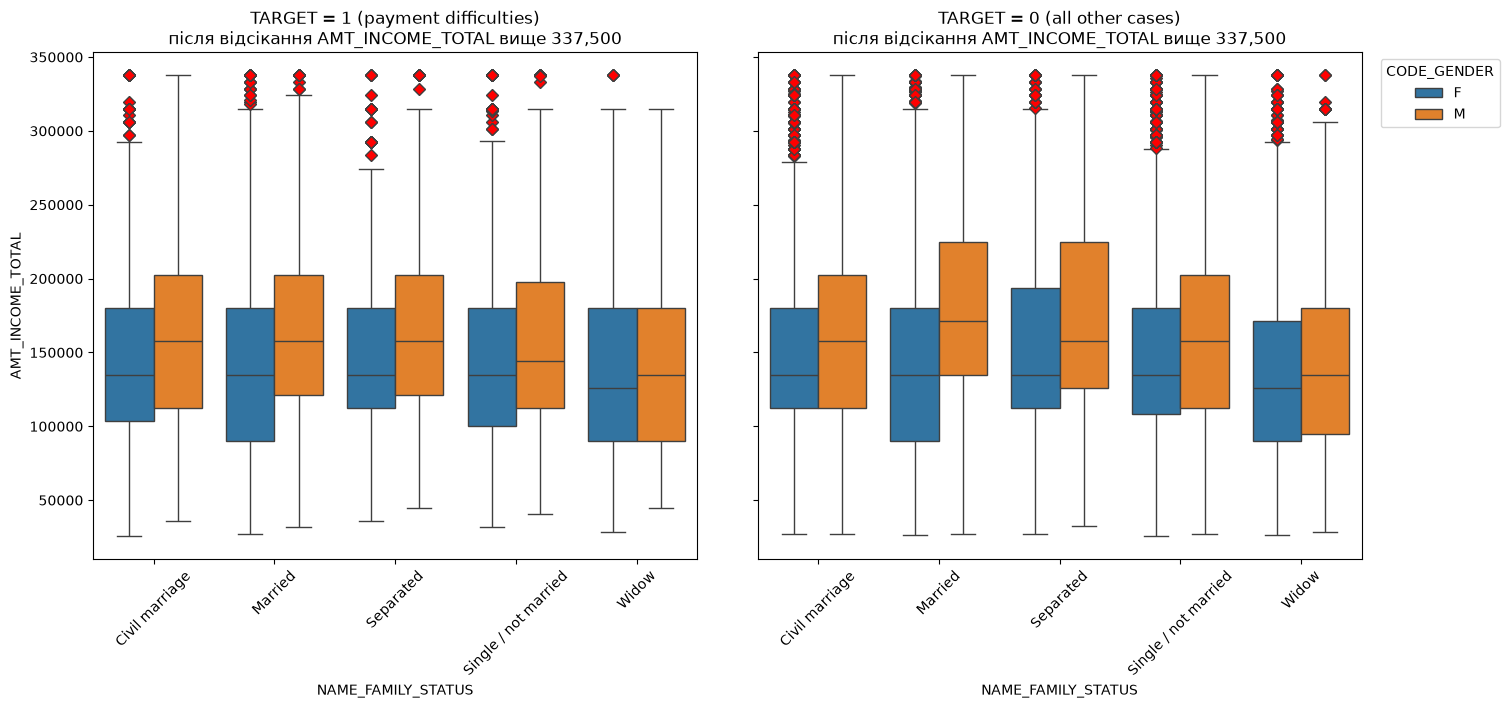

In [244]:
income_family_gender_stats, income_family_gender_eta = numeric_vs_categorical_analysis(
    df0, df1, 'AMT_INCOME_TOTAL', 'NAME_FAMILY_STATUS', 'CODE_GENDER')

На всіх даних η² для `TARGET` = 1 майже нульовий (0.01 - 0.03%), а без викидів - 0.2 - 4.0%. Перевіримо, чи не створює цю різницю один найбільший дохід, і порахуємо η² для логарифма доходу на всіх даних, без відсікання викидів (логарифм стискає правий хвіст)

In [245]:
# Чому на всіх даних η² для TARGET = 1 майже нульовий, а без викидів - ні?
# Подивимось на найбільші доходи і на внесок найбільшого з них у загальну суму квадратів відхилень
display(df.nlargest(5, 'AMT_INCOME_TOTAL')[['AMT_INCOME_TOTAL', 'NAME_FAMILY_STATUS', 'CODE_GENDER', 'TARGET']])

income1 = df1['AMT_INCOME_TOTAL']
top_share = (income1.max() - income1.mean()) ** 2 / ((income1 - income1.mean()) ** 2).sum() * 100
print(f'TARGET = 1: дохід {income1.max():,.0f} дає {top_share:.1f}% загальної суми квадратів відхилень')
df1_without_top = df1.drop(index = income1.idxmax())
print('η² (%) для TARGET = 1 без цього одного рядка: ' + ', '.join(
    f"{'+'.join(cats)} - {correlation_ratio_pct(df1_without_top, 'AMT_INCOME_TOTAL', cats):.2f}"
    for cats in (['NAME_FAMILY_STATUS'], ['CODE_GENDER'], ['NAME_FAMILY_STATUS', 'CODE_GENDER'])))

# η² для логарифма доходу - на всіх даних, без відсікання викидів:
# логарифм стискає довгий правий хвіст, і жоден рядок не домінує в дисперсії
log_eta = {}
for name, data in {'TARGET = 1 (payment difficulties)': df1, 'TARGET = 0 (all other cases)': df0,
                   'All applicants': df}.items():
    data = data.assign(LOG_AMT_INCOME_TOTAL = np.log(data['AMT_INCOME_TOTAL']))
    log_eta[name] = {f"eta2_pct_log_{'+'.join(cats)}": correlation_ratio_pct(data, 'LOG_AMT_INCOME_TOTAL', cats)
                     for cats in (['NAME_FAMILY_STATUS'], ['CODE_GENDER'], ['NAME_FAMILY_STATUS', 'CODE_GENDER'])}
pd.DataFrame(log_eta).T

,AMT_INCOME_TOTAL,NAME_FAMILY_STATUS,CODE_GENDER,TARGET
12840,117000000.00,Married,F,1
203693,18000090.00,Married,M,0
246858,13500000.00,Married,M,0
77768,9000000.00,Civil marriage,F,0
131127,6750000.00,Married,M,0


TARGET = 1: дохід 117,000,000 дає 98.6% загальної суми квадратів відхилень
η² (%) для TARGET = 1 без цього одного рядка: NAME_FAMILY_STATUS - 0.23, CODE_GENDER - 2.72, NAME_FAMILY_STATUS+CODE_GENDER - 3.16


,eta2_pct_log_NAME_FAMILY_STATUS,eta2_pct_log_CODE_GENDER,eta2_pct_log_NAME_FAMILY_STATUS+CODE_GENDER
TARGET = 1 (payment difficulties),0.32,4.07,4.66
TARGET = 0 (all other cases),0.59,4.68,5.27
All applicants,0.56,4.57,5.16


Серед жінок більше пенсіонерів, і вони старші, тому частина розриву в доході між статями може пояснюватися типом доходу, а не самою статтю (`AMT_INCOME_TOTAL` - це заявлений дохід, у тому числі пенсія). Перевіримо: повторимо аналіз лише для працюючих (`NAME_INCOME_TYPE` == 'Working', найбільша група) і порівняємо розрив між статями (на скільки відсотків середній дохід чоловіків без викидів вищий, ніж у жінок) з розривом для всіх заявників

,pensioner_pct,years_birth_median
CODE_GENDER,,
F,22.36,45.00
M,9.61,40.00


Верхні межі викидів AMT_INCOME_TOTAL за IQR:
  TARGET = 1 (payment difficulties): 281,250.00
  TARGET = 0 (all other cases): 337,500.00
  All applicants: 337,500.00

AMT_INCOME_TOTAL за комбінаціями NAME_FAMILY_STATUS і CODE_GENDER (суфікс _1 - TARGET = 1, _0 - TARGET = 0)


count_1  count_0  target_rate_pct  median_1  \
NAME_FAMILY_STATUS   CODE_GENDER                                                
Civil marriage       F               1062     9951             9.64 135000.00   
                     M                857     4856            15.00 157500.00   
Married              F               4934    55467             8.17 126000.00   
                     M               4287    38601            10.00 157500.00   
Separated            F                599     6855             8.04 135000.00   
                     M                386     2259            14.59 157500.00   
Single / not married F               1284    12617             9.24 135000.00   
                     M               1539     8847            14.82 135000.00   
Widow                F                225     3790             5.60 135000.00   
                     M                 51      307            14.25 135000.00   

                                  median_0  mean_no_outliers_1  \
NAME_FAMILY_STATUS   CODE_GENDER                                 
Civil marriage       F           135000.00           137474.04   
                     M           157500.00           154073.93   
Married              F           135000.00           131616.76   
                     M           175500.00           158726.85   
Separated            F           135000.00           144165.37   
                     M           157500.00           155549.15   
Single / not married F           135000.00           135094.99   
                     M           157500.00           149817.35   
Widow                F           135000.00           147053.65   
                     M           157500.00           145640.62   

                                  mean_no_outliers_0  outliers_pct_1  \
NAME_FAMILY_STATUS   CODE_GENDER                                       
Civil marriage       F                     145733.53            2.92   
                     M                     162374.67            5.72   
Married              F                     140668.11            3.81   
                     M                     172900.33            7.67   
Separated            F                     151567.07            5.51   
                     M                     168334.32            8.03   
Single / not married F                     145437.71            4.21   
                     M                     159553.21            4.74   
Widow                F                     145467.72            3.56   
                     M                     156266.26            5.88   

                                  outliers_pct_0  
NAME_FAMILY_STATUS   CODE_GENDER                  
Civil marriage       F                      2.06  
                     M                      4.04  
Married              F                      2.33  
                     M                      5.57  
Separated            F                      2.99  
                     M                      4.87  
Single / not married F                      2.54  
                     M                      3.31  
Widow                F                      1.93  
                     M                      2.93


Корельційне відношення η² (%) - частка дисперсії AMT_INCOME_TOTAL, яку пояснюють категорії


,count,count_no_outliers,eta2_pct_NAME_FAMILY_STATUS,eta2_pct_CODE_GENDER,eta2_pct_NAME_FAMILY_STATUS+CODE_GENDER,eta2_pct_NAME_FAMILY_STATUS_no_outliers,eta2_pct_CODE_GENDER_no_outliers,eta2_pct_NAME_FAMILY_STATUS+CODE_GENDER_no_outliers
TARGET = 1 (payment difficulties),15224,14425,0.01,0.00,0.01,0.06,4.17,4.74
TARGET = 0 (all other cases),143550,138695,0.09,3.02,3.37,0.08,4.36,4.84
All applicants,158774,153552,0.01,0.25,0.28,0.07,4.25,4.74


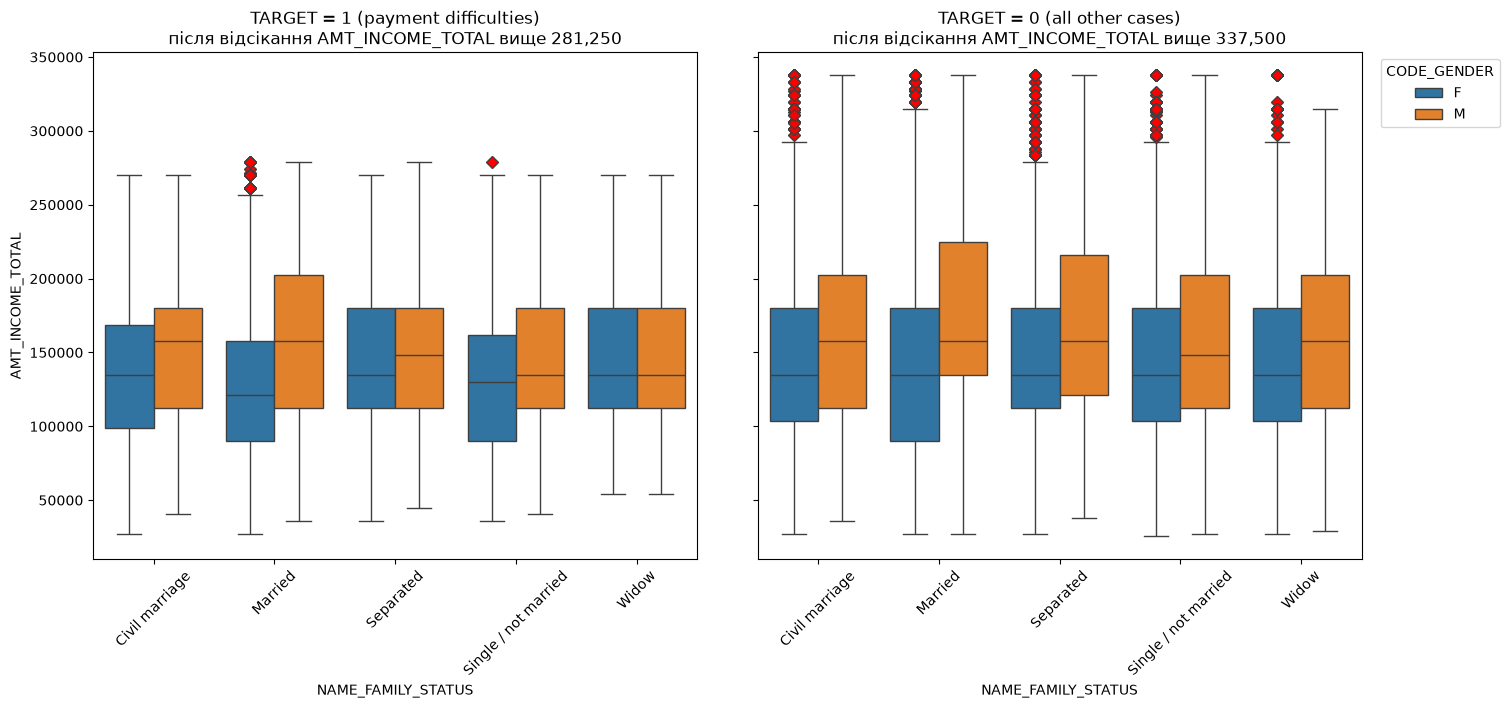

Розрив між статями, %: усі заявники vs працюючі


All applicants               Working           
                         TARGET = 1 TARGET = 0 TARGET = 1 TARGET = 0
NAME_FAMILY_STATUS                                                  
Civil marriage                10.82      10.24      12.07      11.42
Married                       20.65      21.94      20.60      22.91
Separated                     11.17      12.56       7.90      11.06
Single / not married          10.28      10.85      10.90       9.71
Widow                          4.52       8.08      -0.96       7.42

In [246]:
# Частка пенсіонерів і медіанний вік за статтю
display(df.groupby('CODE_GENDER').agg(
    pensioner_pct = ('NAME_INCOME_TYPE', lambda s: (s == 'Pensioner').mean() * 100),
    years_birth_median = ('YEARS_BIRTH', 'median')))

# Той самий аналіз лише для працюючих (межа викидів рахується для цієї підвибірки заново)
working_stats, working_eta = numeric_vs_categorical_analysis(
    df0[df0['NAME_INCOME_TYPE'] == 'Working'], df1[df1['NAME_INCOME_TYPE'] == 'Working'],
    'AMT_INCOME_TOTAL', 'NAME_FAMILY_STATUS', 'CODE_GENDER')


def gender_gap_pct(stats):
    """На скільки відсотків середній дохід чоловіків без викидів вищий, ніж у жінок, у кожному статусі"""
    return pd.DataFrame({
        f'TARGET = {t}': (stats[f'mean_no_outliers_{t}'].xs('M', level = 'CODE_GENDER')
                          / stats[f'mean_no_outliers_{t}'].xs('F', level = 'CODE_GENDER') - 1) * 100
        for t in (1, 0)})


print('Розрив між статями, %: усі заявники vs працюючі')
pd.concat({'All applicants': gender_gap_pct(income_family_gender_stats),
           'Working': gender_gap_pct(working_stats)}, axis = 1)

**Спостереження**
- Аналіз зроблено для всіх 307 511 заявників (пропусків у трьох колонках немає, `XNA` у `CODE_GENDER` і `Unknown` у `NAME_FAMILY_STATUS` замінено в ДЗ 2): 24 825 з `TARGET` = 1 і 282 686 з `TARGET` = 0.
- Верхня межа викидів `AMT_INCOME_TOTAL` за IQR однакова для обох груп і для всіх заявників разом - **337 500**. Викидів 816 (3.29%) у `TARGET` = 1 і 13 219 (4.68%) у `TARGET` = 0; найбільше їх серед одружених чоловіків (5.07% і 7.90%). Доходи сильно округлені (135 000, 112 500, 157 500, 180 000...), тому медіани в багатьох комбінаціях однакові.
- **Стать.** У кожному сімейному статусі і в обох групах медіанний дохід чоловіків не нижчий, ніж у жінок: 135 000 - 180 000 проти 126 000 - 139 500 (для всіх заявників - 180 000 проти 135 000). Середній дохід без викидів у чоловіків вищий приблизно на 17 - 19%: 164 403 проти 141 033 для `TARGET` = 1 і 173 058 проти 145 666 для `TARGET` = 0. Але розрив між статями залежить від сімейного статусу (різниця середніх без викидів, чоловіки мінус жінки): найбільший - у `Married`: 28 678 (+20.6%) для `TARGET` = 1 і 31 630 (+21.9%) для `TARGET` = 0; у `Civil marriage`, `Separated` і `Single / not married` - 14 659 - 19 199 (+10 - 13%); найменший - у `Widow`: 6 204 (+4.5%) і 10 998 (+8.1%). Але чоловіків `Widow` мало - 109 у `TARGET` = 1 і 791 у `TARGET` = 0 (у `TARGET` = 1 за межею викидів лише 1 людина - 0.92%), тому розрив для `Widow`, особливо в `TARGET` = 1, оцінено ненадійно: кілька великих доходів помітно зсувають середнє. Серед працюючих чоловіків `Widow` з `TARGET` = 1 лише 51, і там розрив навіть від'ємний (-1.0%). Частина розриву могла б пояснюватися типом доходу (`AMT_INCOME_TOTAL` - це заявлений дохід, у тому числі пенсія): серед жінок пенсіонерів 22.4% проти 9.6% серед чоловіків, медіанний вік - 45 і 40 років. Але серед працюючих (`NAME_INCOME_TYPE` == 'Working', 158 774 заявники) розрив зберігається: у `Married` - +20.6% і +22.9%, у `Civil marriage`, `Separated` і `Single / not married` - +7.9 - 12.1%, а η² статі без викидів навіть трохи вищий - 4.17% і 4.36% (у всіх заявників - 3.58% і 3.98%; межа викидів для `Working` з `TARGET` = 1 - 281 250). Тобто більшою часткою пенсіонерок розрив не пояснюється.
- **Сімейний статус.** У межах однієї статі медіани за статусами майже не відрізняються: у жінок - 126 000 - 139 500, у чоловіків - 157 500 - 180 000 (крім `Widow` - 135 000). Трохи нижчий дохід у `Widow` можна пояснити віком і пенсією - це гіпотеза, окремо не перевірялась: медіанний вік у `Widow` - 59 років, і 58% з них - пенсіонери (в інших статусах 37 - 46 років і 12 - 19%).
- **Сила зв'язку (η² без викидів).** Стать пояснює **3.6 - 4.0%** дисперсії доходу, сімейний статус - **0.2 - 0.5%**, обидві колонки разом - **4.0 - 4.5%**. Це відповідає η ≈ 0.2 для статі (слабкий зв'язок) і η ≈ 0.05 - 0.07 для сімейного статусу (відмінності середніх малі). Тобто у всій вибірці сімейний статус мало додає до поясненої дисперсії. Це не означає, що розрив між статями однаковий в усіх статусах - його треба порівнювати за таблицею (див. пункт «Стать»). Оцінку η² для статі без викидів варто вважати **консервативною**: межа 337 500 спільна для обох статей, а викидів у чоловіків приблизно вдвічі більше (4.50% проти 2.38% у `TARGET` = 1 і 7.32% проти 3.35% у `TARGET` = 0). Тому відсікання сильніше зрізає правий хвіст доходів чоловіків і зближує середні. Для логарифма доходу, де нічого не відсікається, η² статі вищий - 4.07% і 4.68%. Без викидів оцінки для `TARGET` = 1 і `TARGET` = 0 близькі (для статі - 3.58% і 3.98%), але на всіх даних вони сильно відрізняються (0.02% і 2.80%) - див. наступний пункт.
- **Вплив викидів.** На всіх даних η² для `TARGET` = 1 - лише 0.01 - 0.03%, бо один дохід **117 000 000** (жінка, `Married`, `TARGET` = 1; виявлений ще в ДЗ 3) дає **98.6%** загальної суми квадратів відхилень у групі. Без цього одного рядка η² - 0.23% / 2.72% / 3.16%. Для логарифма доходу на всіх даних: стать - 4.1 - 4.7%, сімейний статус - 0.3 - 0.6%, разом - 4.7 - 5.3%, тобто висновки ті самі. Як і Пірсон, η² на сирих даних дуже чутливий до викидів, тому для доходу його варто рахувати без викидів або для логарифма.
- **Групи `TARGET`.** Розподіли доходу у двох групах майже однакові. За таблицею (усі дані) медіана помітно відрізняється лише в чоловіків `Married` і `Separated`: 157 500 для `TARGET` = 1 проти 180 000 для `TARGET` = 0, а в жінок `Separated` і `Widow` - на 4 500. На блок-діаграмах (доходи `<= 337 500`) картина медіан інша: у чоловіків `Married` різниця зменшується (157 500 проти 171 000); у чоловіків `Separated` і в жінок `Separated` і `Widow` вона зникає (медіани в обох групах - 157 500, 135 000 і 126 000); а в чоловіків `Single / not married` різниця, навпаки, з'являється лише після відсікання (144 000 проти 157 500, хоча на всіх даних - 157 500 в обох групах). Середнє без викидів у `TARGET` = 1 нижче на 2 - 5% у всіх комбінаціях, крім жінок `Widow` (вище на 0.8%); найбільша різниця - у чоловіків `Single / not married` і `Married` (157 288 проти 165 582 і 167 588 проти 175 818).
- **Частка `TARGET` = 1** (побічне спостереження з таблиці): у чоловіків вона вища в кожному статусі - 12.1 - 13.4% проти 5.5 - 8.4% у жінок. Виняток - одружені чоловіки: 8.82%. Найнижча частка - у жінок `Widow` (5.45%). Це однофакторне порівняння: вік, дохід та інші ознаки тут не враховані.

**Висновок**
- Між `AMT_INCOME_TOTAL` і `CODE_GENDER` є **слабкий зв'язок** (η² ≈ 4%, η ≈ 0.2): у кожному сімейному статусі чоловіки в середньому мають вищий заявлений дохід, ніж жінки. Розрив зберігається і серед працюючих (`Working`), тому він не пояснюється лише більшою часткою пенсіонерок серед жінок.
- За `NAME_FAMILY_STATUS` **відмінності середніх малі** (η² ≈ 0.2 - 0.6%, η ≈ 0.05 - 0.08). Ці оцінки отримано після відсікання доходів вище 337 500 (η² ≈ 0.2 - 0.5%) і для логарифма доходу (η² ≈ 0.3 - 0.6%). Помітно нижчий дохід лише у `Widow`; гіпотеза - це ефект віку та пенсії, а не самого статусу. Комбінація двох колонок пояснює ненабагато більше дисперсії, ніж одна стать (4.0 - 4.5% проти 3.6 - 4.0%), хоча розрив між статями за статусами різний: від +4.5 - 8% у `Widow` до +21 - 22% у `Married` (оцінка для `Widow` ненадійна: чоловіків `Widow` у `TARGET` = 1 лише 109).
- Після обробки правого хвоста оцінки зв'язку доходу зі статтю в групах `TARGET` близькі: η² - 3.58% і 3.98% без викидів, 4.07% і 4.68% для логарифма доходу. На всіх даних вони сильно відрізняються (0.02% і 2.80%), бо в `TARGET` = 1 дисперсію майже повністю визначає один дохід 117 000 000. η² рахується всередині кожної групи окремо, тому не показує, чи відрізняє дохід `TARGET` = 1 від `TARGET` = 0. Між групами можна порівняти лише спостережувані середні без викидів: у `TARGET` = 1 вони нижчі на 2 - 5% у 9 з 10 комбінацій статі та статусу (у жінок `Widow` - вищі на 0.8%). Чи достатньо такої різниці для розрізнення груп, цей аналіз не перевіряв. Окремо в таблиці видно, що частка `TARGET` = 1 у чоловіків вища, ніж у жінок (12.1 - 13.4%, у `Married` - 8.82%, проти 5.5 - 8.4%), але це однофакторне спостереження, яке потрібно перевіряти з урахуванням інших ознак.
- Рядок з доходом 117 000 000 (імовірно, помилка введення) практично сам визначає дисперсію доходу в групі `TARGET` = 1, тому в подальшому аналізі його варто виключити або аналізувати дохід у логарифмічній шкалі.

## Категоріальні та категоріальні змінні

### Аналіз стовпців `NAME_INCOME_TYPE` vs `CODE_GENDER`

In [247]:
def bi_countplot_target(df0, df1, column, hue_column) :
    group_name = f'Нормалізований розподіл значень за категорією: {column}'
    print (group_name.upper())

    pltname = 'Клієнт зі складнощями щодо платності'
    unique_hue_values = df1[hue_column].unique()
    fig, axes = plt.subplots(nrows=1, ncols=2)
    fig.set_size_inches(14,4)

    proportions = df1.groupby(hue_column)[column].value_counts(normalize=True)
    proportions = (proportions*100).round(2)
    ax = proportions.unstack(hue_column).sort_values(
      by=unique_hue_values[0], ascending=False
      ).plot.bar(ax=axes[0], title=pltname)

    # анотація значень в барплоті
    for container in ax.containers:
      ax. bar_label(container, fmt='{:,.1f}%')

    pltname = 'Клієнти зі своєчасними платежами'
    unique_hue_values = df0[hue_column].unique()

    proportions = df0.groupby(hue_column)[column].value_counts (normalize=True)
    proportions = (proportions*100).round(2)
    ax = proportions.unstack(hue_column).sort_values(
    by=unique_hue_values[0], ascending=False
      ).plot.bar(ax=axes[1], title=pltname)

    for container in ax.containers:
      ax.bar_label(container, fmt='{:,.1f}%')

    plt.show()

    #------------
    group_name = f'Кількість значень за категорією {column}'
    print(group_name.upper())

    pltname = 'Клієнт зі своєчасними платежами'
    unique_hue_values = df1[hue_column].unique()
    fig, axes = plt.subplots(nrows=1, ncols=2)
    fig.set_size_inches(14,4)
    counts = df1.groupby(hue_column)[column].value_counts()
    ax = counts.unstack(hue_column).sort_values(
      by=unique_hue_values [0], ascending=False
      ).plot.bar(ax=axes [0], title=pltname )

    for container in ax.containers:
      ax.bar_label(container)

    pltname = 'Клієнти зі своєчасними платежами'
    unique_hue_values = df0[hue_column].unique()
    counts = df0.groupby(hue_column)[column].value_counts()
    ax = counts.unstack(hue_column).sort_values (
      by=unique_hue_values[0], ascending=False
      ).plot.bar(ax=axes[1], title=pltname)

    for container in ax. containers:
      ax.bar_label(container)

    plt.show()

НОРМАЛІЗОВАНИЙ РОЗПОДІЛ ЗНАЧЕНЬ ЗА КАТЕГОРІЄЮ: NAME_INCOME_TYPE


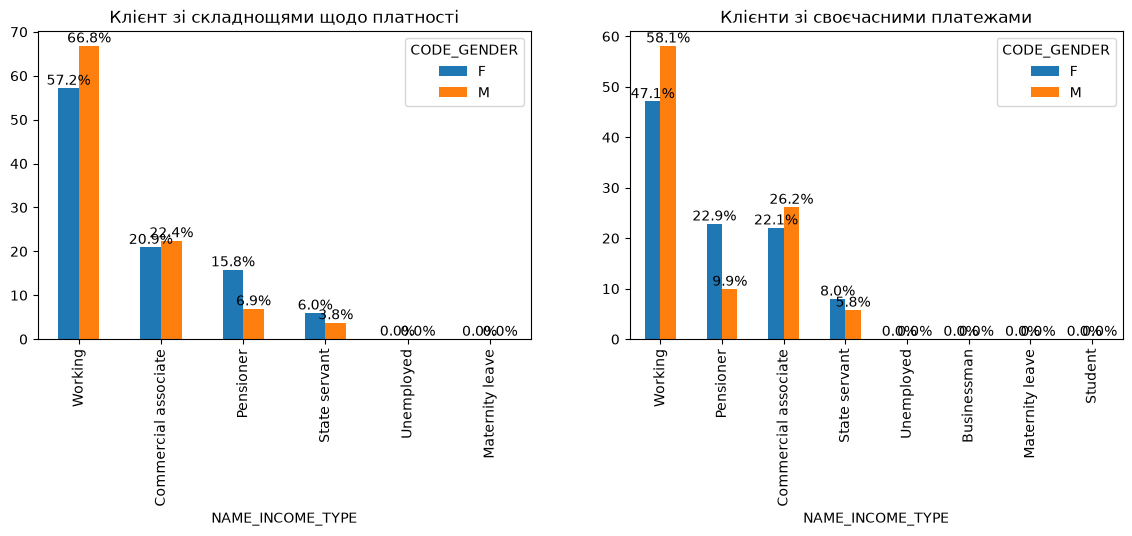

КІЛЬКІСТЬ ЗНАЧЕНЬ ЗА КАТЕГОРІЄЮ NAME_INCOME_TYPE


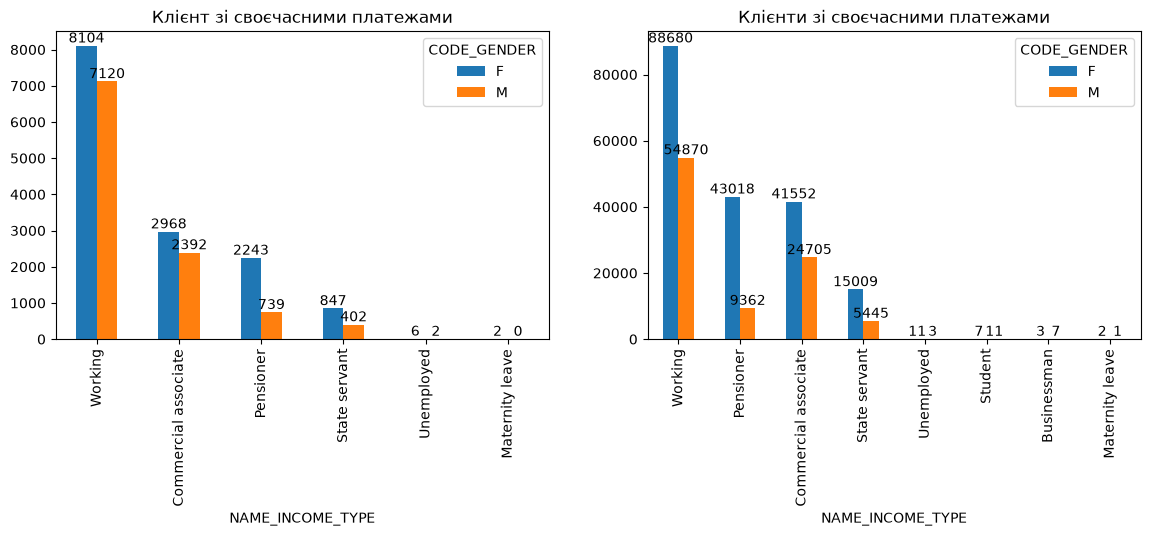

In [248]:
bi_countplot_target(df0, df1, 'NAME_INCOME_TYPE','CODE_GENDER')

**Спостереження**
- Клієнти категорії `Working` та `Male` мають більше труднощів з оплатою порівняно з тими, хто платить вчасно
- Клієнти категорії `Pensioner` та `Female` мають більше труднощів з оплатою порівняно з тими, хто платить вчасно
- Клієнти категорії `Businessman` та `Student` здійснюють платежі вчасно, хоча їхня історія невелика

# ДЗ 8. Аналіз взаємозалежностей між двома категоріальними змінними

Проведіть подібний до прикладу аналіз залежностей між категоріальними змінними для пар змінних

- NAME_EDUCATION_TYPE vs CODE_GENDER

Опціонально:
- NAME_FAMILY_STATUS vs OCCUPATION_TYPE
- OCCUPATION_TYPE vs NAME_CONTRACT_TYPE

Опишіть спостереження щодо того, чи є цікаві знахідки стосовно цільової змінної з цього аналізу.

Функція для аналізу пари категоріальних колонок у розрізі `TARGET` (за прикладом аналізу `NAME_INCOME_TYPE` vs `CODE_GENDER` вище, деталі - у docstring). На відміну від прикладу `bi_countplot_target`:
- категорії на обох графіках стоять в **однаковому порядку** (для освіти - від нижчого рівня до вищого), а осі `y` спільні. У прикладі стовпці сортуються окремо в кожній групі за першим значенням `unique()`, тому порядок категорій на двох графіках може відрізнятися;
- замість графіків абсолютних кількостей (у `TARGET` = 0 рядків приблизно в 11 разів більше, тому їх важко порівнювати) кількості виводяться в таблиці, а другий графік показує **частку `TARGET` = 1** у кожній комбінації категорій - саме це відповідає на питання про цільову змінну. Пунктир на ньому - частка `TARGET` = 1 для всіх заявників (8.07%);
- силу зв'язку виражено числом - **V Крамера** (Cramér's V) на основі критерію **χ²** (хі-квадрат): 0 - колонки незалежні, 1 - одна колонка повністю визначає іншу. Орієнтовно V < 0.1 - зв'язок дуже слабкий або відсутній. V рахується для пари колонок у кожній групі `TARGET`, а також для кожної колонки і їх комбінації з `TARGET`. Але для зв'язку з `TARGET` поріг V < 0.1 вводить в оману: `TARGET` бінарний і незбалансований (8% / 92%), тому V залишається малим навіть тоді, коли частки `TARGET` = 1 у групах відрізняються в рази. Тому для зв'язку з `TARGET` додано **lift** (частка `TARGET` = 1 у комбінації, поділена на частку для всіх заявників, 8.07%) та **Information Value (IV)** - стандартну міру прогнозної сили ознаки в кредитному скорингу (< 0.02 - не прогнозує, 0.02 - 0.1 - слабко, 0.1 - 0.3 - середньо, > 0.3 - сильно). При ~300 000 рядках навіть дуже малі відмінності дають p-value ≈ 0, тому для висновків важливий саме V, а не p-value. Малі категорії можна для χ², V та IV об'єднати з сусідньою (параметр `test_merge`), щоб очікувані частоти були не менші за 5 - для освіти так об'єднано `Academic degree` (164 заявники) з `Higher education`; таблиці часток і графіки будуються за вихідними категоріями. χ², p-value і V Крамера рахує `scipy` (`chi2_contingency` і `contingency.association`);
- групи підписані як у ДЗ 6: `TARGET = 0 (all other cases)`, бо за словником датасету `TARGET` = 0 - це всі інші випадки, а не обов'язково вчасні платежі (у прикладі другий графік кількостей для `TARGET` = 1 підписаний як "Клієнт зі своєчасними платежами").

In [249]:
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association


def chi2_cramers_v(a, b):
    """
    Критерій χ² незалежності двох категоріальних колонок a і b (scipy.stats.chi2_contingency)
    та V Крамера (scipy.stats.contingency.association): 0 - колонки незалежні, 1 - одна колонка повністю визначає іншу.
    a може бути списком колонок - тоді рядки таблиці спряженості - комбінації їх значень.
    correction = False - без поправки Йейтса для таблиць 2 x 2, щоб χ² рахувався так само, як для більших таблиць
    (association рахує V теж без поправки).
    Якщо очікувані частоти в деяких клітинках < 5, χ² і p-value для такої таблиці наближені.
    """
    observed = pd.crosstab(a, b)
    chi2, p_value, dof, expected = chi2_contingency(observed, correction = False)
    return {'count': observed.to_numpy().sum(), 'chi2': chi2, 'dof': dof, 'p_value': p_value,
            'min_expected': expected.min(), 'cramers_v': association(observed, method = 'cramer')}


def information_value(a, target):
    """
    Information Value (IV) - стандартна в кредитному скорингу міра того, наскільки категоріальна колонка a
    розділяє TARGET = 1 і TARGET = 0 (a може бути списком колонок - тоді категорії - комбінації їх значень):
    WoE = ln(частка категорії серед TARGET = 1 / частка категорії серед TARGET = 0),
    IV = сума (частка серед TARGET = 1 - частка серед TARGET = 0) * WoE.
    Орієнтовна шкала: < 0.02 - не прогнозує, 0.02 - 0.1 - слабко, 0.1 - 0.3 - середньо, > 0.3 - сильно.
    На відміну від V Крамера, IV не стискається дисбалансом TARGET (8% / 92%): він порівнює розподіли
    категорій усередині TARGET = 1 і TARGET = 0, а не частоти в усій таблиці.
    Нульові клітинки замінюються на 0.5, щоб WoE не був нескінченним (наприклад, 0 заявників з TARGET = 1).
    """
    observed = pd.crosstab(a, target).replace(0, 0.5)
    bad, good = observed[1] / observed[1].sum(), observed[0] / observed[0].sum()
    return ((bad - good) * np.log(bad / good)).sum()


def bi_cat_target_analysis(df0, df1, column, hue_column, order = None, test_merge = None):
    """
    Аналіз взаємозалежності двох категоріальних колонок column і hue_column у розрізі TARGET
    (за прикладом bi_countplot_target для NAME_INCOME_TYPE vs CODE_GENDER вище):
    - таблиця для кожної комбінації column і hue_column: кількість заявників у кожній групі TARGET,
      розподіл column всередині кожного значення hue_column (у відсотках, як на графіках прикладу)
      і частка TARGET = 1 у комбінації;
    - частка TARGET = 1 за значеннями column для кожного значення hue_column і для всіх разом;
      якщо в hue_column два значення - ще й різниця часток між ними (у відсоткових пунктах);
    - сила зв'язку - χ² і V Крамера (функція chi2_cramers_v): column vs hue_column у кожній групі TARGET
      і для всіх заявників, а також column, hue_column і їх комбінація vs TARGET;
      для зв'язку з TARGET - ще й lift (частка TARGET = 1 у комбінації / частка для всіх заявників)
      та Information Value (функція information_value);
    - графіки: нормалізований розподіл column всередині кожного значення hue_column для обох груп TARGET
      (однаковий порядок категорій і спільна вісь y) і частка TARGET = 1 у кожній комбінації.
    order - порядок значень column на графіках і в таблицях (за замовчуванням - за алфавітом);
    має містити всі значення column і без повторів, інакше частки рахувалися б з неповних знаменників.
    test_merge - словник {мала категорія column: сусідня категорія}, з якою її об'єднати лише для χ², V Крамера та IV:
    категорія з кількома спостереженнями дає очікувані частоти < 5, і χ² для такої таблиці некоректний.
    Таблиці часток і графіки будуються за вихідними категоріями.
    Рядки з пропусками в column або hue_column не враховуються.
    Таблиці виводяться всередині функції і повертаються для подальших розрахунків, тому результат
    варто присвоювати змінним (інакше в останньому рядку клітинки таблиці виведуться двічі).
    """
    # назви груп - як у словнику датасету: TARGET = 0 - це всі інші випадки, а не обов'язково вчасні платежі
    groups = {1: 'TARGET = 1 (payment difficulties)', 0: 'TARGET = 0 (all other cases)'}
    data = pd.concat([df1[[column, hue_column, 'TARGET']], df0[[column, hue_column, 'TARGET']]]).dropna()
    order = list(order or sorted(data[column].unique()))
    # order лише впорядковує значення: якщо пропустити значення, reindex викинув би його з counts до нормалізації,
    # а All і χ² все одно рахувалися б з ним - знаменники б розійшлися
    if sorted(order) != sorted(data[column].unique()):
        raise ValueError(f'order має містити кожне значення {column} рівно один раз: '
                         f'бракує {sorted(set(data[column]) - set(order))}, зайві або повтори - '
                         f'{sorted(v for v in set(order) if order.count(v) > 1 or v not in set(data[column]))}')
    hue_order = sorted(data[hue_column].unique())
    full_index = pd.MultiIndex.from_product([order, hue_order], names = [column, hue_column])

    # 1. Кількість, розподіл column всередині hue_column і частка TARGET = 1 у кожній комбінації
    # (crosstab ставить 0, якщо комбінація є лише в одній групі TARGET)
    counts = pd.crosstab([data[column], data[hue_column]], data['TARGET']).reindex(full_index, fill_value = 0)
    stats = pd.DataFrame({'count_1': counts[1], 'count_0': counts[0]})
    for t in groups:
        stats[f'pct_in_{hue_column}_{t}'] = stats[f'count_{t}'] / stats.groupby(level = hue_column)[f'count_{t}'].transform('sum') * 100
    stats['target_rate_pct'] = stats['count_1'] / (stats['count_1'] + stats['count_0']) * 100
    # lift - у скільки разів частка TARGET = 1 у комбінації більша (> 1) або менша (< 1), ніж для всіх заявників
    stats['lift'] = stats['target_rate_pct'] / (data['TARGET'].mean() * 100)
    print(f'{column} за значеннями {hue_column} (суфікс _1 - TARGET = 1, _0 - TARGET = 0)')
    display(stats)

    # 2. Частка TARGET = 1 за значеннями column для кожного значення hue_column і для всіх разом (margins)
    target_rate = pd.crosstab(data[column], data[hue_column], values = data['TARGET'], aggfunc = 'mean',
                              margins = True, margins_name = 'All').reindex(order + ['All']) * 100
    if len(hue_order) == 2:
        target_rate[f'{hue_order[1]} - {hue_order[0]}, п.п.'] = target_rate[hue_order[1]] - target_rate[hue_order[0]]
    print(f'\nЧастка TARGET = 1 (%) за значеннями {column} і {hue_column}')
    display(target_rate)

    # 3. Сила зв'язку: χ² і V Крамера (малі категорії column - об'єднані з сусідніми за test_merge)
    test_column = data[column].replace(test_merge or {})
    tests = {}
    for t, name in groups.items():
        is_group = data['TARGET'] == t
        tests[f'{column} vs {hue_column}: {name}'] = chi2_cramers_v(test_column[is_group], data.loc[is_group, hue_column])
    tests[f'{column} vs {hue_column}: All applicants'] = chi2_cramers_v(test_column, data[hue_column])
    tests[f'{column} vs TARGET'] = chi2_cramers_v(test_column, data['TARGET'])
    tests[f'{hue_column} vs TARGET'] = chi2_cramers_v(data[hue_column], data['TARGET'])
    tests[f'{column} + {hue_column} vs TARGET'] = chi2_cramers_v([test_column, data[hue_column]], data['TARGET'])
    tests = pd.DataFrame(tests).T.astype({'count': int, 'dof': int})
    # IV має сенс лише для зв'язку з TARGET
    tests['iv'] = pd.Series({
        f'{column} vs TARGET': information_value(test_column, data['TARGET']),
        f'{hue_column} vs TARGET': information_value(data[hue_column], data['TARGET']),
        f'{column} + {hue_column} vs TARGET': information_value([test_column, data[hue_column]], data['TARGET'])})
    if test_merge:
        print('\nДля χ², V Крамера та IV об\'єднано: ' + ', '.join(f"'{k}' -> '{v}'" for k, v in test_merge.items()))
    print("\nСила зв'язку: χ², V Крамера та IV (min_expected - найменша очікувана частота в таблиці спряженості)")
    # p-value - в експоненційному записі (загальний формат '{:.2f}' показав би 0.00), V Крамера і IV - 4 знаки
    with pd.option_context('display.max_colwidth', None):  # довгі назви рядків не обрізаються
        display(tests.assign(p_value = tests['p_value'].map('{:.1e}'.format),
                             cramers_v = tests['cramers_v'].map('{:.4f}'.format),
                             iv = tests['iv'].map(lambda v: '' if pd.isna(v) else f'{v:.4f}')))

    # 4. Графіки: нормалізований розподіл column всередині hue_column для обох груп TARGET
    fig, axes = plt.subplots(1, 2, figsize = (16, 6), sharey = True)
    for ax, (t, name) in zip(axes, groups.items()):
        # unstack сортує категорії за алфавітом, тому порядок order відновлюємо явно
        stats[f'pct_in_{hue_column}_{t}'].unstack(hue_column).reindex(order).plot.bar(ax = ax, title = name)
        for container in ax.containers:
            ax.bar_label(container, fmt = '{:,.1f}%', fontsize = 8)
        ax.set_ylabel(f'% від заявників з цим {hue_column}')
        ax.tick_params(axis = 'x', rotation = 30)
        plt.setp(ax.get_xticklabels(), ha = 'right')
    fig.suptitle(f'Нормалізований розподіл {column} всередині кожного значення {hue_column}')
    plt.tight_layout()
    plt.show()

    # 5. Графік: частка TARGET = 1 у кожній комбінації
    ax = target_rate.loc[order, hue_order].plot.bar(figsize = (16, 6), title = f'Частка TARGET = 1 за {column} і {hue_column}')
    for container in ax.containers:
        ax.bar_label(container, fmt = '{:,.2f}%', fontsize = 8)
    total_rate = target_rate.loc['All', 'All']
    ax.axhline(total_rate, color = 'grey', linestyle = '--', linewidth = 1, label = f'All applicants: {total_rate:.2f}%')
    ax.set_ylabel('% TARGET = 1')
    ax.legend(title = hue_column)
    ax.tick_params(axis = 'x', rotation = 30)
    plt.setp(ax.get_xticklabels(), ha = 'right')
    plt.tight_layout()
    plt.show()

    return stats, target_rate, tests

### Аналіз стовпців `NAME_EDUCATION_TYPE` vs `CODE_GENDER`

Заявників без XNA: 307 507
NAME_EDUCATION_TYPE за значеннями CODE_GENDER (суфікс _1 - TARGET = 1, _0 - TARGET = 0)


count_1  count_0  \
NAME_EDUCATION_TYPE           CODE_GENDER                     
Lower secondary               F                214     2097   
                              M                203     1302   
Secondary / secondary special F              11011   132454   
                              M               8513    66411   
Incomplete higher             F                504     5779   
                              M                368     3625   
Higher education              F               2438    47851   
                              M               1571    23002   
Academic degree               F                  3       97   
                              M                  0       64   

                                           pct_in_CODE_GENDER_1  \
NAME_EDUCATION_TYPE           CODE_GENDER                         
Lower secondary               F                            1.51   
                              M                            1.91   
Secondary / secondary special F                           77.71   
                              M                           79.90   
Incomplete higher             F                            3.56   
                              M                            3.45   
Higher education              F                           17.21   
                              M                           14.74   
Academic degree               F                            0.02   
                              M                            0.00   

                                           pct_in_CODE_GENDER_0  \
NAME_EDUCATION_TYPE           CODE_GENDER                         
Lower secondary               F                            1.11   
                              M                            1.38   
Secondary / secondary special F                           70.35   
                              M                           70.35   
Incomplete higher             F                            3.07   
                              M                            3.84   
Higher education              F                           25.42   
                              M                           24.37   
Academic degree               F                            0.05   
                              M                            0.07   

                                           target_rate_pct  lift  
NAME_EDUCATION_TYPE           CODE_GENDER                         
Lower secondary               F                       9.26  1.15  
                              M                      13.49  1.67  
Secondary / secondary special F                       7.68  0.95  
                              M                      11.36  1.41  
Incomplete higher             F                       8.02  0.99  
                              M                       9.22  1.14  
Higher education              F                       4.85  0.60  
                              M                       6.39  0.79  
Academic degree               F                       3.00  0.37  
                              M                       0.00  0.00


Частка TARGET = 1 (%) за значеннями NAME_EDUCATION_TYPE і CODE_GENDER


CODE_GENDER,F,M,All,"M - F, п.п."
NAME_EDUCATION_TYPE,,,,
Lower secondary,9.26,13.49,10.93,4.23
Secondary / secondary special,7.68,11.36,8.94,3.69
Incomplete higher,8.02,9.22,8.49,1.19
Higher education,4.85,6.39,5.36,1.55
Academic degree,3.00,0.00,1.83,-3.00
All,7.00,10.14,8.07,3.14



Для χ², V Крамера та IV об'єднано: 'Academic degree' -> 'Higher education'

Сила зв'язку: χ², V Крамера та IV (min_expected - найменша очікувана частота в таблиці спряженості)


,count,chi2,dof,p_value,min_expected,cramers_v,iv
NAME_EDUCATION_TYPE vs CODE_GENDER: TARGET = 1 (payment difficulties),24825,32.73,3,3.7e-07,178.98,0.0363,
NAME_EDUCATION_TYPE vs CODE_GENDER: TARGET = 0 (all other cases),282682,175.76,3,7.3e-38,1135.12,0.0249,
NAME_EDUCATION_TYPE vs CODE_GENDER: All applicants,307507,208.51,3,6.1e-45,1303.73,0.0260,
NAME_EDUCATION_TYPE vs TARGET,307507,1016.46,3,4.8e-220,308.07,0.0575,0.0505
CODE_GENDER vs TARGET,307507,920.43,1,3.6e-202,8481.40,0.0547,0.0386
NAME_EDUCATION_TYPE + CODE_GENDER vs TARGET,307507,1997.11,7,0.0e+00,121.50,0.0806,0.0883


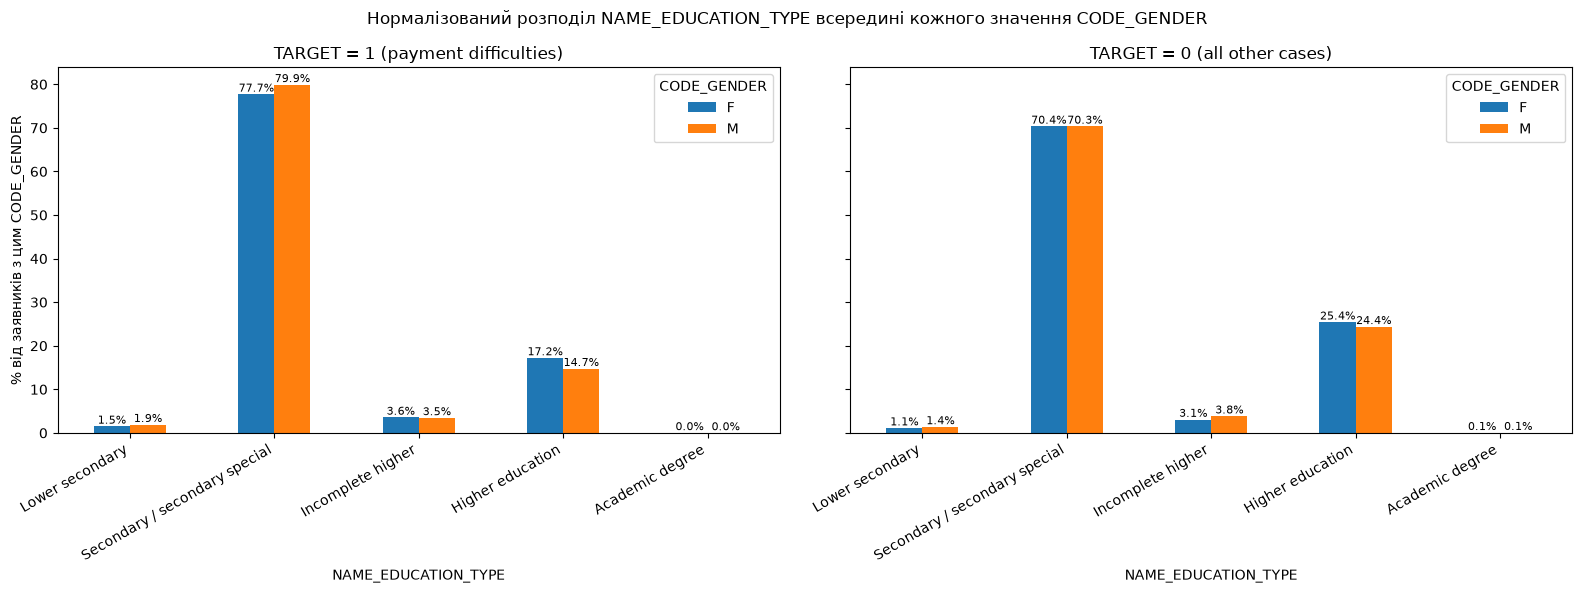

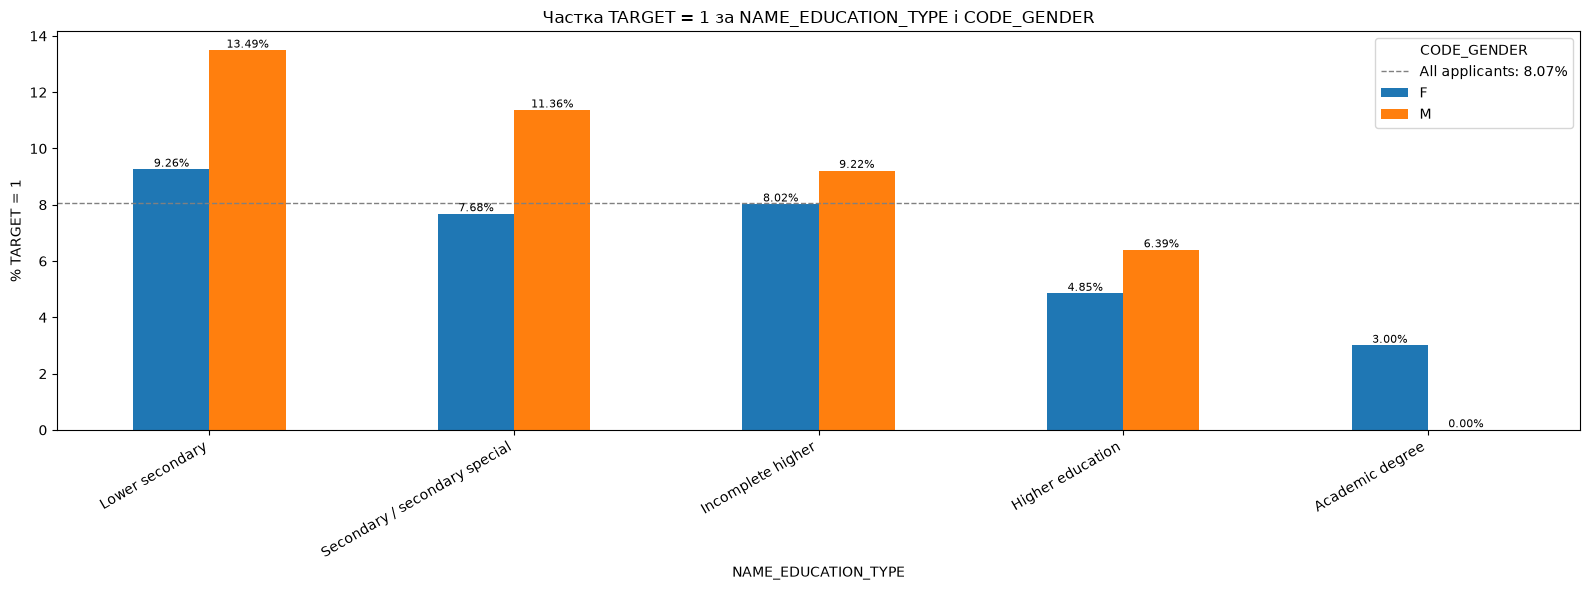

In [250]:
# рівні освіти - від нижчого до вищого
education_order = ['Lower secondary', 'Secondary / secondary special', 'Incomplete higher',
                   'Higher education', 'Academic degree']

# 4 заявників з XNA у CODE_GENDER (вище замінено на 'F') виключаємо: стать у них невідома
df_g = df.drop(index = gender_xna_idx)
df0_g, df1_g = df_g[df_g['TARGET'] == 0], df_g[df_g['TARGET'] == 1]
print(f'Заявників без XNA: {len(df_g):,}'.replace(',', ' '))

# Academic degree - лише 164 заявники (3 з TARGET = 1): для χ², V Крамера та IV об'єднуємо з сусіднім рівнем,
# інакше очікувані частоти в таблиці для TARGET = 1 менші за 5
edu_gender_stats, edu_gender_target, edu_gender_tests = bi_cat_target_analysis(
    df0_g, df1_g, 'NAME_EDUCATION_TYPE', 'CODE_GENDER', order = education_order,
    test_merge = {'Academic degree': 'Higher education'})

Як і в ДЗ 7, частина різниці між статями може пояснюватися не самою статтю, а віком і типом доходу: серед жінок більше пенсіонерок, і вони старші. Перевіримо частку пенсіонерів і медіанний вік у кожній комбінації освіти та статі і повторимо розрахунок частки `TARGET` = 1 лише для працюючих (`NAME_INCOME_TYPE` == 'Working', найбільша група). Розрив між статями для працюючих порівняємо з розривом для всіх заявників з таблиці `edu_gender_target`, яку повернула функція вище

In [251]:
# Частка пенсіонерів і медіанний вік у кожній комбінації освіти та статі, частка TARGET = 1 серед пенсіонерів
print('Кількість заявників, частка пенсіонерів (%) і медіанний вік за освітою і статтю, усі заявники')
display(df_g.groupby(['NAME_EDUCATION_TYPE', 'CODE_GENDER']).agg(
    count = ('TARGET', 'size'),
    pensioner_pct = ('NAME_INCOME_TYPE', lambda s: (s == 'Pensioner').mean() * 100),
    years_birth_median = ('YEARS_BIRTH', 'median')).reindex(education_order, level = 'NAME_EDUCATION_TYPE'))
print(f"Частка TARGET = 1: пенсіонери - {df_g.loc[df_g['NAME_INCOME_TYPE'] == 'Pensioner', 'TARGET'].mean() * 100:.2f}%, "
      f"працюючі - {df_g.loc[df_g['NAME_INCOME_TYPE'] == 'Working', 'TARGET'].mean() * 100:.2f}%")

# Частка TARGET = 1 (%) і кількість заявників лише для працюючих
working = df_g[df_g['NAME_INCOME_TYPE'] == 'Working']
working_target = working.pivot_table(index = 'NAME_EDUCATION_TYPE', columns = 'CODE_GENDER', values = 'TARGET',
                                     aggfunc = ['mean', 'size']).reindex(education_order)
working_target['mean'] = working_target['mean'] * 100
working_target[('mean', 'M - F, п.п.')] = working_target[('mean', 'M')] - working_target[('mean', 'F')]
# нова колонка додається в кінець, після size - ставимо різницю одразу після часток F і M
working_target = working_target[[('mean', 'F'), ('mean', 'M'), ('mean', 'M - F, п.п.'), ('size', 'F'), ('size', 'M')]]
working_target = working_target.rename(columns = {'mean': 'target_rate_pct', 'size': 'count'}, level = 0)
print('Частка TARGET = 1 (%) і кількість заявників лише для працюючих (Working)')
display(working_target)

# Розрив між статями (M - F, п.п.): усі заявники - з таблиці edu_gender_target, яку повернула
# bi_cat_target_analysis вище, працюючі - з working_target
gender_gap = 'M - F, п.п.'
print('Розрив між статями у частці TARGET = 1 (M - F, п.п.): усі заявники vs працюючі')
display(pd.DataFrame({'All applicants': edu_gender_target[gender_gap].reindex(education_order),
                      'Working': working_target[('target_rate_pct', gender_gap)]}))

Кількість заявників, частка пенсіонерів (%) і медіанний вік за освітою і статтю, усі заявники


count  pensioner_pct  \
NAME_EDUCATION_TYPE           CODE_GENDER                          
Lower secondary               F              2311          52.44   
                              M              1505          21.06   
Secondary / secondary special F            143465          26.06   
                              M             74924          10.30   
Incomplete higher             F              6283           6.32   
                              M              3993           3.03   
Higher education              F             50289          12.43   
                              M             24573           7.89   
Academic degree               F               100          22.00   
                              M                64           6.25   

                                           years_birth_median  
NAME_EDUCATION_TYPE           CODE_GENDER                      
Lower secondary               F                         57.00  
                              M                         40.00  
Secondary / secondary special F                         47.00  
                              M                         41.00  
Incomplete higher             F                         32.00  
                              M                         31.00  
Higher education              F                         40.00  
                              M                         39.00  
Academic degree               F                         44.50  
                              M                         41.00

Частка TARGET = 1: пенсіонери - 5.39%, працюючі - 9.59%
Частка TARGET = 1 (%) і кількість заявників лише для працюючих (Working)


target_rate_pct                    count       
CODE_GENDER                                 F     M M - F, п.п.      F      M
NAME_EDUCATION_TYPE                                                          
Lower secondary                         13.14 15.77        2.63    799    926
Secondary / secondary special            9.18 12.51        3.34  70306  47322
Incomplete higher                        8.91  9.77        0.85   3343   2242
Higher education                         5.60  7.27        1.68  22297  11464
Academic degree                          5.56  0.00       -5.56     36     36

Розрив між статями у частці TARGET = 1 (M - F, п.п.): усі заявники vs працюючі


,All applicants,Working
NAME_EDUCATION_TYPE,,
Lower secondary,4.23,2.63
Secondary / secondary special,3.69,3.34
Incomplete higher,1.19,0.85
Higher education,1.55,1.68
Academic degree,-3.00,-5.56


Цифри для спостережень, яких немає у виводах вище: частка жінок на кожному рівні освіти, розподіл освіти всередині статі для всіх заявників (у таблиці функції він є лише окремо для кожної групи `TARGET`), 95% довірчі інтервали різниці часток `TARGET` = 1 між `Incomplete higher` і `Secondary / secondary special` у жінок і медіанний вік працюючих

In [252]:
# 1. Частка жінок на кожному рівні освіти (рядок All - у всій вибірці) і розподіл освіти всередині статі
#    для всіх заявників разом
female_pct = pd.crosstab(df_g['NAME_EDUCATION_TYPE'], df_g['CODE_GENDER'], normalize = 'index',
                         margins = True, margins_name = 'All')['F'] * 100
edu_in_gender = pd.crosstab(df_g['NAME_EDUCATION_TYPE'], df_g['CODE_GENDER'], normalize = 'columns') * 100
print('Частка жінок на рівні освіти і розподіл освіти всередині статі (%), усі заявники')
display(pd.DataFrame({'female_pct': female_pct,
                      'pct_of_F': edu_in_gender['F'],
                      'pct_of_M': edu_in_gender['M']}).reindex(education_order + ['All']))


# 2. Різниця часток TARGET = 1 між двома рівнями освіти в межах однієї статі і наближений 95% ДІ
#    (нормальне наближення для різниці двох часток: diff ± 1.96 * sqrt(p1 (1 - p1) / n1 + p2 (1 - p2) / n2))
def target_rate_diff_ci(data, education_a, education_b, gender):
    rates = {}
    for education in (education_a, education_b):
        target = data.loc[(data['NAME_EDUCATION_TYPE'] == education) & (data['CODE_GENDER'] == gender), 'TARGET']
        rates[education] = (target.mean(), len(target))
    (p_a, n_a), (p_b, n_b) = rates[education_a], rates[education_b]
    diff, se = p_a - p_b, np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
    return {'count_a': n_a, 'rate_a_pct': p_a * 100, 'count_b': n_b, 'rate_b_pct': p_b * 100,
            'diff_pp': diff * 100, 'ci95_low_pp': (diff - 1.96 * se) * 100, 'ci95_high_pp': (diff + 1.96 * se) * 100}


print('Жінки: частка TARGET = 1 для Incomplete higher (a) мінус Secondary / secondary special (b), п.п.')
display(pd.DataFrame({
    name: target_rate_diff_ci(data, 'Incomplete higher', 'Secondary / secondary special', 'F')
    for name, data in {'All applicants': df_g, 'Working': working}.items()}).T.astype({'count_a': int, 'count_b': int}))

# 3. Медіанний вік працюючих за освітою і статтю
print('Медіанний вік працюючих (Working), років')
display(working.groupby(['NAME_EDUCATION_TYPE', 'CODE_GENDER'])['YEARS_BIRTH'].median().unstack().reindex(education_order))

Частка жінок на рівні освіти і розподіл освіти всередині статі (%), усі заявники


,female_pct,pct_of_F,pct_of_M
NAME_EDUCATION_TYPE,,,
Lower secondary,60.56,1.14,1.43
Secondary / secondary special,65.69,70.87,71.32
Incomplete higher,61.14,3.10,3.80
Higher education,67.18,24.84,23.39
Academic degree,60.98,0.05,0.06
All,65.84,NaN,NaN


Жінки: частка TARGET = 1 для Incomplete higher (a) мінус Secondary / secondary special (b), п.п.


,count_a,rate_a_pct,count_b,rate_b_pct,diff_pp,ci95_low_pp,ci95_high_pp
All applicants,6283,8.02,143465,7.68,0.35,-0.34,1.03
Working,3343,8.91,70306,9.18,-0.26,-1.25,0.73


Медіанний вік працюючих (Working), років


CODE_GENDER,F,M
NAME_EDUCATION_TYPE,,
Lower secondary,39.00,38.00
Secondary / secondary special,42.00,40.00
Incomplete higher,31.00,31.00
Higher education,38.00,37.00
Academic degree,42.50,39.00


**Спостереження**
- Аналіз зроблено для 307 507 заявників: пропусків в обох колонках немає, а 4 заявників з `XNA` у `CODE_GENDER` виключено, бо їхня стать невідома (у лекційній частині їх замінено на `F`, але для порівняння `F` і `M` це приписало б їм стать). З них 24 825 з `TARGET` = 1 і 282 682 з `TARGET` = 0. Рівні освіти далі названо як у даних (`Lower secondary`, `Incomplete higher`, `Academic degree`), крім двох найбільших: **середня освіта** - це `Secondary / secondary special`, **вища освіта** - `Higher education`.
- **Освіта і стать між собою майже не пов'язані.** Частка жінок на кожному рівні освіти - 61 - 67% (у всій вибірці - 65.8%), а розподіл освіти всередині статі майже однаковий: вища освіта - 24.8% жінок і 23.4% чоловіків, середня - 70.9% і 71.3%. V Крамера - **0.025 - 0.036** в обох групах `TARGET` і для всіх заявників (p-value дуже малий лише через великий розмір вибірки). Тобто освіта і стать - практично незалежні ознаки, і кожна може окремо давати інформацію про `TARGET`.
- **Освіта vs `TARGET`.** Що вищий рівень освіти, то менша частка `TARGET` = 1: `Lower secondary` - 10.93%, `Secondary / secondary special` - 8.94%, `Incomplete higher` - 8.49%, `Higher education` - 5.36%, `Academic degree` - 1.83%. Це видно і на першому графіку: серед `TARGET` = 1 частка вищої освіти помітно менша (17.2% жінок і 14.7% чоловіків), ніж серед `TARGET` = 0 (25.4% і 24.4%), а частка середньої - більша (77.7% і 79.9% проти 70.4% і 70.3%).
- **Стать vs `TARGET`.** У чоловіків частка `TARGET` = 1 вища, ніж у жінок, на **кожному** рівні освіти (крім `Academic degree`, див. нижче): `Lower secondary` - 13.49% проти 9.26% (+4.23 п.п.), `Secondary / secondary special` - 11.36% проти 7.68% (+3.69 п.п.), `Incomplete higher` - 9.22% проти 8.02% (+1.19 п.п.), `Higher education` - 6.39% проти 4.85% (+1.55 п.п.); загалом - 10.14% проти 7.00%. Водночас у групі з вищою освітою частка `TARGET` = 1 нижча, ніж у групі із середньою освітою, в обох статей: на 37% у жінок (7.68% → 4.85%) і на 44% у чоловіків (11.36% → 6.39%).
- **Сила зв'язку з `TARGET`.** V Крамера: освіта - 0.057, стать - 0.055, комбінація освіти і статі - **0.081**. V малий, але для бінарного незбалансованого `TARGET` (8% / 92%) він великим і не буває, тому за V зв'язок виглядає слабшим, ніж є насправді: частки `TARGET` = 1 у групах відрізняються суттєво. Lift (частка `TARGET` = 1 у групі, поділена на 8.07%) - від **0.60** у жінок з `Higher education` до **1.41** у чоловіків з `Secondary / secondary special` і **1.67** у чоловіків з `Lower secondary`, тобто ризик у цих групах відрізняється в 2.3 - 2.8 раза. Information Value: освіта - **0.050**, стать - **0.039**, комбінація - **0.088**. Усі значення - у діапазоні 0.02 - 0.1, тобто прогнозна сила **слабка, але не нульова**; комбінація близька до межі "середньої" (0.1). Те, що V і IV комбінації більші, не доводить, що ефекти статі та освіти додаються: таблиця для комбінації має 8 груп (`Academic degree` об'єднано з `Higher education`) замість 4 і 2, і χ² та IV можуть зрости вже через детальніше розбиття. Перевірити адитивність можна, порівнявши логістичні моделі з головними ефектами освіти і статі та з їх взаємодією `освіта × стать`.
- **Групи з найбільшою і найменшою часткою `TARGET` = 1.** Найвища - у чоловіків з `Lower secondary` (13.49%, але це лише 1 505 заявників) і з `Secondary / secondary special` (11.36%, 74 924 заявники - найбільша група з підвищеним ризиком, ~24% усіх заявників). Найнижча серед великих груп - у жінок з `Higher education` (4.85%, 50 289 заявниць) - у 2.3 раза нижча, ніж у чоловіків із середньою освітою.
- **`Incomplete higher` у жінок** - у вибірці частка `TARGET` = 1 трохи вища, ніж із середньою освітою (8.02% проти 7.68%), але різниця +0.35 п.п. статистично не значима: наближений 95% довірчий інтервал - від −0.34 до +1.03 п.п. і включає 0. Тому говорити, що у жінок частка не зменшується монотонно з рівнем освіти, не можна: на цих даних частки для `Incomplete higher` і середньої освіти у жінок не розрізняються. Якщо різниця все ж реальна, можливе пояснення - вік і тип доходу: жінки з `Incomplete higher` молоді (медіана - 32 роки) і серед них лише 6.3% пенсіонерок, а жінки із середньою освітою старші (47 років) і пенсіонерок серед них 26.1%; у пенсіонерів частка `TARGET` = 1 - 5.39% проти 9.59% у працюючих. Серед працюючих (`Working`) - 9.18% для середньої освіти і 8.91% для `Incomplete higher`, але ця різниця (−0.26 п.п., 95% ДІ від −1.25 до +0.73 п.п.) теж у межах випадкових коливань.
- **Чи не пояснюється різниця між статями пенсіонерками?** Серед жінок пенсіонерок більше на кожному рівні освіти (наприклад, у `Lower secondary` - 52.4% жінок проти 21.1% чоловіків, медіанний вік - 57 і 40 років). Але серед працюючих розрив між статями зберігається: `Secondary / secondary special` - +3.34 п.п. (12.51% проти 9.18%), `Higher education` - +1.68 п.п. (7.27% проти 5.60%), `Lower secondary` - +2.63 п.п. (15.77% проти 13.14%; для всіх заявників - 4.23 п.п.), `Incomplete higher` - +0.85 п.п. Отже, розрив між статями зберігається і серед працюючих, тобто його не можна пояснити лише часткою пенсіонерок. Фільтр `Working` враховує тип доходу, але не вік: серед працюючих із середньою освітою медіанний вік жінок - 42 роки, чоловіків - 40. Яку частину розриву пояснює вік, а яку - пенсія, з цих даних не видно (зменшення з 4.23 до 2.63 п.п. цього не показує); для цього треба порівнювати частки всередині вікових груп або враховувати вік у моделі.
- **`Academic degree` і спостереження з лекції.** У лекційній частині вище (розділ «Аналіз стовпців `AMT_CREDIT` vs `NAME_EDUCATION_TYPE` vs `CODE_GENDER`») сказано: "Чоловіки з академічним ступенем освіти (Academic degree) завжди сплачують вчасно". `Academic degree` - лише 164 заявники, з них 3 з `TARGET` = 1 (усі - жінки, 3.00%), у чоловіків - 0 з 64, тобто в цій вибірці немає жодного чоловіка з `Academic degree` і `TARGET` = 1. Тому в лекційній таблиці `df1.groupby(by = ['NAME_EDUCATION_TYPE','CODE_GENDER']).AMT_CREDIT.describe().head()` рядка `Academic degree` / `M` немає взагалі - звідси і "завжди". Але це не означає, що вони "завжди платять вчасно": `TARGET` = 0 за описом колонки - *all other cases*, тобто відсутність прострочки понад X днів на перших Y платежах. До того ж група замала: при 0 випадках з 64 за "правилом трьох" частка `TARGET` = 1 може бути до ~4.7% (верхня межа 95% довірчого інтервалу), тобто на рівні вищої освіти. Через малу групу очікувані частоти в таблиці освіта × стать для `TARGET` = 1 були б менші за 5 (`min_expected` = 1.29), і χ² для неї був би некоректним. Тому для χ², V Крамера та IV `Academic degree` об'єднано з сусіднім рівнем `Higher education` (після об'єднання найменша очікувана частота в усіх таблицях - 121.5); таблиці часток і графіки показують `Academic degree` окремо.
- У файлі лекції `1_Credit_EDA.ipynb` це спостереження сформульоване інакше - "Клієнти-чоловіки з "вищою освітою" завжди сплачують кредит вчасно". Таке твердження дані теж не підтверджують: серед чоловіків з `Higher education` **1 571 з 24 573** мають `TARGET` = 1 (6.39%).

**Висновок**
- `NAME_EDUCATION_TYPE` і `CODE_GENDER` між собою **практично незалежні** (V Крамера ≈ 0.03): структура освіти в жінок і чоловіків майже однакова.
- За V Крамера (0.055 - 0.057, для комбінації - 0.081) зв'язок з `TARGET` виглядає дуже слабким, але для незбалансованого `TARGET` V його занижує. За Information Value прогнозна сила слабка, але не нульова (освіта - 0.050, стать - 0.039, комбінація - 0.088; більше значення для комбінації не доводить, що ефекти додаються), а частки `TARGET` = 1 у групах відрізняються суттєво (lift від 0.60 до 1.67): в обох статей частка `TARGET` = 1 з вищою освітою помітно нижча, ніж із середньою (4.85% проти 7.68% у жінок, 6.39% проти 11.36% у чоловіків), а у жінок частки для `Incomplete higher` і середньої освіти статистично не розрізняються (8.02% проти 7.68%, 95% ДІ різниці включає 0), тому про немонотонність говорити не можна; у чоловіків частка вища, ніж у жінок, на кожному рівні освіти, крім `Academic degree` (0% у чоловіків проти 3.00% у жінок, але це лише 164 заявники). Розрив між статями зберігається і серед працюючих, тож пояснюється не лише більшою часткою пенсіонерок серед жінок.
- Найцікавіша знахідка щодо цільової змінної: серед груп за комбінацією освіти і статі без `Academic degree` (там 0% у чоловіків і 3.00% у жінок, але це лише 164 заявники) частка `TARGET` = 1 становить від **4.85%** у жінок з вищою освітою до **11.36 - 13.49%** у чоловіків із середньою освітою і `Lower secondary` (середнє для всіх - 8.07%). Для кредитного скорингу різниця у 2.3 - 2.8 раза суттєва, хоча прогнозна сила самих ознак за IV слабка (0.088 для комбінації). Це однофакторні порівняння: інші ознаки (вік, дохід, стаж тощо) тут не враховані, тому для рішень про кредит їх варто перевіряти разом з ними (ДЗ 9).
- Групу `Academic degree` (164 заявники) для висновків про `TARGET` використовувати не варто - вона замала.

***
# ДЗ 9. Висновок з проведеного аналізу
Напишіть Ваш висновок з проведеного ананлізу, яким категоріям осіб Ви б видали кредит? Категорія може бути, наприклад, люди з такою-то освітою, з таким-то доходом, з таким-то досвідом роботи.

# Висновок: Категорії клієнтів, на яких слід орієнтуватися при наданні кредиту


### Висновки ДЗ 9

**На чому базується висновок.** У датасеті 307 511 заявок, частка клієнтів з платіжними труднощами (`TARGET` = 1) - **8.07%**. Категорію вважаю надійнішою, якщо частка `TARGET` = 1 у ній помітно нижча за 8.07%, і ризикованішою - якщо помітно вища. Цифри за віком, стажем, освітою, статтю, автомобілем і ціною товару взяті з ДЗ 4 - 8. Цифри за типом доходу, професією, житлом, сімейним статусом, доходом і для комбінацій ознак пораховані додатково на тих самих даних тим самим способом (середнє `TARGET` у групі).

#### 1. Які ознаки заявника пов'язані з ризиком

| Ознака | Нижчий ризик (частка `TARGET` = 1) | Вищий ризик (частка `TARGET` = 1) |
|---|---|---|
| Вік (`YEARS_BIRTH`) | 51-60 років - 6.04%, 61-69 - **4.92%** | 21-30 років - **11.44%**, 31-40 - 9.43% |
| Стаж на поточному місці (`DAYS_EMPLOYED`) | 10-20 років - 5.51%, понад 20 - **4.19%** | до 3 років - **~11%** |
| Тип доходу (`NAME_INCOME_TYPE`) | `Pensioner` - 5.39%, `State servant` - 5.75% | `Working` - 9.59% |
| Освіта (`NAME_EDUCATION_TYPE`) | `Higher education` - **5.36%** | `Secondary / secondary special` - 8.94%, `Lower secondary` - 10.93% |
| Професія (`OCCUPATION_TYPE`) | `Accountants` - 4.83%, `High skill tech staff`, `Managers`, `Core staff` - 6.2 - 6.3% | `Laborers` - 10.58%, `Drivers` - 11.33%, `Low-skill Laborers` - **17.15%** |
| Житло (`NAME_HOUSING_TYPE`) | `House / apartment` - 7.80% (майже середня) | `With parents` - 11.70%, `Rented apartment` - 12.31% |
| Сімейний статус (`NAME_FAMILY_STATUS`) | `Widow` - 5.82%, `Married` - 7.56% | `Single / not married` - 9.81%, `Civil marriage` - 9.94% |
| Дохід (`AMT_INCOME_TOTAL`) | 225 000 - 337 500 - 6.82%, понад 337 500 - 5.81% | 90 000 - 180 000 - ~8.6% (майже середня) |
| Стать (`CODE_GENDER`) | жінки - 7.00% | чоловіки - 10.14% |
| Автомобіль (`FLAG_OWN_CAR`) | є - 7.24% | немає - 8.50% |

- Найсильніше частку `TARGET` = 1 змінюють **вік, стаж, освіта, тип доходу і професія**: між крайніми групами вона відрізняється у 2 - 3.5 раза.
- **Дохід сам по собі відрізняє слабко**: нижча частка лише у заявників з доходом понад 225 000 (15% заявників), а для решти вона близька до середньої (7.8 - 8.6%). Наявність нерухомості (`FLAG_OWN_REALTY`) майже нічого не змінює: 7.96% проти 8.32%.
- З характеристик самого кредиту: великі кредити надійніші (ціна товару понад 814 500 - 5.73%, ДЗ 5), а найвища частка - на ціні товару рівно 450 000 (13.74%, ДЗ 5).

#### 2. Яким категоріям я б видав кредит

1. **Людям старше 40 років з вищою освітою** - частка `TARGET` = 1 **4.70%** (35 771 заявник, 11.6% усіх). Якщо вони ще й працюють на поточному місці понад 5 років - **3.75%** (16 143 заявники), тобто більш ніж удвічі нижче за середню.
2. **Людям зі стажем на поточному місці понад 10 років** - 5.19% (50 954 заявники).
3. **Людям старше 50 років і пенсіонерам** - 5.68% (100 363 заявники) і 5.39%.
4. **Державним службовцям і кваліфікованим спеціалістам** (`State servant` - 5.75%; `Accountants`, `High skill tech staff`, `Managers`, `Core staff` разом - 6.05%, 70 134 заявники).
5. Додатковий плюс, але не окрема підстава: дохід понад 225 000 (6.52%), наявність автомобіля (7.24%), шлюб (7.56%).

Якщо об'єднати перші три категорії (старше 40 з вищою освітою, **або** стаж понад 10 років, **або** вік понад 50 років), це **47.8% усіх заявників з часткою `TARGET` = 1 5.68%**. У решти 52.2% заявників вона майже вдвічі вища - 10.26%.

#### 3. Кому я б видавав кредит з обережністю (додаткова перевірка, менша сума або застава)

- **Молодим людям до 30 років зі стажем на поточному місці до 3 років** - 12.38% (26 747 заявників). Якщо в них ще й середня освіта або нижче - **15.69%** (15 702 заявники), майже вдвічі вище за середню.
- **Робітничим професіям**: `Low-skill Laborers` - 17.15% (2 093 заявники), `Drivers` - 11.33%, `Laborers` - 10.58%.
- **Тим, хто живе з батьками або орендує житло** - 11.70% і 12.31%.
- Заявники без роботи (`Unemployed` - 36.36%) і в декретній відпустці (`Maternity leave` - 40.00%) мають найвищі частки, але це лише 22 і 5 заявників - для висновків замало.

Навіть у найризикованішій з великих груп (15.69%) понад 84% клієнтів не мають платіжних труднощів. Тому це категорії для уважнішої перевірки, а не для автоматичної відмови.

#### 4. Застереження

- Майже всі порівняння **однофакторні**, а ознаки пов'язані між собою (вік, стаж, пенсія, освіта і професія). Тому частки окремих груп не можна "складати": для комбінацій я рахував частку окремо (розділи 2 і 3).
- Це зв'язок у даних, а не доведена причина: наприклад, вища освіта може означати стабільнішу роботу і вищий дохід, а не впливати на платежі сама.
- **Стать** пов'язана з `TARGET` (7.00% проти 10.14%, ДЗ 4 і ДЗ 8), але як критерій видачі кредиту я б її не використовував: це дискримінаційна ознака, і в багатьох країнах її використання в скорингу заборонено.
- Малі групи для висновків не годяться: `Academic degree` (164 заявники), `Businessman` (10), `Student` (18).
- `TARGET` = 0 - це "всі інші випадки", а не гарантія вчасних платежів за весь строк кредиту.
- Остаточне рішення має ухвалювати скорингова модель, яка враховує всі ознаки разом. Цей аналіз показує, які ознаки для неї найкорисніші: вік, стаж, освіта, тип доходу і професія.